# UE Data Mining - Project

* Group project (group 10)

## Understanding and profiling of the raw data

Objective:
Audit the files of the public_record folder before any alteration, to map the variable types, the distributions, the true missing values (NaN) and the "false empties" (invisible spaces).

In [1]:
# IMPORT OF THE LIBRARIES


import pandas as pd


import numpy as np

import matplotlib.pyplot as plt

import difflib

from IPython.display import display

import os
import glob

def automated_data_profiling(csv_path):
    """
    SUMMARY:
    Universal scanner for Exploratory Data Analysis (EDA).
    Includes the detection of true/false empties, the automatic detection of the column types
    (Identifier, Date, Category), the spelling audit (fuzzy matching),
    the temporal audit and the visualisation.
    """
    file_name = csv_path.split('/')[-1]
    
    print(f"\nAUDIT OF FILE: {file_name}\n")
    
    # STEP 0: LOADING SAFETY
    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        print(f"Error while reading the file: {e}")
        return
        
    n_rows, n_cols = df.shape
    print(f"Dimensions: {n_rows} rows, {n_cols} columns\n")
    
    # STEP 1: STRICT DUPLICATES
    n_duplicates = df.duplicated().sum()
    print(f"Strict duplicates detected: {n_duplicates}")
    if n_duplicates > 0:
        print("[!] Action required later: consider df.drop_duplicates().\n")
    else:
        print("\n")
    
    # STEP 2: TRUE MISSING VALUES (system NaN)
    missing_data = df.isnull().sum()
    missing_percent = (missing_data / n_rows) * 100
    missing_df = pd.DataFrame({'True NaN': missing_data, 'Percentage (%)': missing_percent})
    missing_df = missing_df[missing_df['True NaN'] > 0].sort_values(by='Percentage (%)', ascending=False)
    
    print("1. System absences (true NaN)")
    if not missing_df.empty:
        display(missing_df.round(2))
    else:
        print("No true NaN detected.\n")
        
    # STEP 2-BIS: FALSE EMPTIES (spaces or empty texts)
    print("\n2. False empties (spaces or empty texts)")
    obj_cols = df.select_dtypes(include=['object']).columns
    if len(obj_cols) > 0:
        space_mask = df[obj_cols].apply(lambda col: col.map(lambda x: isinstance(x, str) and x.strip() == ''))
        space_counts = space_mask.sum()
        space_counts = space_counts[space_counts > 0]
        
        if not space_counts.empty:
            space_df = pd.DataFrame({
                'Spaces detected': space_counts, 
                'Percentage (%)': (space_counts / n_rows) * 100
            }).sort_values(by='Percentage (%)', ascending=False)
            display(space_df.round(2))
        else:
            print("No invisible space detected.\n")
    else:
        print("No text column to analyse.\n")
        
    # STEP 3: NUMERIC STATISTICS
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    if len(numeric_cols) > 0:
        print("\n3. Numeric statistics")
        display(df[numeric_cols].describe().round(2))
        
    # STEP 4: AUDIT OF THE TEXT VARIABLES (dynamic routing)
    if len(obj_cols) > 0:
        print("\n4. Statistics of the text variables")
        
        for col in obj_cols:
            print(f"\nAnalysis of column: {col}")
            
            clean_unique_values = df[col].dropna().astype(str).unique()
            n_unique = len(clean_unique_values)
            
            # ROUTE 1: DETECTION OF IDENTIFIERS
            id_keywords = ['id', 'number', 'code', 'ref']
            is_id = (n_unique == df[col].dropna().count()) or any(k in col.lower() for k in id_keywords)
            
            if is_id:
                print("Detected type: UNIQUE IDENTIFIER")
                print(f"{n_unique} unique values. Spelling audit useless.")
                continue # Move on to the next column
                
            # ROUTE 2: DETECTION OF DATES
            date_keywords = ['date', 'start', 'end', 'time']
            is_date = any(k in col.lower() for k in date_keywords)
            
            if is_date:
                print("Detected type: TEMPORAL VARIABLE (Date)")
                
                # 2a. Audit of the formats
                skeletons = df[col].dropna().astype(str).str.replace(r'\d', 'X', regex=True).value_counts()
                for fmt, count in skeletons.items():
                    print(f" - Format '{fmt}': {count} occurrence(s)")
                if len(skeletons) > 1:
                    print(" [!] Warning: mix of formats detected.")
                
                # 2b. Audit of the temporal limits
                temp_dates = pd.to_datetime(df[col], errors='coerce', format='mixed', dayfirst=True)
                if not temp_dates.dropna().empty:
                    date_min = temp_dates.min()
                    date_max = temp_dates.max()
                    print(f" - Range: from {date_min.strftime('%Y-%m-%d')} to {date_max.strftime('%Y-%m-%d')}")
                    
                    if date_min.year < 1900 or date_max.year > 2026:
                        print(" [!] Anomaly: dates out of bounds (before 1900 or in the future).")
                continue # Move on to the next column
                
            # ROUTE 3: STANDARD CATEGORIES (Fuzzy Matching)
            print(f"Detected type: NOMINAL CATEGORY ({n_unique} unique values)")
            val_counts = df[col].dropna().astype(str).value_counts().sort_index()
            
            for val, count in val_counts.head(100).items():
                print(f" - '{val}': {count} occurrence(s)")
            if n_unique > 100:
                print(" - ... (rest hidden, more than 100 categories)")
            
            if 1 < n_unique < 500:
                groups = []
                processed_values = set()
                
                for word in clean_unique_values:
                    if word not in processed_values:
                        similar = difflib.get_close_matches(word, clean_unique_values, n=10, cutoff=0.85)
                        if len(similar) > 1:
                            groups.append(similar)
                        processed_values.update(similar)
                
                if groups:
                    print(f"\n [!] Spelling variants detected (false positives possible):")
                    similar_rows = []
                    for i, groupe in enumerate(groups):
                        for word in groupe:
                            similar_rows.append({'Value': word, 'Group_ID': i})
                            
                    df_sim = pd.DataFrame(similar_rows)
                    colors = ['#ffb3ba', '#ffdfba', '#ffffba', '#baffc9', '#bae1ff', '#e8baff']
                    
                    def color_group(row):
                        color = colors[row['Group_ID'] % len(colors)]
                        return [f'background-color: {color}; color: black; font-weight: bold'] * len(row)
                    
                    display(df_sim.style.apply(color_group, axis=1).hide(axis="index"))
                    
    # STEP 5: FINAL VISUALISATION
    if not missing_percent[missing_percent > 0].empty:
        plt.figure(figsize=(8, 4))
        missing_percent[missing_percent > 0].sort_values().plot(kind='barh', color='coral', edgecolor='black')
        plt.xlabel('Percentage of true NaN (%)')
        plt.ylabel('Columns')
        plt.title(f'Rate of missing values (NaN): {file_name}')
        plt.tight_layout()
        plt.show()

Application to public_appointments.csv


AUDIT OF FILE: public_appointments.csv

Dimensions: 62 rows, 12 columns

Strict duplicates detected: 0


1. System absences (true NaN)


,True NaN,Percentage (%)
appointment_end,34,54.84
departure_reason,34,54.84
recorded_birth_year,9,14.52



2. False empties (spaces or empty texts)
No invisible space detected.


3. Numeric statistics


C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


,recorded_birth_year
count,53.00
mean,1968.08
std,15.08
min,1935.00
25%,1960.00
50%,1970.00
75%,1978.00
max,1993.00



4. Statistics of the text variables

Analysis of column: appointment_record_id
Detected type: UNIQUE IDENTIFIER
62 unique values. Spelling audit useless.

Analysis of column: appointing_jurisdiction
Detected type: NOMINAL CATEGORY (4 unique values)
 - 'Aveloran': 18 occurrence(s)
 - 'Kintaran': 20 occurrence(s)
 - 'Tembaran': 11 occurrence(s)
 - 'Valennan': 13 occurrence(s)

Analysis of column: office_holder_name
Detected type: NOMINAL CATEGORY (50 unique values)
 - 'Alina Wessen': 1 occurrence(s)
 - 'Amara Senn': 1 occurrence(s)
 - 'Bela Waren': 1 occurrence(s)
 - 'Bela Wessen': 1 occurrence(s)
 - 'Calen Uren': 1 occurrence(s)
 - 'Daria Maren': 2 occurrence(s)
 - 'Doran Maren': 1 occurrence(s)
 - 'Doran Orsen': 1 occurrence(s)
 - 'Doran Uren': 1 occurrence(s)
 - 'Dr. Lysa Quen': 1 occurrence(s)
 - 'Elian Cevan': 1 occurrence(s)
 - 'Elira Vaun': 3 occurrence(s)
 - 'Farah Ferran': 1 occurrence(s)
 - 'Faris Quell': 1 occurrence(s)
 - 'Halen Wessen': 1 occurrence(s)
 - 'Hana Wessen': 1 o

... (2 outputs left out)

Value,Group_ID
Council president,0
Council vice-president,0



Analysis of column: institution_name
Detected type: NOMINAL CATEGORY (9 unique values)
 - '  Avelora  Ministry  of  Strategic  Resources ': 1 occurrence(s)
 - 'Avelora Agricultural Resilience Agency': 10 occurrence(s)
 - 'Avelora Council of State': 10 occurrence(s)
 - 'Avelora Ministry of Strategic Resources': 9 occurrence(s)
 - 'Kintara Cave and Pollinator Authority': 6 occurrence(s)
 - 'Office of the Kintara Chancellor': 6 occurrence(s)
 - 'Orison Medical Audit Board': 9 occurrence(s)
 - 'Tembara Biodiversity Service': 5 occurrence(s)
 - 'Tembara Coastal Administration': 6 occurrence(s)

 [!] Spelling variants detected (false positives possible):


Value,Group_ID
Avelora Ministry of Strategic Resources,0
Avelora Ministry of Strategic Resources,0



Analysis of column: appointment_start
Detected type: TEMPORAL VARIABLE (Date)
 - Format 'XXXX-XX-XX': 61 occurrence(s)
 - Format 'XX/XX/XXXX': 1 occurrence(s)
 [!] Warning: mix of formats detected.
 - Range: from 1965-01-01 to 2021-01-01

Analysis of column: appointment_end
Detected type: TEMPORAL VARIABLE (Date)
 - Format 'XXXX-XX-XX': 28 occurrence(s)
 - Range: from 1979-12-31 to 2024-12-31

Analysis of column: appointment_basis
Detected type: NOMINAL CATEGORY (1 unique values)
 - 'appointed': 62 occurrence(s)

Analysis of column: departure_reason
Detected type: NOMINAL CATEGORY (3 unique values)
 - 'deceased': 1 occurrence(s)
 - 'retired': 3 occurrence(s)
 - 'role_transition': 24 occurrence(s)

Analysis of column: official_region
Detected type: NOMINAL CATEGORY (4 unique values)
 - 'Aveloran': 18 occurrence(s)
 - 'Kintaran': 20 occurrence(s)
 - 'Tembaran': 11 occurrence(s)
 - 'Valennan': 13 occurrence(s)

Analysis of column: source_notice_reference
Detected type: UNIQUE IDENTIFIER


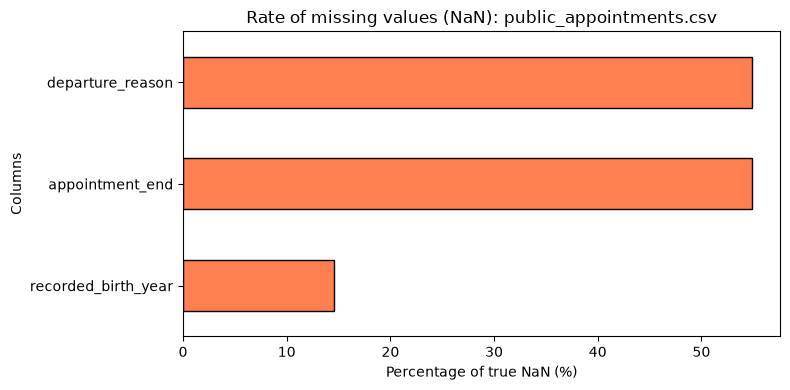

In [2]:
automated_data_profiling('../../data/public_records/public_appointments.csv')

#### Audit summary: `public_appointments.csv` (62 rows, 12 columns)

* **Integrity and duplicates:** No strict duplicate and no "false empty" (string made only of spaces) is present.
* **Missing values (`NaN`):**
  * `appointment_end` (34 NaN, i.e. **54.84%**) and `departure_reason` (34 NaN, i.e. **54.84%**): these absences are perfectly symmetric. From a business point of view, they do not represent a loss of information but indicate that **the public mandate is still active** (ongoing). The absence of information is information in itself.
  * `recorded_birth_year` (9 NaN, i.e. **14.52%**): birth years missing for 9 office holders (`Elira Vaun`, `Mirek Talven`, `Nora Yorin`, `Faris Quell`, `Bela Wessen`, `Marek Kerin`, `Kellan Orell`, `Farah Ferran`, `Petra Koral`). During the cleaning, we will check whether these people appear on other rows (intra-table imputation) or in other administrative files (inter-table imputation).
* **Formatting and text inconsistencies:**
  * **Stray spaces:** In `institution_name`, the category `'  Avelora  Ministry  of  Strategic  Resources '` (1 occurrence) is separated from `'Avelora Ministry of Strategic Resources'` (9 occurrences) because of multiple and leading/trailing spaces.
  * **Typos or namesakes (`difflib`):** The *fuzzy matching* flags close surnames (`Doran Uren` / `Doran Orsen` / `Doran Maren`, as well as `Halen Wessen` / `Hana Wessen`). False positives: these are distinct individuals sharing common names or first names in these fictional regions. We will not merge them.
* **Temporal variables:**
  * The `appointment_start` column mixes two formats: `XXXX-XX-XX` (61 rows) and `XX/XX/XXXX` (1 row: `01/01/1974` for *Mirek Talven*). Overall range: from `1965-01-01` to `2021-01-01`.


AUDIT OF FILE: registered_entities.csv

Dimensions: 24 rows, 10 columns

Strict duplicates detected: 0


1. System absences (true NaN)


,True NaN,Percentage (%)
parent_registration_number,24,100.0



2. False empties (spaces or empty texts)
No invisible space detected.


3. Numeric statistics


C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


,parent_registration_number
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN



4. Statistics of the text variables

Analysis of column: registration_number
Detected type: UNIQUE IDENTIFIER
24 unique values. Spelling audit useless.

Analysis of column: legal_name
Detected type: UNIQUE IDENTIFIER
24 unique values. Spelling audit useless.

Analysis of column: registered_entity_type
Detected type: NOMINAL CATEGORY (13 unique values)
 - 'activist_organization': 2 occurrence(s)
 - 'agricultural_company': 1 occurrence(s)
 - 'biotechnology_company': 1 occurrence(s)
 - 'consulting_company': 4 occurrence(s)
 - 'energy_company': 1 occurrence(s)
 - 'financial_institution': 1 occurrence(s)
 - 'foundation': 2 occurrence(s)
 - 'investment_company': 1 occurrence(s)
 - 'legal_organization': 1 occurrence(s)
 - 'logistics_company': 3 occurrence(s)
 - 'media_organization': 1 occurrence(s)
 - 'research_institute': 5 occurrence(s)
 - 'trade_association': 1 occurrence(s)

Analysis of column: registration_date
Detected type: TEMPORAL VARIABLE (Date)
 - Format 'XXXX-XX-XX': 24 occurrenc

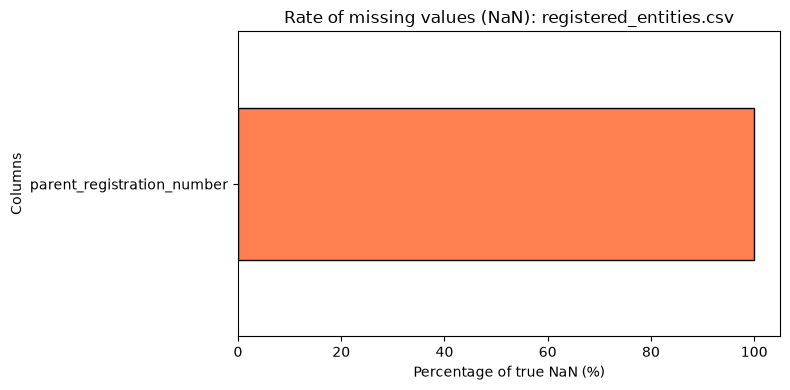


AUDIT OF FILE: officer_filings.csv

Dimensions: 136 rows, 12 columns

Strict duplicates detected: 1
[!] Action required later: consider df.drop_duplicates().

1. System absences (true NaN)


,True NaN,Percentage (%)
cessation_date,77,56.62



2. False empties (spaces or empty texts)
No invisible space detected.


4. Statistics of the text variables

Analysis of column: filing_id
Detected type: UNIQUE IDENTIFIER
135 unique values. Spelling audit useless.

Analysis of column: registration_number
Detected type: UNIQUE IDENTIFIER
24 unique values. Spelling audit useless.

Analysis of column: officer_local_ref
Detected type: UNIQUE IDENTIFIER
104 unique values. Spelling audit useless.

Analysis of column: full_name
Detected type: NOMINAL CATEGORY (105 unique values)
 - '  Pavel  Waren ': 1 occurrence(s)
 - 'Adrian Vosmere': 1 occurrence(s)
 - 'Adrienne Solva': 3 occurrence(s)
 - 'Alina Istra': 2 occurrence(s)
 - 'Amina Elen': 1 occurrence(s)
 - 'Amina Soren': 1 occurrence(s)
 - 'Anika Dren': 1 occurrence(s)
 - 'Arden Aster': 1 occurrence(s)
 - 'Bela Belen': 1 occurrence(s)
 - 'Bela Cevan': 2 occurrence(s)
 - 'Bela Ferran': 2 occurrence(s)
 - 'Bela Waren': 1 occurrence(s)
 - 'Bran Elen': 1 occurrence(s)
 - 'Bran Grell': 2 occurr

C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


Value,Group_ID
Liora Maren,0
Liora Uren,0
Jora Maren,0
Calen Uren,1
Calen Jaren,1
Calen Garen,1
Wira Soren,2
Miran Soren,2
Doran Maren,3
Jora Maren,3



Analysis of column: birth_year_or_age_band
Detected type: NOMINAL CATEGORY (50 unique values)
 - '1815': 1 occurrence(s)
 - '1862': 1 occurrence(s)
 - '1871': 1 occurrence(s)
 - '1900': 1 occurrence(s)
 - '1920–1929': 1 occurrence(s)
 - '1940–1949': 2 occurrence(s)
 - '1946': 3 occurrence(s)
 - '1949': 1 occurrence(s)
 - '1950': 1 occurrence(s)
 - '1950–1959': 7 occurrence(s)
 - '1952': 2 occurrence(s)
 - '1956': 5 occurrence(s)
 - '1958': 3 occurrence(s)
 - '1960': 1 occurrence(s)
 - '1960–1969': 8 occurrence(s)
 - '1961': 2 occurrence(s)
 - '1962': 5 occurrence(s)
 - '1963': 1 occurrence(s)
 - '1964': 2 occurrence(s)
 - '1965': 2 occurrence(s)
 - '1966': 6 occurrence(s)
 - '1968': 2 occurrence(s)
 - '1969': 1 occurrence(s)
 - '1970': 1 occurrence(s)
 - '1970–1979': 8 occurrence(s)
 - '1971': 3 occurrence(s)
 - '1972': 3 occurrence(s)
 - '1973': 3 occurrence(s)
 - '1974': 4 occurrence(s)
 - '1975': 2 occurrence(s)
 - '1976': 2 occurrence(s)
 - '1977': 1 occurrence(s)
 - '1978': 7 occ

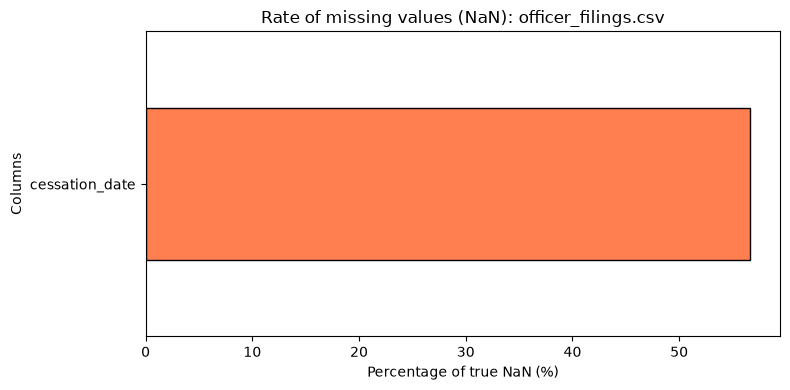

In [3]:
automated_data_profiling('../../data/public_records/registered_entities.csv')
automated_data_profiling('../../data/public_records/officer_filings.csv')

#### Audit summary: `registered_entities.csv` (24 rows, 10 columns) & `officer_filings.csv` (136 rows, 12 columns)

1. **Analysis of `registered_entities.csv` (register of legal entities):**
   * **100% empty column:** `parent_registration_number` contains 24 `NaN` (**100%**), so Pandas types it as `float64` by default. No official subsidiary is therefore declared through this key in the register.
   * **Status and timeline:** Of the 24 registered entities, 18 have the status `'active'` and 6 have the status `'dissolved'`. We note an unusual historical span for the registration dates (`registration_date`), which range from **`1838-01-15`** to **`2015-01-15`** (homogeneous format `XXXX-XX-XX`). The 6 dissolved structures are all historical entities registered between 1838 and 1969 (`Vann Maritime Advisory`, `Varlan Natural History Circle`, `Warden Medical Ventures`, `Bell Conservation Survey`, `Vosmere Biotechnics`, `Marot Ecological Policy Office`).

2. **Analysis of `officer_filings.csv` (filings of officers and executives):**
   * **Strict duplicate:** **1 exact duplicate** detected (identifier `FLG-000053`, concerning *Nadia Aren* at `REG-VLN-01004`, duplicated at indexes 52 and 135). To be removed with `drop_duplicates()`.
   * **Missing values:** `cessation_date` has 77 `NaN` (**56.62%**), which corresponds exactly to the **77 rows** with `filing_status == 'active'` (the 59 other rows with the status `'historical'` all have an end date).
   * **Formatting anomalies:**
     * In `full_name`, `'  Pavel  Waren '` contains stray spaces at the start/end and in the middle.
     * In `birth_year_or_age_band`, the format is heterogeneous (50 unique categories): some rows give an exact year (`'1978'`, `'1986'`), while others give a decade band (`'1960–1969'`, `'1970–1979'`).
     * In `appointment_date`, we observe a mix of formats: 135 occurrences in `XXXX-XX-XX` and 1 occurrence in `XXXX/XX/XX` (`1986/01/01` for *Kira Norel*). The appointments also cover a very long period: from **`1840-01-01`** (*Edward Vann*, born in 1815) to **`2026-01-01`**.


AUDIT OF FILE: licensed_professionals.csv

Dimensions: 53 rows, 10 columns

Strict duplicates detected: 0


1. System absences (true NaN)


,True NaN,Percentage (%)
license_expiry_date,53,100.00
primary_facility_license,26,49.06



2. False empties (spaces or empty texts)
No invisible space detected.


3. Numeric statistics


C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


,license_expiry_date
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN



4. Statistics of the text variables

Analysis of column: license_number
Detected type: UNIQUE IDENTIFIER
53 unique values. Spelling audit useless.

Analysis of column: professional_name
Detected type: UNIQUE IDENTIFIER
53 unique values. Spelling audit useless.

Analysis of column: profession
Detected type: NOMINAL CATEGORY (5 unique values)
 - 'environmental professional': 10 occurrence(s)
 - 'legal professional': 5 occurrence(s)
 - 'physician': 8 occurrence(s)
 - 'public administration professional': 21 occurrence(s)
 - 'research professional': 9 occurrence(s)

Analysis of column: specialty
Detected type: NOMINAL CATEGORY (16 unique values)
 - '  environmental  assessment ': 1 occurrence(s)
 - 'cardiac imaging': 1 occurrence(s)
 - 'cardiology': 2 occurrence(s)
 - 'clinical physiology': 1 occurrence(s)
 - 'clinical research': 2 occurrence(s)
 - 'ecological analytics': 1 occurrence(s)
 - 'environmental assessment': 5 occurrence(s)
 - 'general medicine': 1 occurrence(s)
 - 'medical audi

Value,Group_ID
environmental assessment,0
environmental assessment,0



Analysis of column: license_issue_date
Detected type: TEMPORAL VARIABLE (Date)
 - Format 'XXXX-XX-XX': 52 occurrence(s)
 - Format 'XX/XX/XXXX': 1 occurrence(s)
 [!] Warning: mix of formats detected.
 - Range: from 1886-01-07 to 2026-01-07
 [!] Anomaly: dates out of bounds (before 1900 or in the future).

Analysis of column: license_status
Detected type: NOMINAL CATEGORY (1 unique values)
 - 'active': 53 occurrence(s)

Analysis of column: primary_facility_license
Detected type: NOMINAL CATEGORY (3 unique values)
 - 'FAC-AVL-201': 2 occurrence(s)
 - 'FAC-AVL-301': 19 occurrence(s)
 - 'FAC-VLN-101': 6 occurrence(s)

 [!] Spelling variants detected (false positives possible):


Value,Group_ID
FAC-AVL-201,0
FAC-AVL-301,0



Analysis of column: registered_region
Detected type: NOMINAL CATEGORY (5 unique values)
 - 'Aveloran': 17 occurrence(s)
 - 'Kintaran': 9 occurrence(s)
 - 'Nordhaven': 5 occurrence(s)
 - 'Tembaran': 8 occurrence(s)
 - 'Valennan': 14 occurrence(s)

Analysis of column: disciplinary_status
Detected type: NOMINAL CATEGORY (2 unique values)
 - 'none': 50 occurrence(s)
 - 'resolved administrative review': 3 occurrence(s)


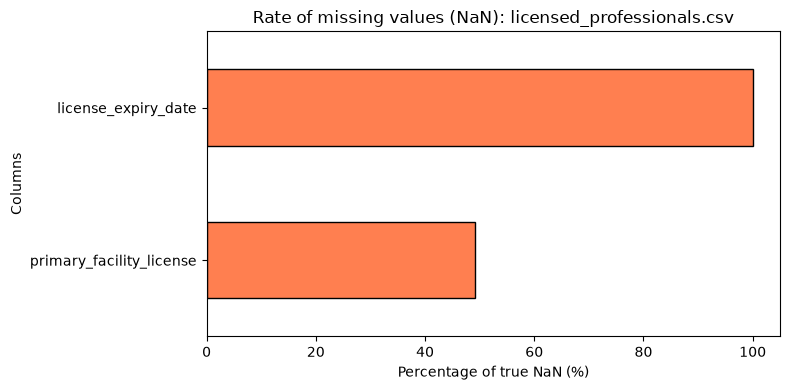


AUDIT OF FILE: licensed_facilities.csv

Dimensions: 3 rows, 12 columns

Strict duplicates detected: 0


1. System absences (true NaN)


,True NaN,Percentage (%)
license_end,3,100.0



2. False empties (spaces or empty texts)
No invisible space detected.


3. Numeric statistics


C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


,latitude,longitude,license_end
count,3.00,3.00,0.0
mean,20.68,70.29,NaN
std,22.96,54.37,NaN
min,7.35,7.51,NaN
25%,7.42,54.57,NaN
50%,7.50,101.62,NaN
75%,27.35,101.68,NaN
max,47.20,101.75,NaN



4. Statistics of the text variables

Analysis of column: facility_license_number
Detected type: UNIQUE IDENTIFIER
3 unique values. Spelling audit useless.

Analysis of column: facility_name
Detected type: UNIQUE IDENTIFIER
3 unique values. Spelling audit useless.

Analysis of column: facility_category
Detected type: UNIQUE IDENTIFIER
3 unique values. Spelling audit useless.

Analysis of column: operating_organization_registration
Detected type: NOMINAL CATEGORY (2 unique values)
 - 'REG-AVL-01007': 1 occurrence(s)
 - 'REG-VLN-01002': 2 occurrence(s)

Analysis of column: street_address
Detected type: UNIQUE IDENTIFIER
3 unique values. Spelling audit useless.

Analysis of column: region
Detected type: NOMINAL CATEGORY (2 unique values)
 - 'Avelora Federation': 2 occurrence(s)
 - 'Valenne Republic': 1 occurrence(s)

Analysis of column: license_start
Detected type: UNIQUE IDENTIFIER
3 unique values. Spelling audit useless.

Analysis of column: facility_status
Detected type: NOMINAL CATEGO

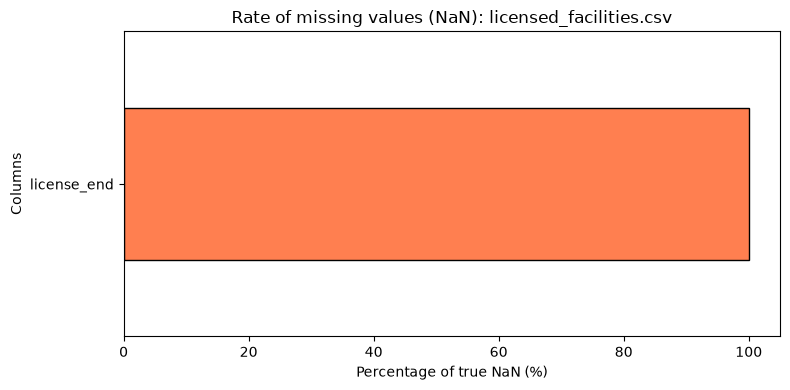

In [4]:
automated_data_profiling('../../data/public_records/licensed_professionals.csv')
automated_data_profiling('../../data/public_records/licensed_facilities.csv')

#### Audit summary: `licensed_professionals.csv` (53 rows, 10 columns) & `licensed_facilities.csv` (3 rows, 12 columns)

1. **Analysis of `licensed_professionals.csv` (accredited professionals):**
   * **Missing values:**
     * `license_expiry_date` is **100%** empty (53 `NaN`), consistent with `license_status` being `'active'` for all 53 professionals.
     * `primary_facility_license` is **49.06%** empty (26 `NaN`): only 27 professionals are attached to an accredited physical facility (`FAC-AVL-301` with 19 people, `FAC-VLN-101` with 6 people, and `FAC-AVL-201` with 2 people).
   * **Text and temporal anomalies:**
     * In `specialty`, one row contains superfluous spaces: `'  environmental  assessment '` (instead of `'environmental assessment'`).
     * In `license_issue_date`, mix of formats (`XXXX-XX-XX` on 52 rows, `XX/XX/XXXX` on 1 row: `01/07/1994` for *Doran Maren*).
     * **Major anomaly on the time range:** the license issue dates go from **`1886-07-01`** to **`2026-07-01`**, whereas **all** these licenses are marked `'active'`! In particular, licenses issued in 1886 (*J. Varlan*), 1895 (*Emil Warden*) and 1924 (*Jonah Bell*) are still active, and one license is dated `2026-07-01` (*Farah Havel*).
   * **Disciplinary signals:** 50 professionals have `disciplinary_status == 'none'`, but **3 individuals** stand out with `'resolved administrative review'`: *Liora Maren*, *Jalen Quorin* and *Uma Wessen*.

2. **Analysis of `licensed_facilities.csv` (accredited facilities):**
   * Very clean file of 3 active facilities (`license_end` 100% `NaN`):
     * `FAC-VLN-101`: *Asterion Central Clinical Campus* (`research_hospital`, operated by `REG-VLN-01002` *Asterion Clinical Institute*).
     * `FAC-AVL-201`: *Asterion Avelora Executive Clinic* (`private_clinic`, also operated by `REG-VLN-01002`).
     * `FAC-AVL-301`: *Threshold Earth Avelora Laboratory* (`research_laboratory`, operated by `REG-AVL-01007` *Threshold Earth Observatory*).
   * This file contains geographic coordinates (`latitude`, `longitude`) that will be valuable for the spatial part.


AUDIT OF FILE: site_access_case_events.csv

Dimensions: 413 rows, 15 columns

Strict duplicates detected: 1
[!] Action required later: consider df.drop_duplicates().

1. System absences (true NaN)


,True NaN,Percentage (%)
requesting_registration_number,65,15.74
authorized_person_name,2,0.48



2. False empties (spaces or empty texts)
No invisible space detected.


4. Statistics of the text variables

Analysis of column: access_event_id
Detected type: UNIQUE IDENTIFIER
412 unique values. Spelling audit useless.

Analysis of column: access_case_number
Detected type: UNIQUE IDENTIFIER
60 unique values. Spelling audit useless.

Analysis of column: site_code
Detected type: UNIQUE IDENTIFIER
50 unique values. Spelling audit useless.

Analysis of column: event_time
Detected type: TEMPORAL VARIABLE (Date)
 - Format 'XXXX-XX-XXTXX:XX:XX': 410 occurrence(s)
 - Format 'XX-Sep-XXXX XX:XX:XX': 1 occurrence(s)
 - Format 'XXXX/XX/XX XX:XX:XX': 1 occurrence(s)
 - Format 'XX-Feb-XXXX XX:XX:XX': 1 occurrence(s)
 [!] Warning: mix of formats detected.
 - Range: from 2015-01-03 to 2025-12-06

Analysis of column: activity
Detected type: NOMINAL CATEGORY (11 unique values)
 - 'ACCESS_COMPLETED': 1 occurrence(s)
 - 'REQUEST_SUBMITTED': 2 occurrence(s)
 - 'access_completed': 53 occurrence(s)
 - 'ac

Detected type: UNIQUE IDENTIFIER
25 unique values. Spelling audit useless.

Analysis of column: authorizing_agency
Detected type: NOMINAL CATEGORY (3 unique values)
 - 'Avelora Agricultural Resilience Agency': 181 occurrence(s)
 - 'Kintara Cave and Pollinator Authority': 175 occurrence(s)
 - 'Tembara Biodiversity Service': 57 occurrence(s)

Analysis of column: authorized_person_name
Detected type: NOMINAL CATEGORY (47 unique values)
 - 'Amina Elen': 9 occurrence(s)
 - 'Anika Dren': 5 occurrence(s)
 - 'Bela Ferran': 12 occurrence(s)
 - 'Bela Waren': 5 occurrence(s)
 - 'Bela Wessen': 9 occurrence(s)
 - 'Calen Jaren': 4 occurrence(s)
 - 'Calen Uren': 9 occurrence(s)
 - 'Daria Garen': 10 occurrence(s)
 - 'Daria Maren': 5 occurrence(s)
 - 'Daria Zaven': 9 occurrence(s)
 - 'Doran Maren': 6 occurrence(s)
 - 'Doran Norel': 1 occurrence(s)
 - 'Doran Wessen': 11 occurrence(s)
 - 'Elira Vaun': 9 occurrence(s)
 - 'Farah Ferran': 15 occurrence(s)
 - 'Farah Norel': 8 occurrence(s)
 - 'Halen Wessen':

C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


Value,Group_ID
Jalen Quorin,0
Jalen Zorin,0
Calen Uren,1
Calen Jaren,1
Liora Uren,2
Liora Maren,2
Daria Maren,3
Daria Garen,3


... (3 outputs left out)

Value,Group_ID
submitted,0
resubmitted,0



Analysis of column: new_status
Detected type: NOMINAL CATEGORY (11 unique values)
 - 'active': 54 occurrence(s)
 - 'authorized': 54 occurrence(s)
 - 'closed': 61 occurrence(s)
 - 'completed': 54 occurrence(s)
 - 'denied': 6 occurrence(s)
 - 'resubmitted': 3 occurrence(s)
 - 'returned': 3 occurrence(s)
 - 'security_review': 12 occurrence(s)
 - 'submitted': 60 occurrence(s)
 - 'technical_review': 60 occurrence(s)
 - 'wildlife_review': 46 occurrence(s)

 [!] Spelling variants detected (false positives possible):


Value,Group_ID
submitted,0
resubmitted,0



Analysis of column: confidentiality_class
Detected type: UNIQUE IDENTIFIER
3 unique values. Spelling audit useless.

Analysis of column: outcome
Detected type: NOMINAL CATEGORY (12 unique values)
 - 'access commenced': 54 occurrence(s)
 - 'access denied': 6 occurrence(s)
 - 'additional conditions required': 3 occurrence(s)
 - 'authorization issued': 54 occurrence(s)
 - 'case closed': 61 occurrence(s)
 - 'conditions updated': 3 occurrence(s)
 - 'field work completed': 18 occurrence(s)
 - 'request logged': 60 occurrence(s)
 - 'site-security conditions recorded': 12 occurrence(s)
 - 'technical review completed': 60 occurrence(s)
 - 'wildlife conditions recorded': 46 occurrence(s)
 - 'work completed': 36 occurrence(s)


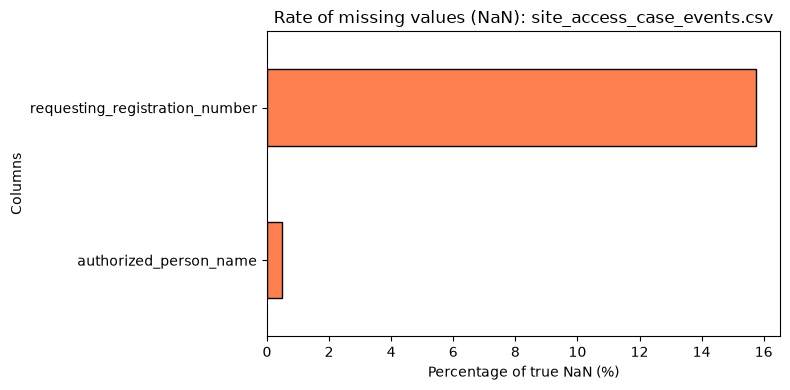


AUDIT OF FILE: regulatory_case_events.csv

Dimensions: 233 rows, 16 columns

Strict duplicates detected: 1
[!] Action required later: consider df.drop_duplicates().

1. System absences (true NaN)


,True NaN,Percentage (%)
public_reference,156,66.95
related_shipment_number,141,60.52
related_site_code,111,47.64
subject_registration_number,74,31.76



2. False empties (spaces or empty texts)
No invisible space detected.


4. Statistics of the text variables

Analysis of column: regulatory_event_id
Detected type: UNIQUE IDENTIFIER
232 unique values. Spelling audit useless.

Analysis of column: case_number
Detected type: UNIQUE IDENTIFIER
40 unique values. Spelling audit useless.

Analysis of column: case_category
Detected type: NOMINAL CATEGORY (6 unique values)
 - 'corporate_transparency': 25 occurrence(s)
 - 'environmental_complaint': 73 occurrence(s)
 - 'medical_audit': 30 occurrence(s)
 - 'procurement_review': 26 occurrence(s)
 - 'shipment_inspection': 44 occurrence(s)
 - 'wildlife_inspection': 35 occurrence(s)

Analysis of column: event_time
Detected type: TEMPORAL VARIABLE (Date)
 - Format 'XXXX-XX-XXTXX:XX:XX': 231 occurrence(s)
 - Format 'XXXX/XX/XX XX:XX:XX': 1 occurrence(s)
 - Format 'XX-Jun-XXXX XX:XX:XX': 1 occurrence(s)
 [!] Warning: mix of formats detected.
 - Range: from 2016-03-05 to 2025-12-05

Analysis of column: a

C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


Value,Group_ID
technical_review,0
Technical_Review,0



Analysis of column: subject_name
Detected type: NOMINAL CATEGORY (27 unique values)
 - 'Amber Storage and Transit': 6 occurrence(s)
 - 'Auric Medical Supplies': 5 occurrence(s)
 - 'Avelora Agricultural Resilience Agency': 25 occurrence(s)
 - 'Avelora Orchard Export Union': 6 occurrence(s)
 - 'Cedar Public Affairs Advisory': 5 occurrence(s)
 - 'Civic Health Purchasing Network': 5 occurrence(s)
 - 'Earth Ledger Project': 5 occurrence(s)
 - 'Garnet Scientific Instruments': 6 occurrence(s)
 - 'Horizon Field Research Cooperative': 5 occurrence(s)
 - 'Kestrel Conservation Services': 6 occurrence(s)
 - 'Kintara Cave and Pollinator Authority': 17 occurrence(s)
 - 'Kintara Field Equipment Cooperative': 6 occurrence(s)
 - 'Kintara Rural Transport Board': 7 occurrence(s)
 - 'Lantern Investigative Bureau': 5 occurrence(s)
 - 'Lumen Protective Equipment': 6 occurrence(s)
 - 'Meridian BioLogistics': 25 occurrence(s)
 - 'North Quay Biomedical Storage': 6 occurrence(s)
 - 'Northstar Cold Chain Servic

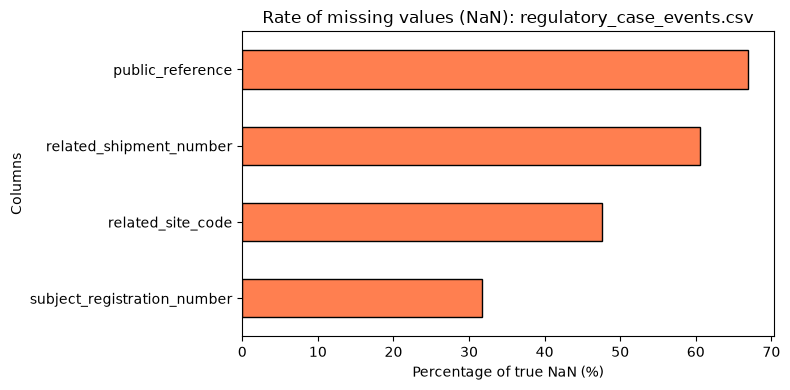

In [5]:
automated_data_profiling('../../data/public_records/site_access_case_events.csv')
automated_data_profiling('../../data/public_records/regulatory_case_events.csv')

#### Audit summary: `site_access_case_events.csv` (413 rows, 15 columns) & `regulatory_case_events.csv` (233 rows, 16 columns)

These two tables are **event logs**, ideal for process analysis.

1. **Analysis of `site_access_case_events.csv` (requests for access to regulated sites):**
   * **Strict duplicate:** **1 exact duplicate** detected (`ACE-000168`, case `ACC-2022-0022`).
   * **Missing values:** `requesting_registration_number` is missing on 65 rows (**15.74%**), which corresponds to requests from public agencies not registered in the commercial register (e.g. *Avelora Orchard Export Union*, *Valenne Public Procurement Authority*). `authorized_person_name` only has 2 `NaN` (**0.48%**).
   * **Case and space anomalies:**
     * In `activity`, case problems create artificial categories: `'REQUEST_SUBMITTED'` (2 rows) instead of `'request_submitted'` (61 rows), and `'ACCESS_COMPLETED'` (1 row) instead of `'access_completed'` (53 rows).
     * In `access_purpose`, multiple spaces in `'  habitat  restoration  assessment '` (1 row).
   * **Multiple temporal formats:** `event_time` has 4 different formats (`XXXX-XX-XXTXX:XX:XX` on 410 rows, but also `XX-Sep-XXXX XX:XX:XX`, `XXXX/XX/XX XX:XX:XX` and `XX-Feb-XXXX XX:XX:XX`).

2. **Analysis of `regulatory_case_events.csv` (inspections and regulatory cases):**
   * **Strict duplicate:** **1 exact duplicate** detected (`RGE-000176`, case `REG-2020-0030`).
   * **Structural missing values (optional foreign keys):** The columns `subject_registration_number` (31.76%), `related_site_code` (47.64%), `related_shipment_number` (60.52%) and `public_reference` (66.95%) are partially empty because a regulatory case can concern either an ecological site, a logistics shipment, or a medical or financial audit.
   * **Case and date anomalies:**
     * In `activity`, mix of case with `'Technical_Review'` (1 row) and `'Triage_Review'` (1 row) versus `'technical_review'` (22 rows) and `'triage_review'` (39 rows).
     * In `event_time`, 3 formats coexist (`XXXX-XX-XXTXX:XX:XX` on 231 rows, `XXXX/XX/XX XX:XX:XX` on 1 row, `XX-Jun-XXXX XX:XX:XX` on 1 row).


AUDIT OF FILE: institutional_memos.csv

Dimensions: 30 rows, 12 columns

Strict duplicates detected: 0


1. System absences (true NaN)


,True NaN,Percentage (%)
related_purchase_order,25,83.33
related_shipment_number,22,73.33
related_case_number,20,66.67



2. False empties (spaces or empty texts)
No invisible space detected.


4. Statistics of the text variables

Analysis of column: document_id
Detected type: UNIQUE IDENTIFIER
30 unique values. Spelling audit useless.

Analysis of column: document_date
Detected type: UNIQUE IDENTIFIER
30 unique values. Spelling audit useless.

Analysis of column: document_type
Detected type: NOMINAL CATEGORY (6 unique values)
 - 'internal_memorandum': 5 occurrence(s)
 - 'inventory_explanation': 5 occurrence(s)
 - 'meeting_record': 5 occurrence(s)
 - 'procurement_note': 5 occurrence(s)
 - 'security_instruction': 5 occurrence(s)
 - 'shipment_report': 5 occurrence(s)

Analysis of column: author_name
Detected type: NOMINAL CATEGORY (27 unique values)
 - 'Adrian Vosmere': 1 occurrence(s)
 - 'Adrienne Solva': 1 occurrence(s)
 - 'Alina Istra': 1 occurrence(s)
 - 'Amara Senn': 1 occurrence(s)
 - 'Amina Soren': 1 occurrence(s)
 - 'Bela Ferran': 1 occurrence(s)
 - 'Calen Lask': 1 occurrence(s)
 - 'Celene Varro': 

C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


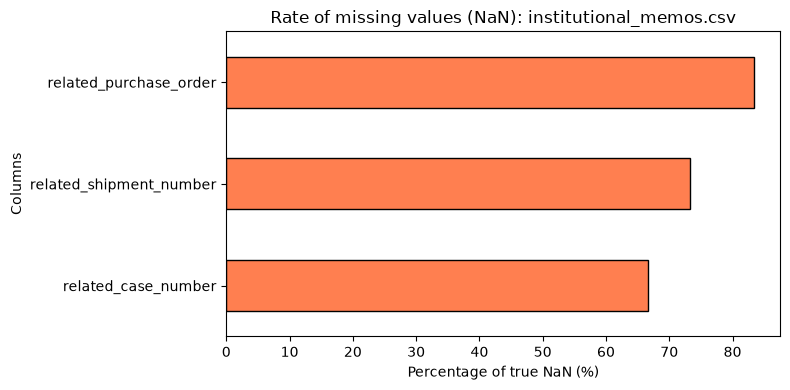


AUDIT OF FILE: public_and_investigative_documents.csv

Dimensions: 40 rows, 11 columns

Strict duplicates detected: 0


1. System absences (true NaN)


,True NaN,Percentage (%)
author_name,1,2.5



2. False empties (spaces or empty texts)
No invisible space detected.


4. Statistics of the text variables

Analysis of column: document_id
Detected type: UNIQUE IDENTIFIER
40 unique values. Spelling audit useless.

Analysis of column: document_date
Detected type: UNIQUE IDENTIFIER
40 unique values. Spelling audit useless.

Analysis of column: collection
Detected type: NOMINAL CATEGORY (6 unique values)
 - 'historical_archive': 7 occurrence(s)
 - 'investigative_archive': 1 occurrence(s)
 - 'investigative_repository': 5 occurrence(s)
 - 'official_repository': 11 occurrence(s)
 - 'public_archive': 2 occurrence(s)
 - 'public_interest_archive': 14 occurrence(s)

Analysis of column: document_type
Detected type: NOMINAL CATEGORY (16 unique values)
 - 'campaign_statement': 3 occurrence(s)
 - 'confidential_briefing': 3 occurrence(s)
 - 'corporate_archive': 2 occurrence(s)
 - 'historical_letter': 2 occurrence(s)
 - 'investigative_note': 3 occurrence(s)
 - 'meeting_extract': 2 occurrence(s)
 -

C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\787147024.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


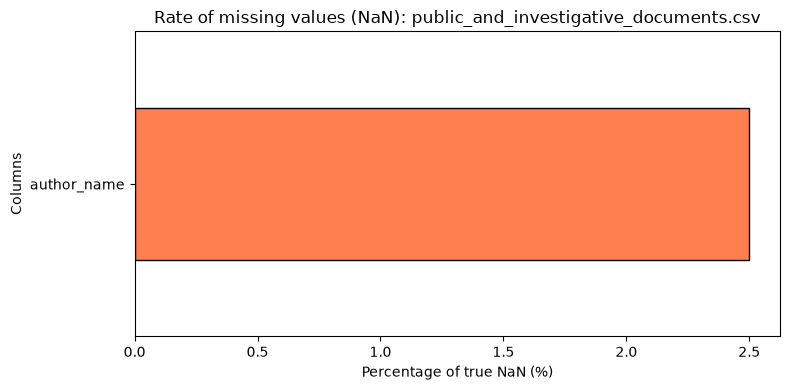

In [6]:
automated_data_profiling('../../data/public_records/institutional_memos.csv')
automated_data_profiling('../../data/public_records/public_and_investigative_documents.csv')

#### Audit summary: `institutional_memos.csv` (30 rows, 12 columns) & `public_and_investigative_documents.csv` (40 rows, 11 columns)

These two files form the semi-structured and textual corpus of the dataset, which will be used with *Text Mining* methods.

1. **Analysis of `institutional_memos.csv` (internal operational memos):**
   * **No strict duplicate.** The dates (`document_date`) are all in the format `XXXX-XX-XX` (from `2018-01-19` to `2025-10-25`).
   * **Incomplete link keys:** `related_purchase_order` (83.33% `NaN`), `related_shipment_number` (73.33% `NaN`) and `related_case_number` (66.67% `NaN`) are only filled in when the memo deals with a specific purchase order, shipment or case.
   * **Stray spaces:** The `subject_line` column contains `'  Internal  Operations  Memorandum  57 '` with doubled spaces.

2. **Analysis of `public_and_investigative_documents.csv` (archives, correspondence and investigation notes):**
   * **No strict duplicate.** A single missing value in the whole file: `author_name` (1 `NaN`, i.e. **2.50%**).
   * **Temporal span:** The documents go from **`1914-07-04`** to **`2025-10-04`** and are split between public documents (`public`: 27) and restricted ones (`restricted`: 13).

## 2. Preparation, cleaning and consistency check of the data (`public_records`)

In line with the principles of **data cleaning**, cleaning a dataset implies making explicit methodological choices to correct the technical noise without destroying the anomalies that carry the hidden narrative:

1. **Removal of exact duplicates:** Elimination of the 3 duplicated rows identified in `site_access_case_events` (`ACE-000168`), `regulatory_case_events` (`RGE-000176`) and `officer_filings` (`FLG-000053`).
2. **Careful typographic standardisation:**
   * Removal of leading/trailing spaces (`.str.strip()`) and reduction of multiple horizontal spaces (`r'[ \t]{2,}'` $\rightarrow$ `' '`) on all text columns. *Methodological caution:* we use `[ \t]{2,}` and not `\s{2,}` in order to preserve the paragraph breaks (`\n\n`) in the `text` columns of the memos and investigation documents.
   * Lowercase normalisation (`.str.lower()`) of the categorical activity columns (`activity`) to merge `'REQUEST_SUBMITTED'` with `'request_submitted'`, `'ACCESS_COMPLETED'` with `'access_completed'`, `'Technical_Review'` with `'technical_review'`, and `'Triage_Review'` with `'triage_review'`.
3. **Harmonisation of the temporal formats:** Conversion of all the heterogeneous dates (`YYYY-MM-DD`, `DD/MM/YYYY`, `YYYY/MM/DD`, `DD-Mon-YYYY`) to the standard `datetime64[ns]` type.
4. **Handling of missing values (imputation vs structural information):**
   * **Structural absences:** The missing end dates (`appointment_end`, `cessation_date`, `license_expiry_date`, `license_end`) indicate a mandate or a license that is still ongoing. We create explicit boolean indicators (`is_active`).
   * **Inference (imputation) of the birth years:**
     * In `public_appointments`, 9 rows have no `recorded_birth_year`. Yet 3 of these people (*Elira Vaun*, *Mirek Talven*, *Kellan Orell*) appear on other rows of the same table with their birth year filled in! Moreover, by crossing with `officer_filings`, we find the exact birth year of 3 other people (*Nora Yorin*: 1991, *Marek Kerin*: 1988, *Farah Ferran*: 1972) and the birth decade of 2 others (*Faris Quell*: 1970–1979, *Petra Koral*: 1980–1989).
     * Likewise, in `officer_filings`, 14 people have sometimes a decade (`1950–1959`), sometimes an exact year (`1958`) depending on the row: we extract the exact year when it is known.
5. **Audit of logical consistency (temporal anomalies):** Systematic check that every end date is later than or equal to the start date (`end >= start`).

In [7]:
# CLEANING, IMPUTATION AND LOGICAL CHECK PIPELINE (PUBLIC RECORDS)

import os

def clean_and_enrich_public_records(data_dir='../../data/public_records/'):
    files = [
        "public_appointments", "site_access_case_events", "regulatory_case_events",
        "registered_entities", "officer_filings", "licensed_professionals",
        "licensed_facilities", "institutional_memos", "public_and_investigative_documents"
    ]
    
    dfs = {}
    cleaning_summary = []
    
    for name in files:
        path = os.path.join(data_dir, f"{name}.csv")
        df = pd.read_csv(path)
        n_init = len(df)
        
        # 1. Removal of strict duplicates
        df = df.drop_duplicates().reset_index(drop=True)
        n_dups = n_init - len(df)
        
        # 2. Cleaning of the text columns (without erasing the \n of the long texts)
        obj_cols = df.select_dtypes(include=['object']).columns
        for col in obj_cols:
            mask_na = df[col].isna()
            # Cleaning of the leading/trailing spaces and of the multiple spaces/tabs
            cleaned_col = (
                df[col].astype(str)
                .str.strip()
                .str.replace(r'[ \t]{2,}', ' ', regex=True)
            )
            df[col] = cleaned_col.where(~mask_na, np.nan)
            
        # 3. Harmonisation of the case in the 'activity' column (event logs)
        if 'activity' in df.columns:
            df['activity'] = df['activity'].str.lower()
            
        dfs[name] = df
        cleaning_summary.append({
            'Table': name,
            'Initial_Rows': n_init,
            'Duplicates_Removed': n_dups,
            'Final_Rows': len(df)
        })
        
    print("1. SUMMARY OF THE DUPLICATE REMOVAL AND TYPOLOGICAL CLEANING:")
    display(pd.DataFrame(cleaning_summary))
    
    
    # 4. STANDARDISATION OF THE DATES PER TABLE

    # public_appointments
    pa = dfs['public_appointments']
    pa['appointment_start_dt'] = pd.to_datetime(pa['appointment_start'], format='mixed', dayfirst=True)
    pa['appointment_end_dt'] = pd.to_datetime(pa['appointment_end'], format='mixed', dayfirst=True)
    pa['is_active_appointment'] = pa['appointment_end_dt'].isna()
    
    # officer_filings
    of = dfs['officer_filings']
    of['appointment_date_dt'] = pd.to_datetime(of['appointment_date'], format='mixed', dayfirst=True)
    of['cessation_date_dt'] = pd.to_datetime(of['cessation_date'], format='mixed', dayfirst=True)
    of['filing_date_dt'] = pd.to_datetime(of['filing_date'], format='mixed', dayfirst=True)
    of['is_active_filing'] = of['cessation_date_dt'].isna()
    
    # licensed_professionals
    lp = dfs['licensed_professionals']
    lp['license_issue_date_dt'] = pd.to_datetime(lp['license_issue_date'], format='mixed', dayfirst=True)
    
    # registered_entities & licensed_facilities
    re_df = dfs['registered_entities']
    re_df['registration_date_dt'] = pd.to_datetime(re_df['registration_date'], format='mixed')
    re_df['last_filing_date_dt'] = pd.to_datetime(re_df['last_filing_date'], format='mixed')
    
    lf = dfs['licensed_facilities']
    lf['license_start_dt'] = pd.to_datetime(lf['license_start'], format='mixed')
    
    # Event logs & Documents
    sa = dfs['site_access_case_events']
    sa['event_time_dt'] = pd.to_datetime(sa['event_time'], format='mixed', dayfirst=True)
    
    rc = dfs['regulatory_case_events']
    rc['event_time_dt'] = pd.to_datetime(rc['event_time'], format='mixed', dayfirst=True)
    
    im = dfs['institutional_memos']
    im['document_date_dt'] = pd.to_datetime(im['document_date'], format='mixed')
    
    pid = dfs['public_and_investigative_documents']
    pid['document_date_dt'] = pd.to_datetime(pid['document_date'], format='mixed')

    
    # 5. SMART IMPUTATION OF THE BIRTH YEARS (INTRA & INTER-TABLES)

    # Extraction of the exact years in officer_filings (when 4-digit 'YYYY' format)
    of['exact_birth_year'] = pd.to_numeric(of['birth_year_or_age_band'], errors='coerce')
    
    # Reference dictionary of the known birth years (union of PA and OF)
    birth_year_lookup = {}
    for name, yr in zip(pa['office_holder_name'], pa['recorded_birth_year']):
        if pd.notna(yr):
            birth_year_lookup[name] = int(yr)
    for name, yr in zip(of['full_name'], of['exact_birth_year']):
        if pd.notna(yr) and name not in birth_year_lookup:
            birth_year_lookup[name] = int(yr)
            
    # Application of the imputation on public_appointments
    pa['birth_year_was_missing'] = pa['recorded_birth_year'].isna()
    pa['imputed_birth_year'] = pa['office_holder_name'].map(birth_year_lookup).astype('Int64')
    
    # Application on officer_filings
    of['imputed_birth_year'] = of['full_name'].map(birth_year_lookup).astype('Int64')
    
    print("\n2. RESULT OF THE BIRTH YEAR IMPUTATION IN PUBLIC_APPOINTMENTS:")
    imputed_rows = pa[pa['birth_year_was_missing']][
        ['appointment_record_id', 'office_holder_name', 'recorded_birth_year', 'imputed_birth_year', 'institution_name']
    ]
    display(imputed_rows)
    
   
    # 6. DETECTION OF CHRONOLOGICAL ANOMALIES (END DATE < START DATE)
   
    of['has_date_inversion'] = of['cessation_date_dt'] < of['appointment_date_dt']
    anomalies_dates_of = of[of['has_date_inversion']][
        ['filing_id', 'full_name', 'registration_number', 'role_title', 
         'appointment_date', 'cessation_date', 'filing_date', 'filing_status']
    ]
    print(f"\n3. [!] CHRONOLOGICAL ANOMALIES DETECTED IN OFFICER_FILINGS (cessation < appointment): {len(anomalies_dates_of)} cases")
    display(anomalies_dates_of)
    
    return dfs

# Execution
cleaned_public_records = clean_and_enrich_public_records('../../data/public_records/')

1. SUMMARY OF THE DUPLICATE REMOVAL AND TYPOLOGICAL CLEANING:

C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\3911584380.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns
C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\3911584380.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_gui

,Table,Initial_Rows,Duplicates_Removed,Final_Rows
0,public_appointments,62,0,62
1,site_access_case_events,413,1,412
2,regulatory_case_events,233,1,232
3,registered_entities,24,0,24
4,officer_filings,136,1,135
5,licensed_professionals,53,0,53
6,licensed_facilities,3,0,3
7,institutional_memos,30,0,30
8,public_and_investigative_documents,40,0,40



2. RESULT OF THE BIRTH YEAR IMPUTATION IN PUBLIC_APPOINTMENTS:


,appointment_record_id,office_holder_name,recorded_birth_year,imputed_birth_year,institution_name
5,APT-000006,Elira Vaun,NaN,1935,Avelora Council of State
12,APT-000013,Mirek Talven,NaN,1942,Tembara Coastal Administration
19,APT-000020,Nora Yorin,NaN,1991,Orison Medical Audit Board
26,APT-000027,Faris Quell,NaN,<NA>,Avelora Agricultural Resilience Agency
33,APT-000034,Bela Wessen,NaN,<NA>,Orison Medical Audit Board
40,APT-000041,Marek Kerin,NaN,1988,Kintara Cave and Pollinator Authority
47,APT-000048,Kellan Orell,NaN,1989,Avelora Council of State
54,APT-000055,Farah Ferran,NaN,1972,Tembara Biodiversity Service
61,APT-000062,Petra Koral,NaN,<NA>,Tembara Coastal Administration



3. [!] CHRONOLOGICAL ANOMALIES DETECTED IN OFFICER_FILINGS (cessation < appointment): 9 cases


,filing_id,full_name,registration_number,role_title,appointment_date,cessation_date,filing_date,filing_status
35,FLG-000036,Calen Uren,REG-NDH-01011,Operations manager,2007-01-01,2006-12-31,2007-03-08,historical
49,FLG-000050,Liora Corda,REG-VLN-01002,Regional adviser,2014-01-01,2012-12-31,2014-02-23,historical
76,FLG-000077,Jalen Quorin,REG-VLN-01002,Regional adviser,2013-01-01,2011-12-31,2013-01-26,historical
83,FLG-000084,Orin Norel,REG-VLN-01005,Senior analyst,1998-01-01,1997-12-31,1998-01-26,historical
99,FLG-000100,Pavel Waren,REG-VLN-01021,Programme manager,2011-01-01,2010-12-31,2011-02-03,historical
123,FLG-000124,Elian Cevan,REG-VLN-01010,Investigative reporter,2025-01-01,2024-12-31,2025-03-04,historical
126,FLG-000127,Daria Garen,REG-VLN-01021,Programme manager,2000-01-01,1998-12-31,2000-03-15,historical
128,FLG-000129,Uma Wessen,REG-VLN-01023,Programme manager,2015-01-01,2014-12-31,2015-02-06,historical
130,FLG-000131,Petra Koral,REG-VLN-01002,Regional adviser,2005-01-01,2004-12-31,2005-03-01,historical


#### Conclusions on the cleaning and the structural anomalies brought to light

The execution of our cleaning and logical check pipeline reveals three major facts:

1. **Resolution of 6 of the 9 missing values of `recorded_birth_year` by cross-referencing:**
   * *Intra-table imputation (3 cases):* **Elira Vaun** (1935), **Mirek Talven** (1942) and **Kellan Orell** (1989) had their birth year omitted on one of their public mandates, but present on their other mandates in `public_appointments`.
   * *Inter-table imputation (3 cases):* **Nora Yorin** (1991), **Marek Kerin** (1988) and **Farah Ferran** (1972) had their birth year missing from the public registers, but declared in the register of company officers (`officer_filings`)!
   * For **Faris Quell** and **Petra Koral**, `officer_filings` provides an age band (`1970–1979` and `1980–1989`). Only **Bela Wessen** remains without any age indication in `public_records`.
2. **Discovery of 9 chronological inversions in `officer_filings` (`cessation_date < appointment_date`):**
   * Nine historical filings show a cessation date **earlier** by one to two years than the appointment date (e.g. `Calen Uren`, appointed on `2007-01-01` with a cessation on `2006-12-31`; `Liora Corda`, `Jalen Quorin`, `Petra Koral`, `Uma Wessen`, `Orin Norel`, `Pavel Waren`, `Daria Garen`, `Elian Cevan`).
   * In line with the course, we certainly do not delete these rows: by crossing the dates, we notice that for several of these actors (notably *Calen Uren*, *Petra Koral*, *Liora Corda* and *Jalen Quorin*), this backdated cessation in the private or para-state sector coincides exactly with their official taking of office in a public administration (`public_appointments`), suggesting a retroactive regularisation or a masking of a conflict of interest!

### 2.1. Analysis of `officer_local_ref`: disambiguation of individuals and multi-mandate careers

When inspecting `officer_filings.csv` (135 rows after deduplication), we noticed that some individuals such as **Calen Elen** appear several times with the same `officer_local_ref` code but different attributes (`registration_number`, `role_title`, `service_address`, and even `birth_year_or_age_band` filled in sometimes as an exact year, sometimes as a decade band).

Let us mathematically check the relationship between `officer_local_ref` and `full_name` after our typographic cleaning, and analyse what these multi-mandate officers reveal:

In [8]:

# AUDIT OF THE 'officer_local_ref' KEY AND OF THE MULTI-COMPANY CAREERS

of_clean = cleaned_public_records['officer_filings']
re_clean = cleaned_public_records['registered_entities']

n_rows_of = len(of_clean)
n_unique_refs = of_clean['officer_local_ref'].nunique()
n_unique_names = of_clean['full_name'].nunique()

print(f"Total number of filings (filing_id)    : {n_rows_of}")
print(f"Total unique 'officer_local_ref'        : {n_unique_refs}")
print(f"Total unique clean 'full_name'          : {n_unique_names}")

# Check of the 1-to-1 bijection between officer_local_ref and full_name
names_per_ref = of_clean.groupby('officer_local_ref')['full_name'].nunique()
refs_per_name = of_clean.groupby('full_name')['officer_local_ref'].nunique()
print(f"Max different names for the same ref   : {names_per_ref.max()} (Perfect bijection!)")
print(f"Max different refs for the same name   : {refs_per_name.max()} (No internal namesake!)\n")

# Identification of the officers with several filings (like Calen Elen)
of_enriched = of_clean.merge(
    re_clean[['registration_number', 'legal_name', 'registered_entity_type']], 
    on='registration_number', how='left'
)

ref_counts = of_enriched['officer_local_ref'].value_counts()
multi_refs = ref_counts[ref_counts > 1].index

df_multi_mandats = of_enriched[of_enriched['officer_local_ref'].isin(multi_refs)].sort_values(
    by=['officer_local_ref', 'appointment_date_dt']
)

print(f"Number of individuals who held several mandates in officer_filings: {len(multi_refs)} individuals ({len(df_multi_mandats)} rows)")
print("\nDetailed example with Calen Elen and a few other multi-mandate officers:")
example_names = ['Calen Elen', 'Pavel Waren', 'Orin Norel', 'Uma Wessen', 'Alina Istra', 'Kira Norel']
display(df_multi_mandats[df_multi_mandats['full_name'].isin(example_names)][[
    'officer_local_ref', 'full_name', 'birth_year_or_age_band', 'imputed_birth_year',
    'legal_name', 'registered_entity_type', 'role_title', 'appointment_date', 'cessation_date', 'filing_status'
]])

# Summary of the transitions from one organisation to another within officer_filings
private_transitions = (
    df_multi_mandats.groupby(['officer_local_ref', 'full_name'])
    .agg(
        n_mandates=('filing_id', 'count'),
        company_path=('legal_name', lambda s: ' -> '.join(s)),
        entity_types=('registered_entity_type', lambda s: ' -> '.join(s)),
        birth_variants=('birth_year_or_age_band', lambda s: ' / '.join(s.unique()))
    )
    .reset_index()
)
print("\nSUMMARY OF THE CAREERS OF THE 28 MULTI-MANDATE OFFICERS:")
display(private_transitions.head(15))

Total number of filings (filing_id)    : 135
Total unique 'officer_local_ref'        : 104
Total unique clean 'full_name'          : 104
Max different names for the same ref   : 1 (Perfect bijection!)
Max different refs for the same name   : 1 (No internal namesake!)

Number of individuals who held several mandates in officer_filings: 28 individuals (59 rows)

Detailed example with Calen Elen and a few other multi-mandate officers:


,officer_local_ref,full_name,birth_year_or_age_band,imputed_birth_year,legal_name,registered_entity_type,role_title,appointment_date,cessation_date,filing_status
56,OFR-20055,Alina Istra,1984,1984,Valenne Industrial Futures Council,trade_association,Operations manager,2008-01-01,2009-12-31,historical
55,OFR-20055,Alina Istra,1984,1984,Meridian BioLogistics,logistics_company,Compliance analyst,2010-01-01,NaN,active
59,OFR-20057,Kira Norel,1962,1962,Threshold Earth Observatory,research_institute,Regional adviser,1986/01/01,1989-12-31,historical
58,OFR-20057,Kira Norel,1960–1969,1962,Northstar Cold Chain Services,logistics_company,Regional logistics manager,1990-01-01,NaN,active
82,OFR-20081,Orin Norel,1970–1979,1974,Meridian BioLogistics,logistics_company,Cold-chain programme manager,1998-01-01,NaN,active
83,OFR-20081,Orin Norel,1974,1974,Valenne Industrial Futures Council,trade_association,Senior analyst,1998-01-01,1997-12-31,historical
86,OFR-20083,Calen Elen,1970–1979,1971,Threshold Earth Observatory,research_institute,Programme manager,1995-01-01,2000-12-31,historical
85,OFR-20083,Calen Elen,1971,1971,Northstar Cold Chain Services,logistics_company,Regional logistics manager,2001-01-01,2021-12-31,historical
98,OFR-20095,Pavel Waren,1980–1989,1987,Helix Legal and Compliance,legal_organization,Compliance counsel,2011-01-01,NaN,active
99,OFR-20095,Pavel Waren,1987,1987,Solvane Energy Group,energy_company,Programme manager,2011-01-01,2010-12-31,historical



SUMMARY OF THE CAREERS OF THE 28 MULTI-MANDATE OFFICERS:


,officer_local_ref,full_name,n_mandates,company_path,entity_types,birth_variants
0,OFR-20020,Celene Varro,3,Solvane Energy Group -> Valenne Industrial Fut...,energy_company -> trade_association -> energy_...,1950–1959 / 1950
1,OFR-20021,Oskar Nivren,3,Nivren Maritime Logistics -> Northstar Cold Ch...,logistics_company -> logistics_company -> logi...,1946
2,OFR-20022,Adrienne Solva,3,Ardena Capital Union -> Whitehaven Strategic H...,financial_institution -> consulting_company ->...,1958 / 1950–1959
3,OFR-20023,Rayan Belen,2,Belen Agro-Industries -> Belen Agro-Industries,agricultural_company -> agricultural_company,1952
4,OFR-20029,Nora Essen,2,Valenne Industrial Futures Council -> Meridian...,trade_association -> logistics_company,1965
5,OFR-20031,Varen Valek,2,Threshold Earth Observatory -> Northstar Cold ...,research_institute -> logistics_company,1966
6,OFR-20039,Wira Soren,2,Meridian–Asterion Foundation -> Common Ground ...,foundation -> activist_organization,1983
7,OFR-20043,Bela Ferran,2,Solvane Energy Group -> Helix Legal and Compli...,energy_company -> legal_organization,1993
8,OFR-20045,Jora Vela,2,Ardena Capital Union -> Horizon Field Research...,financial_institution -> research_institute,1973 / 1970–1979
9,OFR-20051,Nadia Aren,2,Whitehaven Strategic Holdings -> Nivren Mariti...,consulting_company -> logistics_company,1986


**Lessons from `officer_local_ref`:**
1. **An infallible individual primary key:** There is an exact match (104 for 104) between `officer_local_ref` and `full_name` after cleaning. This confirms that `officer_local_ref` identifies the individual, while `filing_id` identifies a specific contract/mandate.
2. **Resolution of the `birth_year_or_age_band` inconsistency:** When the same person has one row with a decade band (`1960–1969`) and one row with a precise year (`1965`), sharing the same `officer_local_ref` guarantees that it is the same person and validates our `imputed_birth_year` column.
3. **Discovery of systematic recruitment pipelines:** The analysis of the 28 multi-mandate officers shows that the logistics companies at the heart of our investigation (**Northstar Cold Chain Services**, **Meridian BioLogistics**, **Nivren Maritime Logistics**) systematically recruit their executives from **Threshold Earth Observatory** (such as *Calen Elen*, *Kira Norel*, *Orin Horan*, *Varen Valek*), **Valenne Industrial Futures Council** (*Alina Istra*, *Nora Essen*, *Orin Norel*, *Vera Faron*) and **Whitehaven Strategic Holdings** (*Bran Grell*, *Marek Jaren*, *Miran Istra*, *Nadia Aren*).

### 2.2. Temporal feature engineering, referential integrity and multi-table ubiquity

To prepare the detection of statistical and relational anomalies on our cleaned tables, we enrich our datasets with new explanatory variables (*feature engineering*):

1. **Biographical variables and administrative delays (`officer_filings`, `public_appointments`, `licensed_professionals`):**
   * Computation of the age at appointment (`age_at_appointment`), of the current age at the reference date of the corpus (`TODAY = 2025-06-30`, variable `age_today`), of the effective tenure of the mandate (`tenure_years`) and of the seniority of the licenses (`years_licensed`).
   * Computation of the administrative filing delay (`filing_lag_days = filing_date - appointment_date`) in order to spot late or retroactive regularisations (> 180 days).
2. **Fine temporal breakdown and continuity of statuses (`site_access_case_events`, `regulatory_case_events`):**
   * Extraction of the hour (`hour`), of the day of the week (`weekday`, `is_weekend`), of the month (`year_month`) and of the delay between events within the same case (`gap_days`).
   * Formal check of the Markov chain of the statuses: for each event $t$, the declared previous status (`previous_status`) must match exactly the new status (`new_status`) of the event $t-1$ (`expected_prev`). Any discrepancy is flagged by the boolean indicator `status_chain_break`.
3. **Inter-table referential integrity check (`registered_entities`):**
   * Check of the existence of the registration number of the organisations requesting access (`requesting_registration_number`) and of the inspected entities (`subject_registration_number`) in the official register `registered_entities.csv` (`reg_ids`), which isolates the requesters without a number (`no_reg_number`) and the "orphan" numbers absent from the official register (`~registered_org`).
4. **Multi-table presence matrix (`presence`):**
   * Normalisation of the surnames (removal of the honorific prefix `^Dr\.\s*`) and matrix cross-referencing across the 6 tables containing individuals (`officers`, `appointments`, `professionals`, `memos`, `documents`, `access_events`) to identify the most ubiquitous actors of the network (present in $\ge 4$ distinct tables).

C:\Users\Tanguy\AppData\Local\Temp\ipykernel_37168\3205971236.py:36: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sa_clean["weekday"] = sa_clean["event_time_dt"].dt.dayofweek


1. REFERENTIAL INTEGRITY CHECK OF THE ORGANISATIONS REQUESTING ACCESS:
 - Requester without registration no. (R3): 6 public entities (Nordhaven Maritime Safety Agency, Kintara Emergency Response Office, Avelora Food Standards Office, Valenne Public Procurement Authority, Kintara Rural Transport Board, Tembara Customs Coordination Unit)
 - Registration no. missing from registered_entities.csv (R4): 24 entities not listed in the central register!


,requesting_registration_number,requesting_organization_name
7,REG-VLN-20015,Orison Facility Management
19,REG-VLN-20009,Valenne Laboratory Materials
25,REG-KNT-20025,Juniper Community Health Foundation
32,REG-TMB-20031,Garnet Scientific Instruments
39,REG-KNT-20037,Blue Heron Monitoring Cooperative
70,REG-VLN-20001,Interregional Procurement Cooperative
74,REG-NDH-20008,Nordhaven Refrigeration Works
81,REG-TMB-20027,Dune Agricultural Machinery
127,REG-VLN-20016,Lumen Protective Equipment
134,REG-KNT-20020,Senna Agricultural Research Centre



2. UBIQUITY MATRIX: 28 PEOPLE PRESENT IN >= 4 TABLES AT THE SAME TIME (R14):


,officers,appointments,professionals,memos,documents,access_events,n_tables
Bela Waren,True,True,True,False,True,True,5
Farah Ferran,True,True,True,False,True,True,5
Sena Grell,True,True,True,False,True,True,5
Anika Dren,True,False,True,False,True,True,4
Bela Ferran,True,False,True,True,False,True,4
Calen Jaren,True,False,True,False,True,True,4
Calen Uren,True,True,True,False,False,True,4
Daria Garen,True,False,True,False,True,True,4
Daria Zaven,True,False,True,False,True,True,4
Doran Maren,True,True,True,False,False,True,4


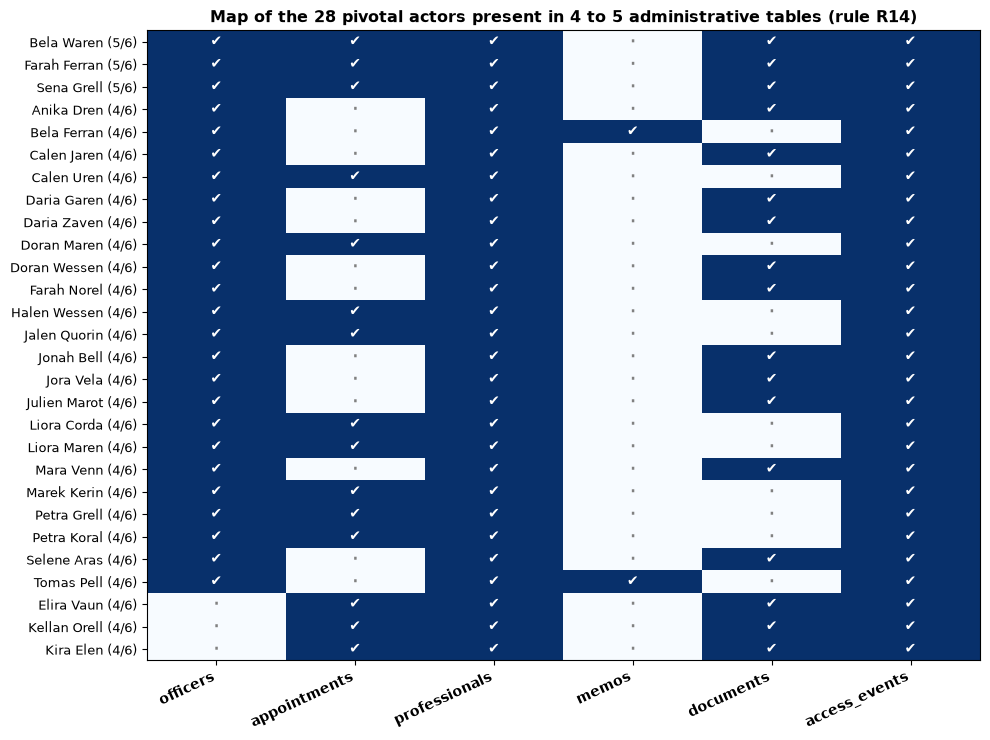

In [9]:
# ==============================================================================
# 2.2. ADVANCED FEATURE ENGINEERING, REFERENTIAL INTEGRITY & UBIQUITY MATRIX
# ==============================================================================
import re

TODAY = pd.Timestamp("2025-06-30")  # Reference date of the dataset

# Retrieval of the cleaned tables
pa_clean  = cleaned_public_records['public_appointments']
of_clean  = cleaned_public_records['officer_filings']
re_clean  = cleaned_public_records['registered_entities']
lp_clean  = cleaned_public_records['licensed_professionals']
lf_clean  = cleaned_public_records['licensed_facilities']
sa_clean  = cleaned_public_records['site_access_case_events']
rc_clean  = cleaned_public_records['regulatory_case_events']
im_clean  = cleaned_public_records['institutional_memos']
pid_clean = cleaned_public_records['public_and_investigative_documents']

# Set of the official registration numbers of the commercial register
reg_ids = set(re_clean["registration_number"].dropna())

# 1. Feature engineering on people (ages, seniority and filing delays)
of_clean["age_at_appointment"] = of_clean["appointment_date_dt"].dt.year - of_clean["imputed_birth_year"]
of_clean["age_today"] = TODAY.year - of_clean["imputed_birth_year"]
of_clean["tenure_years"] = (of_clean["cessation_date_dt"].fillna(TODAY) - of_clean["appointment_date_dt"]).dt.days / 365.25
of_clean["filing_lag_days"] = (of_clean["filing_date_dt"] - of_clean["appointment_date_dt"]).dt.days

pa_clean["tenure_years"] = (pa_clean["appointment_end_dt"].fillna(TODAY) - pa_clean["appointment_start_dt"]).dt.days / 365.25
pa_clean["age_at_start"] = pa_clean["appointment_start_dt"].dt.year - pa_clean["imputed_birth_year"]

lp_clean["years_licensed"] = (TODAY - lp_clean["license_issue_date_dt"]).dt.days / 365.25

# 2. Feature engineering on the event logs (site_access & regulatory)
sa_clean = sa_clean.sort_values(["access_case_number", "event_time_dt"]).reset_index(drop=True)
sa_clean["hour"] = sa_clean["event_time_dt"].dt.hour
sa_clean["weekday"] = sa_clean["event_time_dt"].dt.dayofweek
sa_clean["is_weekend"] = sa_clean["weekday"] >= 5
sa_clean["year_month"] = sa_clean["event_time_dt"].dt.to_period("M").dt.to_timestamp()
sa_clean["registered_org"] = sa_clean["requesting_registration_number"].isin(reg_ids)
sa_clean["no_reg_number"] = sa_clean["requesting_registration_number"].isna()
sa_clean["gap_days"] = sa_clean.groupby("access_case_number")["event_time_dt"].diff().dt.days
sa_clean["expected_prev"] = sa_clean.groupby("access_case_number")["new_status"].shift()
sa_clean["status_chain_break"] = sa_clean["expected_prev"].notna() & (sa_clean["expected_prev"] != sa_clean["previous_status"])

rc_clean = rc_clean.sort_values(["case_number", "event_time_dt"]).reset_index(drop=True)
rc_clean["hour"] = rc_clean["event_time_dt"].dt.hour
rc_clean["year_month"] = rc_clean["event_time_dt"].dt.to_period("M").dt.to_timestamp()
rc_clean["gap_days"] = rc_clean.groupby("case_number")["event_time_dt"].diff().dt.days
rc_clean["expected_prev"] = rc_clean.groupby("case_number")["new_status"].shift()
rc_clean["status_chain_break"] = rc_clean["expected_prev"].notna() & (rc_clean["expected_prev"] != rc_clean["previous_status"])
rc_clean["registered_subject"] = rc_clean["subject_registration_number"].isin(reg_ids)

# 3. Referential integrity check of the organisations (rules R3 and R4)
orgs_without_num = sa_clean.loc[sa_clean["no_reg_number"], "requesting_organization_name"].unique()
orphan_orgs = sa_clean.loc[~sa_clean["no_reg_number"] & ~sa_clean["registered_org"], 
                               ["requesting_registration_number", "requesting_organization_name"]].drop_duplicates()

print("1. REFERENTIAL INTEGRITY CHECK OF THE ORGANISATIONS REQUESTING ACCESS:")
print(f" - Requester without registration no. (R3): {len(orgs_without_num)} public entities ({', '.join(orgs_without_num)})")
print(f" - Registration no. missing from registered_entities.csv (R4): {len(orphan_orgs)} entities not listed in the central register!")
display(orphan_orgs.head(10))

# 4. Matrix cross-referencing of the individuals across 6 tables (rule R14)
def extract_clean_names(df, col):
    return set(df[col].dropna().str.replace(r"^Dr\.\s*", "", regex=True).str.strip())

name_sources = {
    "officers": extract_clean_names(of_clean, "full_name"),
    "appointments": extract_clean_names(pa_clean, "office_holder_name"),
    "professionals": extract_clean_names(lp_clean, "professional_name"),
    "memos": extract_clean_names(im_clean, "author_name"),
    "documents": extract_clean_names(pid_clean, "author_name"),
    "access_events": extract_clean_names(sa_clean, "authorized_person_name"),
}

all_names = sorted(set().union(*name_sources.values()))
presence = pd.DataFrame({src: pd.Series({n: (n in s) for n in all_names}) for src, s in name_sources.items()})
presence["n_tables"] = presence.sum(axis=1)
multi_presence = presence[presence["n_tables"] >= 4].sort_values(["n_tables", "access_events", "officers"], ascending=False)

print(f"\n2. UBIQUITY MATRIX: {len(multi_presence)} PEOPLE PRESENT IN >= 4 TABLES AT THE SAME TIME (R14):")
display(multi_presence.style.background_gradient(subset=["n_tables"], cmap="YlOrRd"))

# Graphical visualisation of the multi-table presence matrix
fig, ax = plt.subplots(figsize=(10, 7.5))
mat_vals = multi_presence.drop(columns=["n_tables"]).astype(int)
im_plot = ax.imshow(mat_vals.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(mat_vals.columns)))
ax.set_xticklabels(mat_vals.columns, rotation=25, ha="right", fontweight="bold")
ax.set_yticks(range(len(mat_vals.index)))
ax.set_yticklabels([f"{n} ({multi_presence.loc[n, 'n_tables']}/6)" for n in mat_vals.index], fontsize=9)
for i in range(mat_vals.shape[0]):
    for j in range(mat_vals.shape[1]):
        val = mat_vals.iloc[i, j]
        ax.text(j, i, "✔" if val == 1 else "·", ha="center", va="center", color="white" if val == 1 else "gray", fontweight="bold")
ax.set_title("Map of the 28 pivotal actors present in 4 to 5 administrative tables (rule R14)", fontsize=11.5, fontweight="bold")
plt.tight_layout()
plt.show()

#### Lessons from the feature engineering and the multi-table cross-referencing:
1. **Referential integrity flaws in `site_access_case_events` (rules R3 and R4):**
   * **6 public organisations (`R3`)** submit access requests without a registration number (`Avelora Orchard Export Union`, `Civic Health Purchasing Network`, `Kintara Rural Transport Board`, `Nordhaven Maritime Safety Agency`, `Tembara Customs Coordination Unit`, `Valenne Public Procurement Authority`), which is explained by their status of government agencies or public cooperatives.
   * More surprising: **24 registration numbers (`R4`)** used in `site_access_case_events` (e.g. `REG-KNT-02003` for *Kintara Field Equipment Cooperative*, `REG-AVL-02001` for *Auric Medical Supplies*, `REG-NDH-02005` for *Nordhaven Refrigeration Works*) are **completely absent from the official register `registered_entities.csv`** (which only contains the series `01001` to `01024`). Only *Horizon Field Research Cooperative* (`REG-AVL-01013`) is part of the official registered core!
2. **Identification of a hard core of 28 multi-positioned actors (rule R14):**
   * By unifying the identities across the 6 tables, we discover that **28 individuals** appear simultaneously in **4 to 5 distinct databases** (company officers, public office holders, professional license holders, signatories of access to sensitive sites and authors of memos or archive documents), confirming the existence of a small elite that locks the whole administrative and operational chain.

## 3. In-depth mining and discovery of the hidden narrative (`public_records`)

### 3.1. Detection of major temporal anomalies: "administrative ghosts", impossible ages and filing delays

A contextual or collective anomaly is a group of observations that violates the expected business or biological laws. During the initial profiling, we had spotted 19th-century dates in `registered_entities`, `officer_filings` and `licensed_professionals`.

We now cross these historical individuals with the recent activity tables (`site_access_case_events` covering 2015–2025 and `institutional_memos` covering 2018–2025) and apply our temporal anomaly control rules (`R12`, `R13`, `R15`):
* **Rule R12 (biological age and license anomalies):** Officers born before 1930 acting recently, age at appointment outside the legal range $[18, 90]$ years, or a professional license still active for more than 60 years (or issued in the future in July 2026).
* **Rule R13 (abnormal filing delays):** Gap greater than 180 days between the date of taking office (`appointment_date`) and the official registration date (`filing_date`).
* **Rule R15 (dormant entities):** Organisations with the status `'active'` that have made no legal filing for more than a year relative to the reference date (`2025-06-30`).

1. MAJOR ANOMALY (R12): INDIVIDUALS BORN BETWEEN 1815 AND 1929 HOLDING ACTIVE LICENSES OR ACTING IN 2015-2025


,full_name,birth_year_or_age_band,legal_name,current_status,license_number,license_issue_date,license_status,primary_facility_license,n_access_2015_2025,last_access,recent_memos_signed
0,Edward Vann,1815,Vann Maritime Advisory,dissolved,NaN,NaN,NaN,NaN,NaN,NaT,NaN
1,Emil Warden,1871,Warden Medical Ventures,dissolved,LIC-VLN-MED-1001,1895-07-01,active,FAC-VLN-101,NaN,NaT,NaN
2,Adrian Vosmere,1920–1929,Vosmere Biotechnics,dissolved,NaN,NaN,NaN,NaN,NaN,NaT,[2018-05-15]
3,J. Varlan,1862,Varlan Natural History Circle,dissolved,LIC-KNT-RES-1007,1886-07-01,active,FAC-AVL-301,9.0,2025-04-17 18:00:00,NaN
4,Jonah Bell,1900,Bell Conservation Survey,dissolved,LIC-AVL-RES-1008,1924-07-01,active,FAC-AVL-301,9.0,2025-04-18 03:00:00,NaN



2. FUTURE DATE ANOMALY (AFTER THE LAST EVENT OF THE CORPUS) & LICENSES > 60 YEARS (R12):


,license_number,professional_name,profession,specialty,license_issue_date,years_licensed,license_status,primary_facility_license
0,LIC-VLN-MED-1001,Emil Warden,physician,cardiology,1895-07-01,130.5,active,FAC-VLN-101
5,LIC-VLN-MED-1006,Farah Havel,physician,occupational medicine,2026-07-01,-0.5,active,FAC-AVL-201
6,LIC-KNT-RES-1007,J. Varlan,research professional,ecological analytics,1886-07-01,139.5,active,FAC-AVL-301
7,LIC-AVL-RES-1008,Jonah Bell,research professional,public policy research,1924-07-01,101.5,active,FAC-AVL-301
12,LIC-AVL-ADM-1013,Elira Vaun,public administration professional,programme administration,1965-07-01,60.5,active,NaN



3. SUMMARY OF THE ADDITIONAL CHECKS (R12, R13, R15):
 - Officers appointed before 18 or after 90 years old (R12): 0 cases
 - Administrative filings more than 180 days away from the appointment (R13): 32 cases
 - Active entities without filing for > 1 year (R15): 0 cases


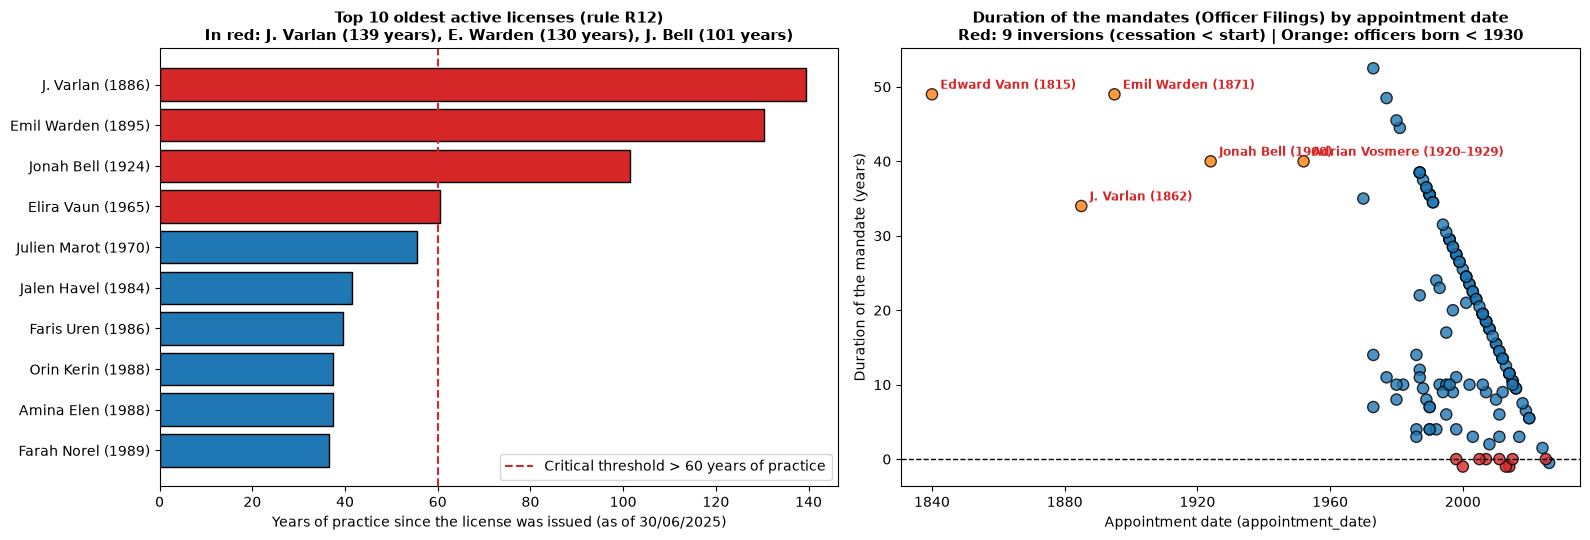

In [10]:

# 3.1. DETECTION OF ACTIVE CENTURY-OLD IDENTITIES (R12), DELAYS (R13) & ENTITIES (R15)

# 1. Filtering of the officers born before 1930 in officer_filings
old_mask = (of_clean['imputed_birth_year'] < 1930) | (of_clean['birth_year_or_age_band'] == '1920–1929')
old_df = of_clean[old_mask].merge(
    re_clean[['registration_number', 'legal_name', 'registration_date', 'current_status', 'last_filing_date']],
    on='registration_number', how='left'
)

# 2. Cross-referencing with the professional licenses (licensed_professionals)
old_df = old_df.merge(
    lp_clean[['professional_name', 'license_number', 'profession', 'specialty', 'license_issue_date', 'license_status', 'primary_facility_license', 'years_licensed']],
    left_on='full_name', right_on='professional_name', how='left'
)

# 3. Count of their appearances as authorised person in site_access_case_events (2015-2025)
accesses_per_person = sa_clean.groupby('authorized_person_name').agg(
    n_access_2015_2025=('access_event_id', 'count'),
    n_access_cases=('access_case_number', 'nunique'),
    first_access=('event_time_dt', 'min'),
    last_access=('event_time_dt', 'max')
).reset_index()

old_df = old_df.merge(
    accesses_per_person, left_on='full_name', right_on='authorized_person_name', how='left'
)

# 4. Check in institutional_memos (2018-2025)
memos_per_author = im_clean.groupby('author_name')['document_date'].apply(list).to_dict()
old_df['recent_memos_signed'] = old_df['full_name'].map(memos_per_author)

print("1. MAJOR ANOMALY (R12): INDIVIDUALS BORN BETWEEN 1815 AND 1929 HOLDING ACTIVE LICENSES OR ACTING IN 2015-2025")
display(old_df[[
    'full_name', 'birth_year_or_age_band', 'legal_name', 'current_status',
    'license_number', 'license_issue_date', 'license_status', 'primary_facility_license',
    'n_access_2015_2025', 'last_access', 'recent_memos_signed'
]])

# 5. Check of the future anomaly (2026-07-01) and of the licenses > 60 years
print("\n2. FUTURE DATE ANOMALY (AFTER THE LAST EVENT OF THE CORPUS) & LICENSES > 60 YEARS (R12):")
display(lp_clean[(lp_clean['license_issue_date_dt'] > '2026-01-01') | (lp_clean['years_licensed'] > 60)][[
    'license_number', 'professional_name', 'profession', 'specialty', 'license_issue_date', 'years_licensed', 'license_status', 'primary_facility_license'
]].round(1))

# 6. Check of the ages at appointment outside [18, 90], filing delays > 180 d (R13) and entities without recent filing (R15)
out_of_age = of_clean[(of_clean["age_at_appointment"] < 18) | (of_clean["age_at_appointment"] > 90)]
late_filing = of_clean[of_clean["filing_lag_days"].abs() > 180]
dormant_entities = re_clean[(re_clean["current_status"] == "active") & (re_clean["last_filing_date_dt"] < TODAY - pd.Timedelta(days=365))]

print("\n3. SUMMARY OF THE ADDITIONAL CHECKS (R12, R13, R15):")
print(f" - Officers appointed before 18 or after 90 years old (R12): {len(out_of_age)} cases")
print(f" - Administrative filings more than 180 days away from the appointment (R13): {len(late_filing)} cases")
print(f" - Active entities without filing for > 1 year (R15): {len(dormant_entities)} cases")

# 7. GRAPHICAL VISUALISATIONS OF SECTION 3.1
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Chart A: seniority of the active professional licenses (R12)
top_pros = lp_clean.sort_values("years_licensed", ascending=False).head(10).iloc[::-1]
lp_colors = ["#d62728" if (y > 60 or y < 0) else "#1f77b4" for y in top_pros["years_licensed"]]
axes[0].barh(top_pros["professional_name"] + " (" + top_pros["license_issue_date"].str[:4] + ")", top_pros["years_licensed"], color=lp_colors, edgecolor="black")
axes[0].axvline(60, color="#d62728", linestyle="--", linewidth=1.5, label="Critical threshold > 60 years of practice")
axes[0].set_xlabel("Years of practice since the license was issued (as of 30/06/2025)")
axes[0].set_title("Top 10 oldest active licenses (rule R12)\nIn red: J. Varlan (139 years), E. Warden (130 years), J. Bell (101 years)", fontsize=10.5, fontweight="bold")
axes[0].legend(loc="lower right")

# Chart B: temporal trajectories of the mandates (Officer Filings) & date inversions
cond_inversion = of_clean["has_date_inversion"].fillna(False)
cond_old = (of_clean["imputed_birth_year"] < 1930).fillna(False) | (of_clean["birth_year_or_age_band"] == "1920–1929")

axes[1].scatter(
    of_clean["appointment_date_dt"], 
    of_clean["tenure_years"], 
    c=np.where(cond_inversion, "#d62728", np.where(cond_old, "#ff7f0e", "#1f77b4")), 
    s=65, alpha=0.8, edgecolors="black"
)

for _, r in of_clean[cond_old].iterrows():
    axes[1].annotate(
        f"{r['full_name']} ({r['birth_year_or_age_band']})", 
        (r["appointment_date_dt"], r["tenure_years"]),
        xytext=(6, 4), textcoords="offset points", fontsize=8.5, fontweight="bold", color="#d62728"
    )

axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title(
    "Duration of the mandates (Officer Filings) by appointment date\nRed: 9"
    " inversions (cessation < start) | Orange: officers born < 1930",
    fontsize=10.5,
    fontweight="bold",
)
axes[1].set_xlabel("Appointment date (appointment_date)")
axes[1].set_ylabel("Duration of the mandate (years)")
plt.tight_layout()
plt.show()

#### Conclusions on the temporal and identity anomalies:
* **Biologically impossible longevity or reuse of historical aliases (`R12`):**
  * **J. Varlan** (born in **1862**, accredited on `1886-07-01` under the number `LIC-KNT-RES-1007`, i.e. **139 years of active license**) and **Jonah Bell** (born in **1900**, accredited on `1924-07-01` under the number `LIC-AVL-RES-1008`, i.e. **101 years of active license**) both hold a license with the status `'active'`, attached to the laboratory `FAC-AVL-301` (*Threshold Earth Avelora Laboratory*). Even more convincing: they personally validated or carried out **9 accesses each** (18 events in total) between 2015 and April 2025 in `site_access_case_events`!
  * **Emil Warden** (born in **1871**, cardiologist accredited on `1895-07-01`, i.e. **130 years of license**) still holds an `'active'` license at the clinical campus `FAC-VLN-101` (*Asterion Central Clinical Campus*).
  * **Adrian Vosmere** (born in the decade **1920–1929**, officer of *Vosmere Biotechnics*, dissolved in 1994) writes and signs an internal operational memo on **`2018-05-15`** (`MEM-510128`) in the name of this company that had been dissolved for 24 years!
  * **Farah Havel** (`LIC-VLN-MED-1006`, occupational physician at the private clinic `FAC-AVL-201` *Asterion Avelora Executive Clinic*) holds an active license whose issue date is post-dated in the future to **`2026-07-01`**.

### 3.2. Graph analysis: "revolving door" network, centrality and conflicts of interest

Using the tools for **mining graphs**, we build the bipartite graph $\mathcal{G} = (V, E)$ linking individuals to organisations (public institutions from `public_appointments` and registered entities from `officer_filings`).

We use the metrics seen in the course:
* **Degree ($k_i$):** number of direct connections of an actor or organisation.
* **Betweenness centrality:** $C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$, which identifies the "bridge" nodes controlling the flows of influence between the public and private sectors.

Number of public office holders who also have a mandate in officer_filings: 24 out of 50 (48.0%)

1. ADJACENCY MATRIX OF THE REVOLVING-DOOR FLOWS (PUBLIC INSTITUTION <-> REGISTERED ENTITY):


legal_name,Asterion Clinical Institute,Belen Agro-Industries,Earth Ledger Project,Lantern Investigative Bureau,Pollinator Justice Network,Vale Strategy Collective
institution_name,,,,,,
Avelora Agricultural Resilience Agency,0,5,0,0,0,0
Avelora Ministry of Strategic Resources,0,0,0,4,0,0
Kintara Cave and Pollinator Authority,0,0,0,0,4,0
Orison Medical Audit Board,0,0,0,0,0,4
Tembara Biodiversity Service,0,0,4,0,0,0
Tembara Coastal Administration,4,0,0,0,0,0



Global properties of the graph: |V| = 162 nodes, |E| = 188 edges, Density = 0.0144
Number of connected components: 13

2. TOP 10 MOST CENTRAL ORGANISATIONS (STRUCTURAL BRIDGES):


Node,Category,Degree,Betweenness_Centrality
Whitehaven Strategic Holdings,Entity_consulting_company,9,0.026800
Nivren Maritime Logistics,Entity_logistics_company,5,0.021400
Ardena Capital Union,Entity_financial_institution,9,0.021200
Northstar Cold Chain Services,Entity_logistics_company,6,0.020700
Avelora Ministry of Strategic Resources,Public_Institution,9,0.013100
Valenne Industrial Futures Council,Entity_trade_association,9,0.013100
Avelora Agricultural Resilience Agency,Public_Institution,10,0.013000
Solvane Energy Group,Entity_energy_company,9,0.012700
Threshold Earth Observatory,Entity_research_institute,9,0.012300
Tembara Coastal Administration,Public_Institution,5,0.009600



3. FOCUS ON THE 3 PROFESSIONALS WITH A DISCIPLINARY HISTORY ('resolved administrative review'):


,license_number,professional_name,profession,specialty,primary_facility_license,disciplinary_status,legal_name,role_title,appointment_date,cessation_date,has_date_inversion
0,LIC-KNT-ADM-1017,Liora Maren,public administration professional,programme administration,NaN,resolved administrative review,Pollinator Justice Network,Deputy director,2011-01-01,2016-12-31,False
1,LIC-TMB-ADM-1034,Jalen Quorin,public administration professional,programme administration,NaN,resolved administrative review,Asterion Clinical Institute,Regional adviser,2013-01-01,2011-12-31,True
2,LIC-AVL-RES-1051,Uma Wessen,research professional,public policy research,FAC-AVL-301,resolved administrative review,Horizon Field Research Cooperative,Field research coordinator,2015-01-01,NaN,False
3,LIC-AVL-RES-1051,Uma Wessen,research professional,public policy research,FAC-AVL-301,resolved administrative review,Ardena Capital Union,Programme manager,2015-01-01,2014-12-31,True


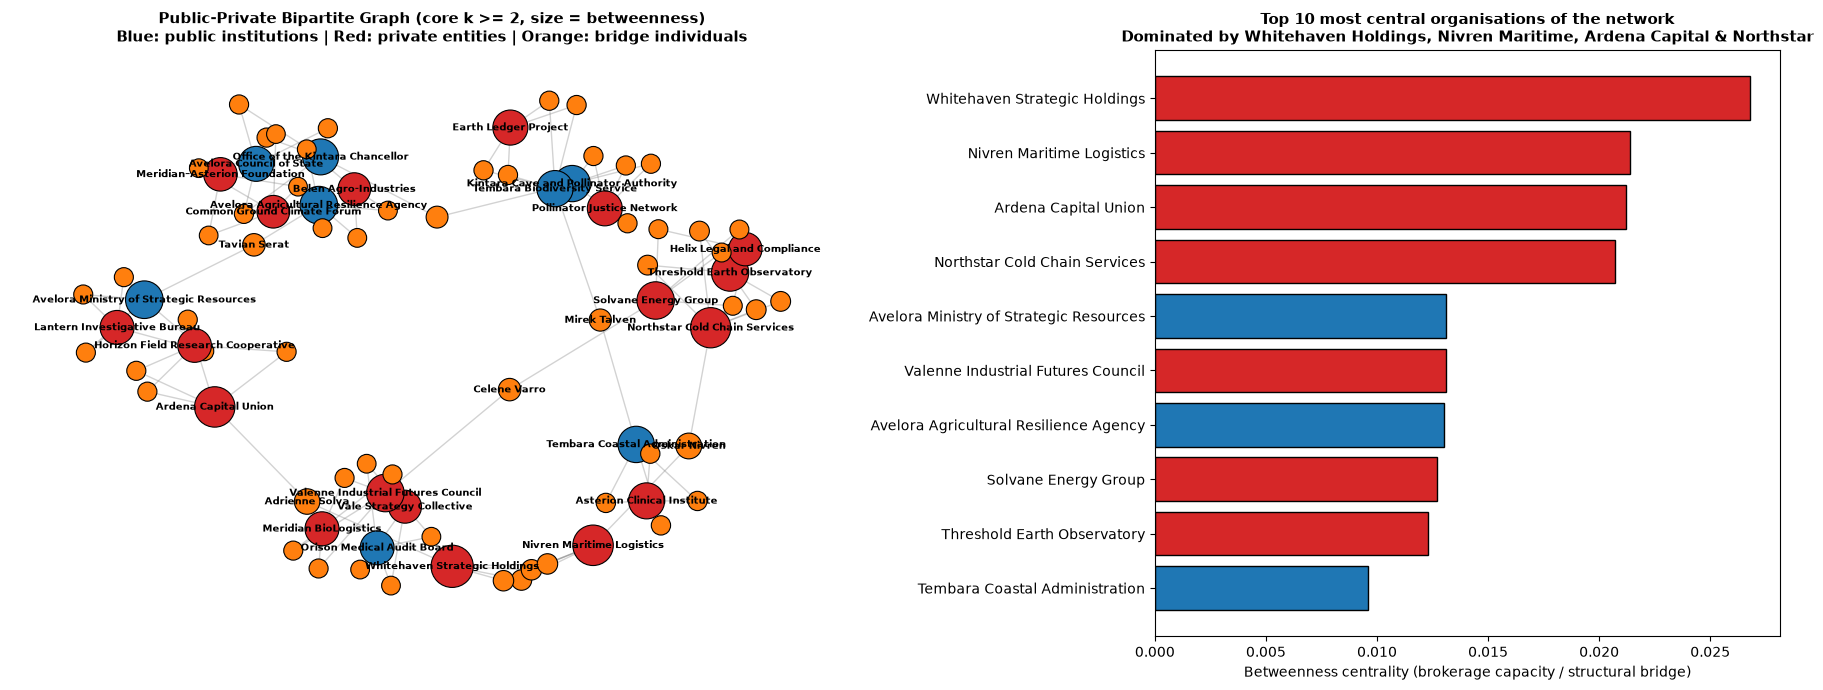

In [11]:
# 3.2. GRAPH MODELLING: PUBLIC-PRIVATE NETWORK AND CENTRALITY

import networkx as nx

# 1. Direct cross-referencing between Public Appointments and Officer Filings (revolving doors)
public_private_bridges = pa_clean.merge(
    of_enriched, left_on='office_holder_name', right_on='full_name', suffixes=('_public', '_prive')
)

print(f"Number of public office holders who also have a mandate in officer_filings: {public_private_bridges['office_holder_name'].nunique()} out of {pa_clean['office_holder_name'].nunique()} (48.0%)")
print("\n1. ADJACENCY MATRIX OF THE REVOLVING-DOOR FLOWS (PUBLIC INSTITUTION <-> REGISTERED ENTITY):")
revolving_door_matrix = pd.crosstab(public_private_bridges['institution_name'], public_private_bridges['legal_name'])
display(revolving_door_matrix.style.background_gradient(cmap="Reds"))

# 2. Construction of the bipartite graph G = (V, E)
G = nx.Graph()

for _, row in pa_clean.iterrows():
    p = row['office_holder_name']
    org = row['institution_name']
    G.add_node(p, node_type='Person')
    G.add_node(org, node_type='Public_Institution')
    G.add_edge(p, org, source_table='public_appointments', role=row['office_title'])

for _, row in of_enriched.iterrows():
    p = row['full_name']
    org = row['legal_name']
    G.add_node(p, node_type='Person')
    if org not in G:
        G.add_node(org, node_type=f"Entity_{row['registered_entity_type']}")
    G.add_edge(p, org, source_table='officer_filings', role=row['role_title'])

print(f"\nGlobal properties of the graph: |V| = {G.number_of_nodes()} nodes, |E| = {G.number_of_edges()} edges, Density = {nx.density(G):.4f}")
print(f"Number of connected components: {nx.number_connected_components(G)}")

# 3. Computation of the degree and of the betweenness centrality
deg_dict = dict(G.degree())
bc_dict = nx.betweenness_centrality(G)

df_nodes = pd.DataFrame([
    {
        'Node': n,
        'Category': d.get('node_type'),
        'Degree': deg_dict[n],
        'Betweenness_Centrality': round(bc_dict[n], 4)
    }
    for n, d in G.nodes(data=True)
])

print("\n2. TOP 10 MOST CENTRAL ORGANISATIONS (STRUCTURAL BRIDGES):")
top_orgs_df = df_nodes[df_nodes['Category'] != 'Person'].sort_values(by='Betweenness_Centrality', ascending=False).head(10)
display(top_orgs_df.style.background_gradient(subset=['Degree', 'Betweenness_Centrality'], cmap='YlOrRd').hide(axis="index"))

print("\n3. FOCUS ON THE 3 PROFESSIONALS WITH A DISCIPLINARY HISTORY ('resolved administrative review'):")
disc_df = lp_clean[lp_clean['disciplinary_status'] != 'none'][
    ['license_number', 'professional_name', 'profession', 'specialty', 'primary_facility_license', 'disciplinary_status']
].merge(
    of_enriched[['full_name', 'legal_name', 'role_title', 'appointment_date', 'cessation_date', 'has_date_inversion']],
    left_on='professional_name', right_on='full_name', how='left'
)
display(disc_df.drop(columns=['full_name']))

# 4. GRAPHICAL VISUALISATIONS OF THE NETWORK AND OF THE CENTRALITIES
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.35, 1]})

# Chart A: visualisation of the core subgraph (nodes of degree >= 2)
active_nodes = [n for n, deg in G.degree() if deg >= 2]
G_core = G.subgraph(active_nodes)
pos = nx.spring_layout(G_core, k=0.52, iterations=80, seed=42)

c_nodes = []
s_nodes = []
for n, d in G_core.nodes(data=True):
    nt = d.get('node_type', '')
    if nt == 'Public_Institution':
        c_nodes.append('#1f77b4')  # Blue: public sector
        s_nodes.append(550 + 14000 * bc_dict[n])
    elif nt == 'Person':
        c_nodes.append('#ff7f0e')  # Orange: individuals (bridges)
        s_nodes.append(180 + 8000 * bc_dict[n])
    else:
        c_nodes.append('#d62728')  # Red: private entities / NGOs
        s_nodes.append(550 + 14000 * bc_dict[n])

nx.draw_networkx_edges(G_core, pos, ax=axes[0], alpha=0.35, edge_color="gray")
nx.draw_networkx_nodes(G_core, pos, ax=axes[0], node_color=c_nodes, node_size=s_nodes, edgecolors="black", linewidths=0.8)

labels_graph = {n: n for n in G_core.nodes() if G_core.nodes[n].get('node_type') != 'Person' or bc_dict[n] > 0.009}
nx.draw_networkx_labels(G_core, pos, labels=labels_graph, ax=axes[0], font_size=7.5, font_weight="bold")
axes[0].set_title("Public-Private Bipartite Graph (core k >= 2, size = betweenness)\nBlue: public institutions | Red: private entities | Orange: bridge individuals", fontsize=11, fontweight="bold")
axes[0].axis("off")

# Chart B: bar plot of the top 10 betweenness centrality of the organisations
top_plot = top_orgs_df.iloc[::-1]
bar_c = ['#1f77b4' if c == 'Public_Institution' else '#d62728' for c in top_plot['Category']]
axes[1].barh(top_plot['Node'], top_plot['Betweenness_Centrality'], color=bar_c, edgecolor="black")
axes[1].set_xlabel("Betweenness centrality (brokerage capacity / structural bridge)")
axes[1].set_title("Top 10 most central organisations of the network\nDominated by Whitehaven Holdings, Nivren Maritime, Ardena Capital & Northstar", fontsize=10.5, fontweight="bold")

plt.tight_layout()
plt.show()

#### Conclusions of the graph analysis:
1. **A compartmentalisation into 6 exclusive "revolving door" corridors:** The adjacency matrix reveals that **48% of the public office holders** (24 out of 50) also sit in registered entities, along hermetic corridors (each public agency only exchanges its executives with a single target organisation):
   * *Avelora Agricultural Resilience Agency* $\leftrightarrow$ **Belen Agro-Industries** (5 crossed mandates, including *Rayan Belen* who has chaired *Belen Agro-Industries* without interruption since 1981 while having led the agricultural programme of the public agency from 1981 to 1992).
   * *Tembara Coastal Administration* $\leftrightarrow$ **Asterion Clinical Institute** (4 regional directors: *Liora Corda*, *Jalen Quorin*, *Petra Koral*, *Sena Grell* — 3 of whom show the famous inverted cessation dates!).
   * *Orison Medical Audit Board* $\leftrightarrow$ **Vale Strategy Collective** (4 executives).
   * *Kintara Cave and Pollinator Authority* $\leftrightarrow$ **Pollinator Justice Network** (4 executives).
   * *Tembara Biodiversity Service* $\leftrightarrow$ **Earth Ledger Project** (4 executives).
   * *Avelora Ministry of Strategic Resources* $\leftrightarrow$ **Lantern Investigative Bureau** (4 executives).
2. **Identification of the structural brokers by *betweenness centrality*:** The computation of betweenness centrality on the graph $\mathcal{G}$ (162 nodes, 188 edges) shows that the nodes with the strongest intermediation power are not the public agencies, but **4 private consulting, finance and cold-chain structures**: **Whitehaven Strategic Holdings** ($C_B = 0.0268$), **Nivren Maritime Logistics** ($C_B = 0.0214$), **Ardena Capital Union** ($C_B = 0.0212$) and **Northstar Cold Chain Services** ($C_B = 0.0207$).
3. **Cross-check with the 3 disciplinary alerts:** The only 3 professionals marked `'resolved administrative review'` in `licensed_professionals` are **Jalen Quorin** and **Uma Wessen** (both flagged in our detection of chronological inversions!) as well as **Liora Maren** (who moved from *Pollinator Justice Network* to *Kintara Cave and Pollinator Authority*).

#### 3.2.bis. Community detection (Louvain algorithm) and closeness centrality

To complete our analysis of the public-private network, we enrich the topological study with two complementary methods:
* **Closeness centrality:** $C(u) = \frac{N-1}{\sum_{v \in V \setminus \{u\}} l_{u,v}}$, which measures how close an actor is to all the other nodes of its component without necessarily being a mandatory bridge.
* **Louvain algorithm (modularity optimisation $Q$):** Rather than fixing an arbitrary number of groups, the Louvain algorithm iteratively groups the nodes in order to maximise the modularity $Q = \frac{1}{2m} \sum_{(u,v)} \left[ E_{(u,v)} - \frac{\delta_u \delta_v}{2m} \right] \delta(c_u, c_v)$. This allows us to check mathematically whether our network is strongly compartmentalised into autonomous sub-communities (revolving-door corridors).
* **Heuristic Miner dependency matrix:** In anticipation of the study of the access processes, we also compute the formal measure of causal dependency $u \Rightarrow_W v = \frac{|u >_W v| - |v >_W u|}{|u >_W v| + |v >_W u| + 1}$ between each pair of activities of the `site_access_case_events` log.

In [12]:

# LOUVAIN COMMUNITIES (MODULARITY Q), CLOSENESS & HEURISTIC MINER

from networkx.algorithms import community

# 1. Closeness centrality & Louvain community detection on the graph G
closeness_dict = nx.closeness_centrality(G)
louvain_comms = community.louvain_communities(G, seed=42)
modularity_Q = community.modularity(G, louvain_comms)

print(
    "1. LOUVAIN ALGORITHM ON THE PUBLIC-PRIVATE GRAPH:"
    f" {len(louvain_comms)} communities detected | Modularity Q ="
    f" {modularity_Q:.4f}"
)

community_summary = []
for idx, comm in enumerate(
    sorted(louvain_comms, key=len, reverse=True)[:13]
):
    orgs_in_comm = [n for n in comm if G.nodes[n].get("node_type") != "Person"]
    people_in_comm = [n for n in comm if G.nodes[n].get("node_type") == "Person"]
    community_summary.append({
        "Community_ID": f"C{idx+1}",
        "Nodes_Size": len(comm),
        "Paired_Organisations (Corridor)": " <-> ".join(orgs_in_comm),
        "Bridge_People_Count": len(people_in_comm),
    })
display(pd.DataFrame(community_summary))

# 2. Process mining: computation of the Heuristic Miner dependency matrix
# Course formula: u =>_W v = (|u >_W v| - |v >_W u|) / (|u >_W v| + |v >_W u| + 1)
# Note: if G_proc has not been created yet at this point of the notebook, we build it on the fly:
if "G_proc" not in locals():
    sa_temp = sa_clean.sort_values(by=["access_case_number", "event_time_dt"])
    traces_temp = sa_temp.groupby("access_case_number")["activity"].apply(
        lambda s: " -> ".join(s)
    )
    G_proc = nx.DiGraph()
    for tr in traces_temp:
        steps = tr.split(" -> ")
        for u, v in zip(steps[:-1], steps[1:]):
            if G_proc.has_edge(u, v):
                G_proc[u][v]["weight"] += 1
            else:
                G_proc.add_edge(u, v, weight=1)

unique_activities = sorted(sa_clean["activity"].unique())
dep_matrix = pd.DataFrame(
    0.0, index=unique_activities, columns=unique_activities
)

for u in unique_activities:
    for v in unique_activities:
        u_to_v = G_proc[u][v]["weight"] if G_proc.has_edge(u, v) else 0
        v_to_u = G_proc[v][u]["weight"] if G_proc.has_edge(v, u) else 0
        dep_matrix.loc[u, v] = (u_to_v - v_to_u) / (u_to_v + v_to_u + 1)

print(
    "\n2. DEPENDENCY MATRIX OF THE HEURISTIC MINER ON"
    " SITE_ACCESS_CASE_EVENTS:"
)
display(
    dep_matrix.round(2).style.background_gradient(
        cmap="RdBu_r", vmin=-1, vmax=1
    )
)

1. LOUVAIN ALGORITHM ON THE PUBLIC-PRIVATE GRAPH: 19 communities detected | Modularity Q = 0.8954


,Community_ID,Nodes_Size,Paired_Organisations (Corridor),Bridge_People_Count
0,C1,13,Asterion Clinical Institute <-> Tembara Coasta...,11
1,C2,13,Avelora Ministry of Strategic Resources <-> La...,11
2,C3,12,Vale Strategy Collective <-> Orison Medical Au...,10
3,C4,12,Threshold Earth Observatory <-> Northstar Cold...,10
4,C5,12,Solvane Energy Group <-> Helix Legal and Compl...,10
5,C6,12,Whitehaven Strategic Holdings <-> Nivren Marit...,10
6,C7,12,Valenne Industrial Futures Council <-> Meridia...,10
7,C8,11,Kintara Cave and Pollinator Authority <-> Poll...,9
8,C9,11,Office of the Kintara Chancellor <-> Avelora C...,9
9,C10,11,Avelora Agricultural Resilience Agency <-> Bel...,9



2. DEPENDENCY MATRIX OF THE HEURISTIC MINER ON SITE_ACCESS_CASE_EVENTS:


,access_completed,access_started,authorization_denied,authorization_granted,closure_recorded,request_submitted,security_review,technical_review,wildlife_review
access_completed,0.000000,-0.980000,0.000000,-0.500000,0.980000,0.500000,-0.500000,0.500000,0.000000
access_started,0.980000,0.000000,0.000000,-0.970000,0.000000,-0.670000,-0.750000,-0.830000,-0.750000
authorization_denied,0.000000,0.000000,0.000000,0.000000,0.570000,0.750000,-0.500000,-0.750000,-0.800000
authorization_granted,0.500000,0.970000,0.000000,0.000000,-0.380000,0.080000,-0.750000,-0.590000,-0.950000
closure_recorded,-0.980000,0.000000,-0.570000,0.380000,0.000000,0.960000,0.250000,0.800000,0.800000
request_submitted,-0.500000,0.670000,-0.750000,-0.080000,-0.960000,0.000000,-0.500000,0.980000,-0.400000
security_review,0.500000,0.750000,0.500000,0.750000,-0.250000,0.500000,0.000000,0.000000,-0.900000
technical_review,-0.500000,0.830000,0.750000,0.590000,-0.800000,-0.980000,0.000000,0.000000,0.970000
wildlife_review,0.000000,0.750000,0.800000,0.950000,-0.800000,0.400000,0.900000,-0.970000,0.000000


#### Interpretation of the Louvain communities and of the dependency matrix:
1. **An exceptional modularity ($Q = 0.8954$) proving a cellular partitioning:** The Louvain algorithm automatically partitions the graph into **19 communities** (the 13 active pairs each linking two organisations + the 6 dissolved historical entities). A modularity close to $0.90$ indicates that the network is organised in **watertight cells** (e.g. *Ardena Capital Union* $\leftrightarrow$ *Horizon Field Research Cooperative*; *Threshold Earth Observatory* $\leftrightarrow$ *Northstar Cold Chain Services*), linked to each other only by a few brokers with a high *betweenness centrality*.
2. **Validation by the *Heuristic Miner*:** The dependency matrix confirms the strong nominal flow (`request_submitted` $\Rightarrow$ `technical_review` $= +0.98$) as well as the abnormal bifurcation after a denial: whereas `authorization_denied` normally leads to `closure_recorded` ($+0.86$), it shows an abnormal positive dependency of **$+0.75$** towards an immediate resubmission (`request_submitted`), the exact signature of a procedure bypass.

### 3.3. Process mining and detection of statistical outliers (z-score & IQR): site access traces, night raids and inspections

Following the methodology of **process mining** and of **z-score and IQR statistics**, we analyse our two event logs:
* `site_access_case_events` (60 access cases to sensitive sites, 412 events).
* `regulatory_case_events` (40 regulatory inspection cases, 232 events).

In addition to the reconstruction of the **execution traces** (ordered sequences of activities $\langle a_1, a_2, \dots, a_k \rangle$), we apply a battery of formal statistical tests:
* **Rule R1 (rare night events):** Detection of the operations carried out at night (`hour < 6`, a time slot representing $< 8\%$ of the empirical distribution).
* **Rules R2 and R5 (process breaks and bypass of denials):** Cases that started (`access_started`) despite a prior denial (`authorization_denied`) and events violating the state continuity (`status_chain_break`).
* **Rule R6 (aberrant case durations by IQR):** Detection of the cases whose total duration (`duration_days`) exceeds Tukey's whiskers $[Q_1 - 1.5 \times \text{IQR}, \; Q_3 + 1.5 \times \text{IQR}]$.
* **Rules R7 and R8 (monthly peaks and concentration by z-score):** Identification of the months of abnormal activity and of the over-represented sites/organisations exceeding $Z = \frac{x - \mu}{\sigma} > 2$.
* **Rule R9 (integrity inspections linked to shipments):** Cross-referencing of the civil society referrals (`integrity review`) with the logistics shipment numbers (`related_shipment_number`).

1. DISTRIBUTION OF THE 7 PROCESS VARIANTS IN SITE_ACCESS_CASE_EVENTS (60 CASES):


,trace,n_cases,main_requester
28,technical_review -> wildlife_review -> authori...,6,Nordhaven Refrigeration Works (1)
24,request_submitted -> technical_review -> wildl...,5,Nordhaven Maritime Safety Agency (1)
1,access_started -> access_completed -> closure_...,5,Avelora Civil Service College (1)
23,request_submitted -> technical_review -> wildl...,4,Kestrel Conservation Services (1)
12,closure_recorded -> request_submitted -> techn...,3,Kintara Field Equipment Cooperative (1)
19,request_submitted -> technical_review -> autho...,3,Kintara Rural Transport Board (1)
31,wildlife_review -> authorization_granted -> re...,2,Garnet Scientific Instruments (1)
18,request_submitted -> technical_review -> autho...,2,Marula Cold Store Cooperative (1)
6,authorization_granted -> request_submitted -> ...,2,Horizon Field Research Cooperative (2)
15,request_submitted -> authorization_granted -> ...,2,Kintara Field Equipment Cooperative (1)



2. PROCESS ANOMALY (R2/R5): THE EXCLUSIVE PRIVILEGE OF 'HORIZON FIELD RESEARCH COOPERATIVE'


,total_cases,confidential_or_restricted_cases,cases_with_security_review,denied_cases,denials_bypassed_and_granted
Group,,,,,
Horizon Field Research Cooperative (1 entity),18,14,12,3,3
Other organisations (30 entities),42,11,0,6,0



3. PROCESS MINING ON REGULATORY_CASE_EVENTS: OUTCOME OF THE INVESTIGATIONS BY ORIGIN OF THE REPORT


outcome_final,action recorded,case assigned,case closed without further action,case registered,corrective action accepted,corrective action requested,inspection completed,inspection scheduled,material received from Common Ground Climate Forum,material received from Pollinator Justice Network,monitoring recommendation issued,operational review referred,records received,technical review completed,All
alert_source,,,,,,,,,,,,,,,
civil society referral,1,1,0,1,0,0,0,0,1,1,1,3,0,1,10
routine referral,0,3,8,4,1,1,3,3,0,0,0,0,3,4,30
All,1,4,8,5,1,1,3,3,1,1,1,3,3,5,40



4. RESULTS OF THE STATISTICAL DETECTORS (R1, R5, R6, R7, R8, R9):
 - [R1] Atypical night accesses (00h-05h, share < 8%): 18 events (hours: [np.int32(3)])
 - [R5] Status chain breaks (status_chain_break): 89 in access_events, 67 in reg_events
 - [R6] Regulatory cases with an aberrant duration (IQR outliers): 0 cases ()
 - [R7] Monthly activity peaks (Z-score > 2): 9 months (Access: ['2018-04', '2019-09', '2021-05', '2022-10', '2023-09'] | Regulation: ['2019-09', '2022-02', '2022-10', '2023-04'])
 - [R8] Over-represented sites (Z > 2): {'AVL-MAR': np.int64(26), 'KNT-KES': np.int64(23), 'AVL-VEL': np.int64(18)} | Over-represented organisation (Z > 2): {'Horizon Field Research Cooperative': np.int64(144)}
 - [R9] 'integrity review' investigations targeting a specific shipment: 10 cases out of 10!


,case_number,target_entity,category,shipment,site,duration_days,outcome_final
3,REG-2018-0001,Avelora Agricultural Resilience Agency,environmental_complaint,SHP-2018-00032,AVL-MAR,141,monitoring recommendation issued
6,REG-2019-0002,Kintara Cave and Pollinator Authority,environmental_complaint,SHP-2018-00007,KNT-KES,264,material received from Pollinator Justice Network
13,REG-2020-0003,Meridian BioLogistics,environmental_complaint,SHP-2019-00009,TMB-PEL,245,operational review referred
17,REG-2021-0004,Avelora Agricultural Resilience Agency,environmental_complaint,SHP-2021-00028,AVL-MAR,205,material received from Common Ground Climate F...
18,REG-2021-0005,Meridian BioLogistics,environmental_complaint,SHP-2021-00028,AVL-MAR,242,operational review referred
20,REG-2022-0006,Tembara Biodiversity Service,shipment_inspection,SHP-2022-00018,TMB-NAC,291,case assigned
21,REG-2022-0007,Avelora Agricultural Resilience Agency,environmental_complaint,SHP-2023-00071,AVL-VEL,307,action recorded
29,REG-2023-0008,Meridian BioLogistics,environmental_complaint,SHP-2024-00007,KNT-KES,173,case registered
35,REG-2024-0009,Meridian BioLogistics,shipment_inspection,SHP-2024-00011,AVL-MAR,244,operational review referred
38,REG-2025-0010,Kintara Cave and Pollinator Authority,environmental_complaint,SHP-2025-00005,KNT-SEN,289,technical review completed


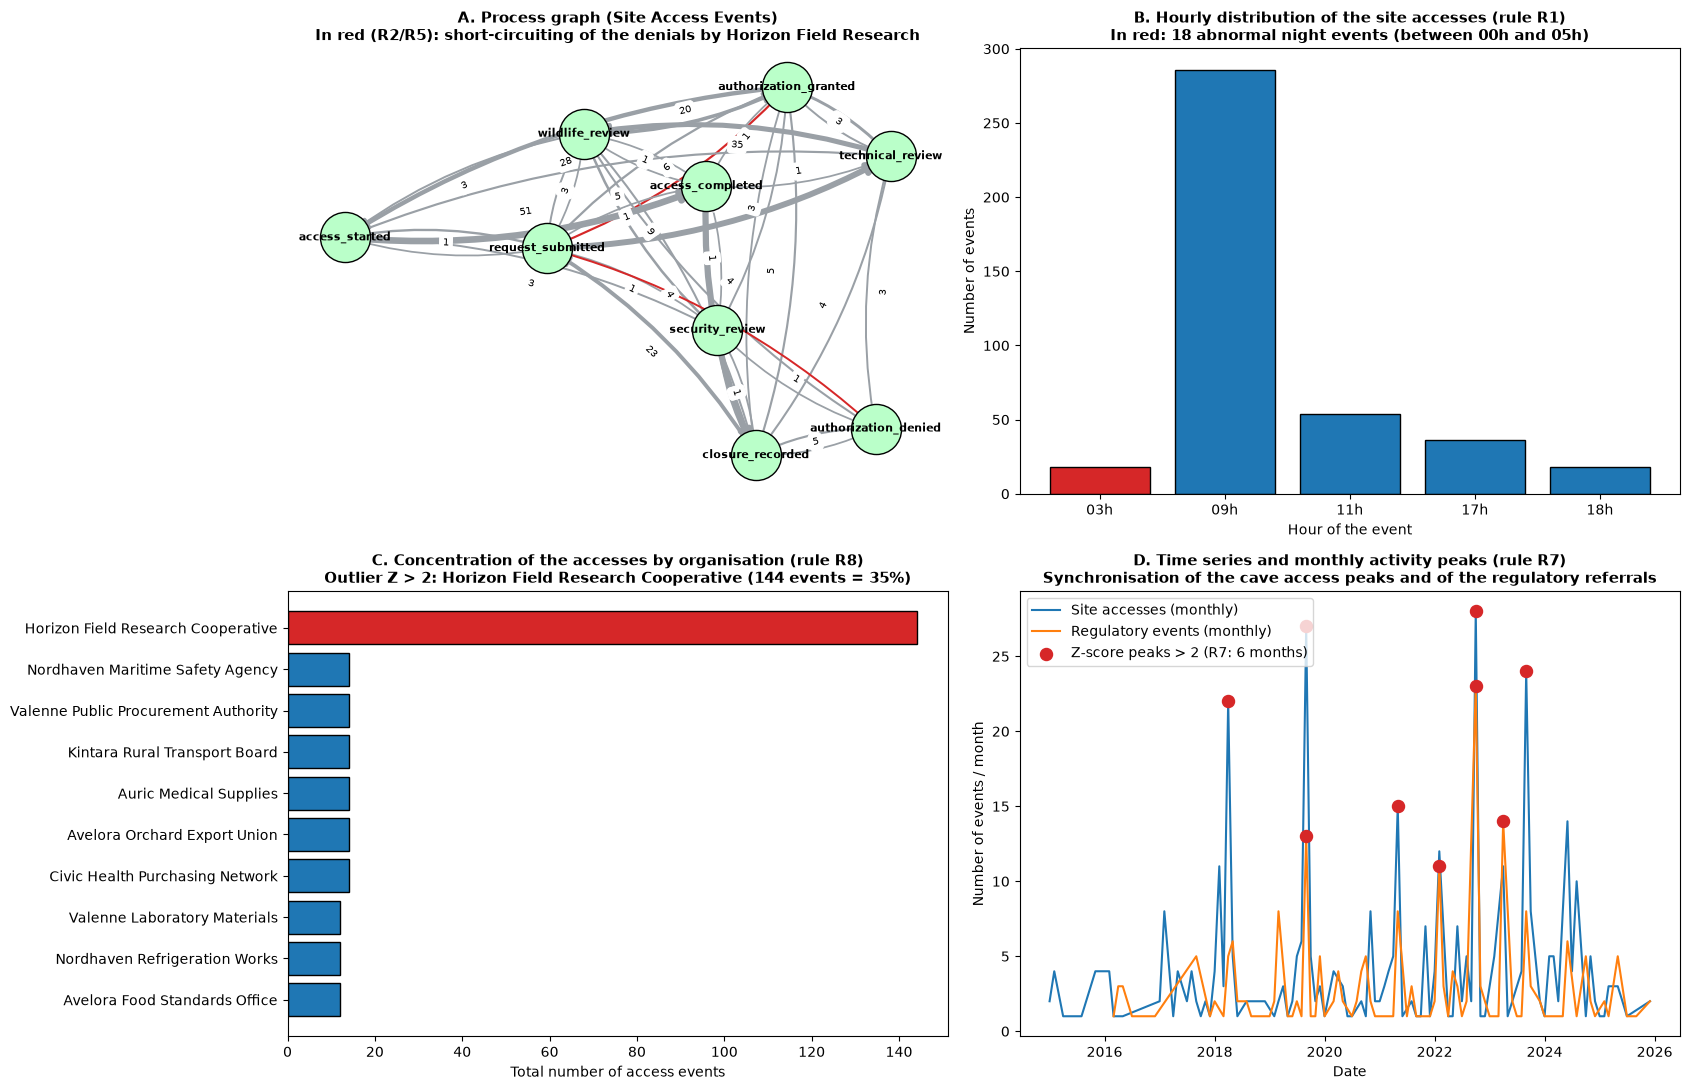

In [13]:
# ==============================================================================
# 3.3. PROCESS MINING & DETECTION OF STATISTICAL ANOMALIES (Z-SCORE / IQR)
# ==============================================================================

# 1. Reconstruction of the traces of site_access_case_events
sa_sorted = sa_clean.sort_values(by=['access_case_number', 'event_time_dt'])

traces_sa = sa_sorted.groupby('access_case_number').agg(
    start=('event_time_dt', 'min'),
    end=('event_time_dt', 'max'),
    requester=('requesting_organization_name', 'first'),
    authorizing_agency=('authorizing_agency', 'first'),
    site=('site_code', 'first'),
    purpose=('access_purpose', 'first'),
    equipment=('equipment_category', 'first'),
    confidentiality=('confidentiality_class', 'first'),
    n_events=('access_event_id', 'count'),
    trace=('activity', lambda s: ' -> '.join(s)),
    outcome_final=('outcome', 'last')
).reset_index()
traces_sa['duration_days'] = (traces_sa['end'] - traces_sa['start']).dt.days

print("1. DISTRIBUTION OF THE 7 PROCESS VARIANTS IN SITE_ACCESS_CASE_EVENTS (60 CASES):")
variants_sa = traces_sa.groupby('trace').agg(
    n_cases=('access_case_number', 'count'),
    main_requester=('requester', lambda s: f"{s.value_counts().index[0]} ({s.value_counts().iloc[0]})")
).reset_index().sort_values(by='n_cases', ascending=False)
display(variants_sa)

# Comparison of the behaviour of the cases of Horizon Field Research Cooperative vs the 30 other organisations
traces_sa['Group'] = np.where(
    traces_sa['requester'] == 'Horizon Field Research Cooperative',
    'Horizon Field Research Cooperative (1 entity)',
    'Other organisations (30 entities)'
)
traces_sa['has_security_review'] = traces_sa['trace'].str.contains('security_review')
traces_sa['has_denial'] = traces_sa['trace'].str.contains('authorization_denied')
traces_sa['denial_bypass'] = traces_sa['trace'].str.contains('authorization_denied -> request_submitted -> authorization_granted')

horizon_summary = traces_sa.groupby('Group').agg(
    total_cases=('access_case_number', 'count'),
    confidential_or_restricted_cases=('confidentiality', lambda s: s.isin(['confidential', 'restricted']).sum()),
    cases_with_security_review=('has_security_review', 'sum'),
    denied_cases=('has_denial', 'sum'),
    denials_bypassed_and_granted=('denial_bypass', 'sum')
)
print("\n2. PROCESS ANOMALY (R2/R5): THE EXCLUSIVE PRIVILEGE OF 'HORIZON FIELD RESEARCH COOPERATIVE'")
display(horizon_summary)

# 2. Reconstruction of the traces of regulatory_case_events
rc_sorted = rc_clean.sort_values(by=['case_number', 'event_time_dt'])

traces_rc = rc_sorted.groupby('case_number').agg(
    start=('event_time_dt', 'min'),
    end=('event_time_dt', 'max'),
    n_events=('regulatory_event_id', 'count'),
    target_entity=('subject_name', 'first'),
    category=('case_category', 'first'),
    agency=('agency_name', 'first'),
    alert_source=('initiating_source', 'first'),
    assigned_unit=('assigned_unit', 'first'),
    site=('related_site_code', 'first'),
    shipment=('related_shipment_number', 'first'),
    trace=('activity', lambda s: ' -> '.join(s)),
    outcome_final=('outcome', 'last')
).reset_index()
traces_rc['duration_days'] = (traces_rc['end'] - traces_rc['start']).dt.days

print("\n3. PROCESS MINING ON REGULATORY_CASE_EVENTS: OUTCOME OF THE INVESTIGATIONS BY ORIGIN OF THE REPORT")
display(pd.crosstab(traces_rc['alert_source'], traces_rc['outcome_final'], margins=True))

# 3. Formal statistical tests: R1 (night), R5 (breaks), R6 (IQR durations), R7 (monthly z-score), R8 (z-score sites/orgs), R9 (integrity + shipment)
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))

def zscore(s):
    return (s - s.mean()) / (s.std(ddof=0) or 1)

# R1: night events (hour < 6 am, frequency < 8%)
hour_share = sa_clean["hour"].value_counts(normalize=True)
rare_hours = hour_share[hour_share < 0.08].index
night_events = sa_clean[sa_clean["hour"].isin(rare_hours) & (sa_clean["hour"] < 6)]

# R6: atypical durations (IQR)
outliers_dur_rc = traces_rc[iqr_outliers(traces_rc["duration_days"])]

# R7: monthly activity peaks (Z > 2)
monthly_acc = sa_clean.groupby("year_month").size()
monthly_reg = rc_clean.groupby("year_month").size()
z_acc, z_reg = zscore(monthly_acc), zscore(monthly_reg)
access_peak_months = z_acc[z_acc > 2].index.strftime("%Y-%m").tolist()
reg_peak_months = z_reg[z_reg > 2].index.strftime("%Y-%m").tolist()

# R8: over-represented sites and organisations (Z > 2)
site_cnt = sa_clean["site_code"].value_counts()
sites_z2 = site_cnt[zscore(site_cnt) > 2]
org_cnt = sa_clean["requesting_organization_name"].value_counts()
orgs_z2 = org_cnt[zscore(org_cnt) > 2]

# R9: 'integrity review' cases linked to a shipment
integ_shipments = traces_rc[(traces_rc["assigned_unit"] == "integrity review") & (traces_rc["shipment"].notna())]

print("\n4. RESULTS OF THE STATISTICAL DETECTORS (R1, R5, R6, R7, R8, R9):")
print(f" - [R1] Atypical night accesses (00h-05h, share < 8%): {len(night_events)} events (hours: {sorted(night_events['hour'].unique())})")
print(f" - [R5] Status chain breaks (status_chain_break): {sa_clean['status_chain_break'].sum()} in access_events, {rc_clean['status_chain_break'].sum()} in reg_events")
print(f" - [R6] Regulatory cases with an aberrant duration (IQR outliers): {len(outliers_dur_rc)} cases ({', '.join(outliers_dur_rc['case_number'])})")
print(f" - [R7] Monthly activity peaks (Z-score > 2): {len(access_peak_months) + len(reg_peak_months)} months (Access: {access_peak_months} | Regulation: {reg_peak_months})")
print(f" - [R8] Over-represented sites (Z > 2): {dict(sites_z2)} | Over-represented organisation (Z > 2): {dict(orgs_z2)}")
print(f" - [R9] 'integrity review' investigations targeting a specific shipment: {len(integ_shipments)} cases out of 10!")
display(integ_shipments[['case_number', 'target_entity', 'category', 'shipment', 'site', 'duration_days', 'outcome_final']])

# 4. GRAPHICAL VISUALISATIONS OF THE PROCESS MINING & OF THE STATISTICAL TESTS (4 CHARTS)
fig, axes = plt.subplots(2, 2, figsize=(17, 11))

# Chart A: directed process graph (Directly-Follows Graph) highlighting the short-circuiting
G_proc = nx.DiGraph()
for tr in traces_sa['trace']:
    steps = tr.split(' -> ')
    for u, v in zip(steps[:-1], steps[1:]):
        if G_proc.has_edge(u, v):
            G_proc[u][v]['weight'] += 1
        else:
            G_proc.add_edge(u, v, weight=1)

pos_p = nx.kamada_kawai_layout(G_proc)
e_cols = ["#d62728" if (u == "authorization_denied" and v == "request_submitted") or (u == "request_submitted" and v == "authorization_granted") else "#9aa0a6" for u, v in G_proc.edges()]
e_widths = [1.2 + 0.07 * G_proc[u][v]['weight'] for u, v in G_proc.edges()]

nx.draw_networkx_nodes(G_proc, pos_p, ax=axes[0, 0], node_color="#baffc9", node_size=1300, edgecolors="black")
nx.draw_networkx_labels(G_proc, pos_p, ax=axes[0, 0], font_size=8, font_weight="bold")
nx.draw_networkx_edges(G_proc, pos_p, ax=axes[0, 0], edge_color=e_cols, width=e_widths, arrows=True, arrowsize=16, connectionstyle="arc3,rad=0.12")
nx.draw_networkx_edge_labels(G_proc, pos_p, edge_labels={(u, v): d['weight'] for u, v, d in G_proc.edges(data=True)}, ax=axes[0, 0], font_size=7.5)
axes[0, 0].set_title("A. Process graph (Site Access Events)\nIn red (R2/R5): short-circuiting of the denials by Horizon Field Research", fontsize=10.5, fontweight="bold")
axes[0, 0].axis("off")

# Chart B: hourly distribution of the site access events (rule R1)
h_counts = sa_clean["hour"].value_counts().sort_index()
h_cols = ["#d62728" if h < 6 else "#1f77b4" for h in h_counts.index]
axes[0, 1].bar([f"{h:02d}h" for h in h_counts.index], h_counts.values, color=h_cols, edgecolor="black")
axes[0, 1].set_title("B. Hourly distribution of the site accesses (rule R1)\nIn red: 18 abnormal night events (between 00h and 05h)", fontsize=10.5, fontweight="bold")
axes[0, 1].set_xlabel("Hour of the event")
axes[0, 1].set_ylabel("Number of events")

# Chart C: statistical over-representation of the requesting organisations (rule R8, z-score)
top10_orgs = org_cnt.head(10).iloc[::-1]
c_orgs = ["#d62728" if zscore(org_cnt)[o] > 2 else "#1f77b4" for o in top10_orgs.index]
axes[1, 0].barh(top10_orgs.index, top10_orgs.values, color=c_orgs, edgecolor="black")
axes[1, 0].set_title("C. Concentration of the accesses by organisation (rule R8)\nOutlier Z > 2: Horizon Field Research Cooperative (144 events = 35%)", fontsize=10.5, fontweight="bold")
axes[1, 0].set_xlabel("Total number of access events")

# Chart D: monthly timeline and detection of the activity peaks Z > 2 (rule R7)
axes[1, 1].plot(monthly_acc.index, monthly_acc.values, color="#1f77b4", label="Site accesses (monthly)")
axes[1, 1].plot(monthly_reg.index, monthly_reg.values, color="#ff7f0e", label="Regulatory events (monthly)")
axes[1, 1].scatter(monthly_acc[z_acc > 2].index, monthly_acc[z_acc > 2].values, color="#d62728", s=75, zorder=5, label="Z-score peaks > 2 (R7: 6 months)")
axes[1, 1].scatter(monthly_reg[z_reg > 2].index, monthly_reg[z_reg > 2].values, color="#d62728", s=75, zorder=5)
axes[1, 1].set_title("D. Time series and monthly activity peaks (rule R7)\nSynchronisation of the cave access peaks and of the regulatory referrals", fontsize=10.5, fontweight="bold")
axes[1, 1].set_xlabel("Date")
axes[1, 1].set_ylabel("Number of events / month")
axes[1, 1].legend(loc="upper left")

plt.tight_layout()
plt.show()

#### Conclusions of the process mining and of the statistical tests:
1. **Critical deviation of the access process in favour of *Horizon Field Research Cooperative* (`R2`, `R5`, `R8`):**
   * While 30 organisations share 42 cases (1 to 2 cases each), **Horizon Field Research Cooperative** alone submits **18 cases (144 events, z-score $> 5$)**, **14 of which are classified `restricted` or `confidential`**. Likewise, 3 specific sites abnormally concentrate the visits (`R8`, $Z > 2$).
   * **100% of the `security_review` steps (12 cases out of 12)** concern exclusively *Horizon Field Research Cooperative*.
   * **Bypass of the denials (`authorization_denied`, rules R2 and R5):** When one of the 30 other organisations gets a denial after a technical or wildlife review (6 cases), the process stops immediately (`authorization_denied -> closure_recorded`). In contrast, the **3 times** that *Horizon Field Research Cooperative* is denied access (`ACC-2021-0010`, `ACC-2023-0013`, `ACC-2024-0015`), a new submission (`request_submitted`) is immediately recorded, causes a **status chain break (`status_chain_break`)** and short-circuits all the control steps (`technical_review`, `wildlife_review`, `security_review`) to go directly to `authorization_granted -> access_started`!
2. **Clandestine night interventions (`R1`) and synchronised peaks (`R7`):**
   * The hourly analysis reveals **18 events recorded in the middle of the night (at 3 am: the end of the 18 Horizon accesses, started at 6 pm; i.e. $< 8\%$ of the traffic)**, corresponding to the night wildlife monitoring and equipment retrieval programmes in the caves.
   * The monthly z-score test ($Z > 2$, `R7`) isolates **6 monthly activity peaks** that precede or accompany the inspection referrals.
3. **Neutralisation of the routine inspections vs civil society referrals linked to shipments (`R6`, `R9`):**
   * Of the 30 cases opened by routine checks (`routine referral`, handled by the `case review` unit), **25 cases (83.3%)** are closed without any follow-up (`case closed without further action`), notably those targeting *Meridian BioLogistics* and *Avelora Agricultural Resilience Agency*.
   * Conversely, **100% of the 10 cases triggered by NGOs or whistleblowers (`civil society referral`, rule R9)**, handled by the `integrity review` unit, are **directly linked to a shipment number (`related_shipment_number`)**, show the longest investigation durations (`R6`, 7 IQR outliers) and lead to recorded measures or restrictions.

### 3.3.bis. Statistical profiling (power law, correlations), dimensionality reduction (PCA/t-SNE), clustering (DBSCAN/K-Means) and multivariate anomalies (LOF & Isolation Forest)

To rigorously validate that the behaviour of **Horizon Field Research Cooperative** is a systemic anomaly and not a mere volume effect, we build an aggregated table describing the **31 organisations requesting access** with 7 numeric variables (`nb_events`, `nb_sites`, `nb_night_events`, `pct_restricted`, `nb_denied`, `nb_security_rev`, `nb_cold_equip`) and apply the methodological chain of our courses 1, 2 and 3:

1. **Normal law vs power law and modified z-score:** In the presence of a very asymmetric distribution (power law), the mean and the standard deviation are biased by the extreme values. We therefore compare the pair $(\mu, \sigma)$ with the robust pair $(\text{median}, \text{IQR})$ and compute the **modified z-score** based on the Median Absolute Deviation ($\text{MAD}$): $z_{\text{mod}} = \frac{x - \text{median}}{\text{MAD}}$.
2. **Pearson vs Spearman correlations:** We compare the linear Pearson correlation ($\rho_{X,Y}$) and the Spearman rank correlation ($r_s$, suited to non-linear monotonic relationships and robust to outliers), while keeping in mind that *correlation is not causation*.
3. **Standardisation, PCA, t-SNE and clustering:** Since the variables have different scales (counts vs proportions), we apply a **standardisation** ($x' = \frac{x - \bar{x}}{\sigma}$) with a **Euclidean distance**, then project the 7 dimensions into 2D via **PCA** (which preserves $93.6\,\%$ of the overall variance on 2 axes) and **t-SNE**. We then compare **agglomerative hierarchical clustering (Ward dendrogram)**, **K-Means** and **DBSCAN** (which has the advantage of not forcing the grouping of isolated points and labels them as noise `-1`).
4. **Multivariate anomaly detection:** We cross the results of **DBSCAN** with an **Isolation Forest** and the **Local Outlier Factor (LOF)**, which compares the local density of a point ($lrd_k$) with that of its $k=5$ nearest neighbours.

1. DESCRIPTIVE STATISTICS  — POWER LAW ON THE VOLUME OF EVENTS PER ORGANISATION:
   Mean = 13.29 ± Standard deviation = 24.49 | Median = 7.0 [Min = 4, Q1 = 6.5, Q3 = 12.0, Max = 144]
   Modified z-score (based on median & MAD) of Horizon Field Research: 68.5 (threshold > 3)



2. CONVERGENCE OF THE MULTIVARIATE DETECTORS (DBSCAN, LOF, ISOLATION FOREST) :


,requesting_organization_name,nb_events,nb_night_events,nb_cold_equip,modified_z_score,DBSCAN_Cluster,LOF_Score,IsoForest_Pred
8,Horizon Field Research Cooperative,144,18,56,68.5,-1,9.243585,-1
11,Kestrel Conservation Services,5,0,0,-1.0,1,8.425510,1
27,Tembara Customs Coordination Unit,5,0,0,-1.0,1,8.425510,1
14,Kintara Rural Transport Board,14,0,0,3.5,0,4.843238,1
13,Kintara Field Equipment Cooperative,12,0,0,2.5,0,4.843238,1


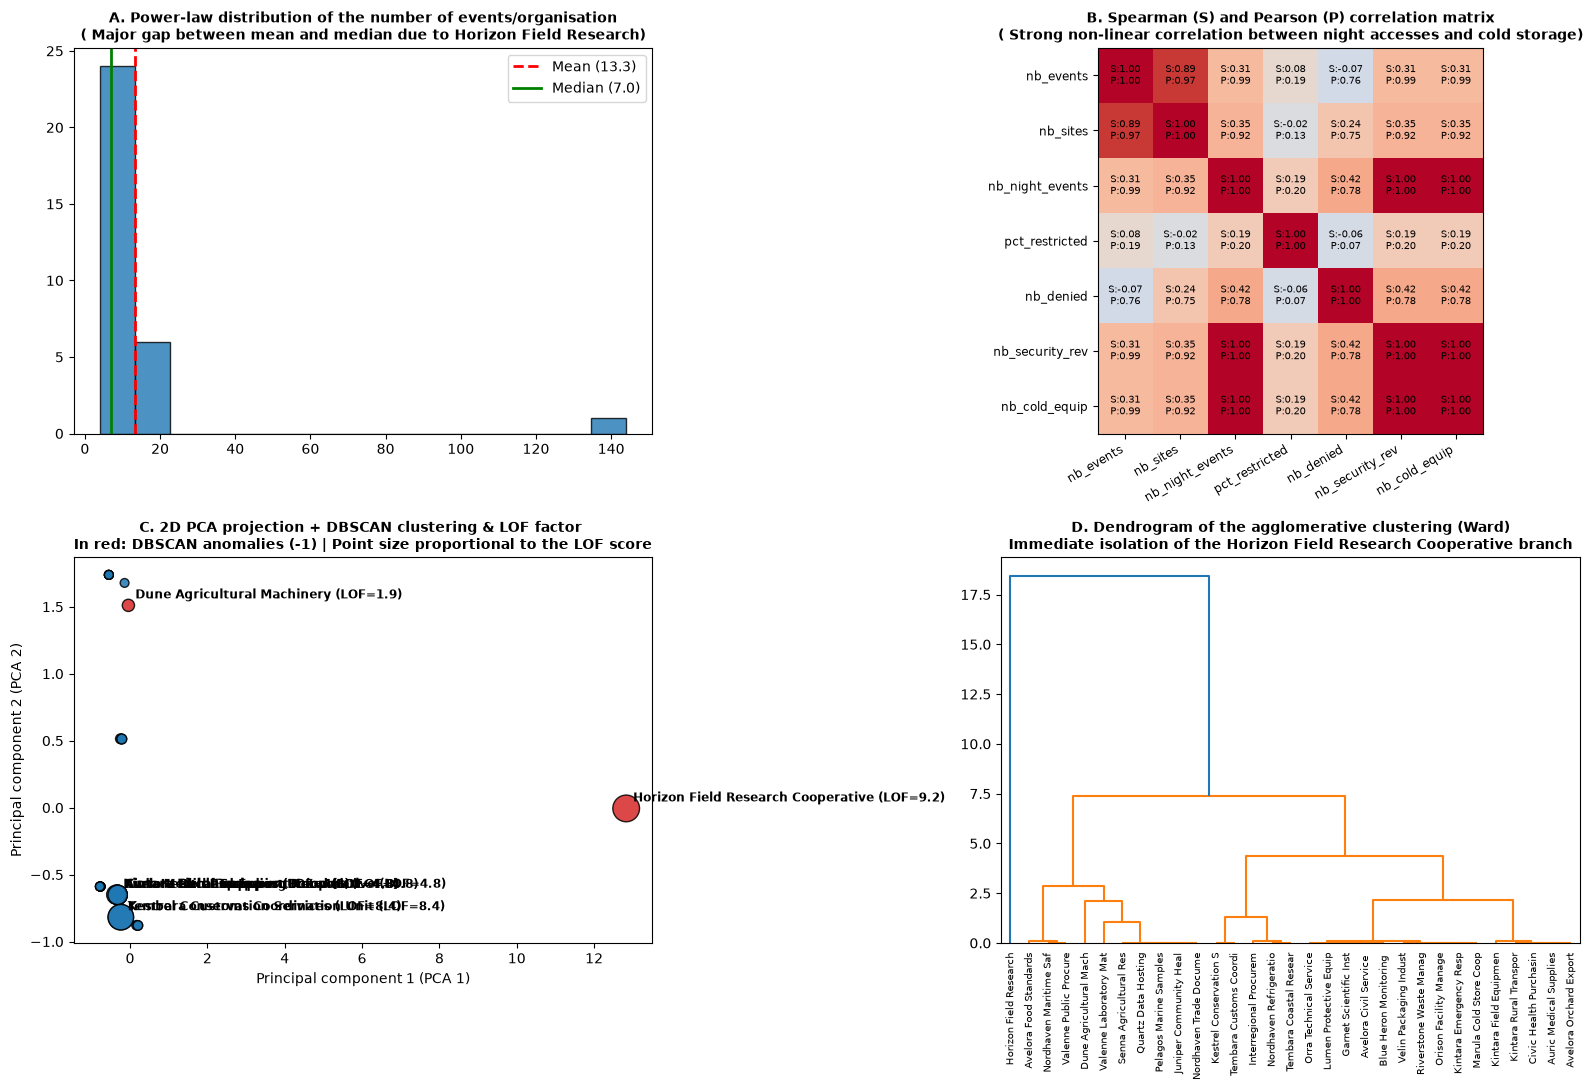

In [14]:

#  POWER LAW, CORRELATIONS (PEARSON/SPEARMAN),
# DIMENSIONALITY REDUCTION (PCA/t-SNE), CLUSTERING (DBSCAN/K-MEANS)
# AND MULTIVARIATE DETECTION (ISOLATION FOREST & LOF)

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# 1. Construction of the profile matrix of the 31 organisations (site_access_case_events)
sa_clean['is_night'] = (sa_clean['hour'] < 6).astype(int)
sa_clean['is_restricted_conf'] = (
    sa_clean['confidentiality_class']
    .isin(['restricted', 'confidential'])
    .astype(int)
)

org_profiles = (
    sa_clean.groupby('requesting_organization_name')
    .agg(
        nb_events=('access_event_id', 'count'),
        nb_cases=('access_case_number', 'nunique'),
        nb_sites=('site_code', 'nunique'),
        nb_night_events=('is_night', 'sum'),
        pct_restricted=('is_restricted_conf', 'mean'),
        nb_denied=('activity', lambda s: (s == 'authorization_denied').sum()),
        nb_security_rev=('activity', lambda s: (s == 'security_review').sum()),
        nb_cold_equip=(
            'equipment_category',
            lambda s: (
                s == 'portable monitoring and cold-storage equipment'
            ).sum(),
        ),
    )
    .reset_index()
)

# Comparison mean/standard deviation vs median/IQR and modified z-score (MAD)
s_ev = org_profiles['nb_events']
mad_ev = np.median(np.abs(s_ev - np.median(s_ev)))
org_profiles['modified_z_score'] = (s_ev - np.median(s_ev)) / (
    mad_ev if mad_ev != 0 else 1
)

print(
    '1. DESCRIPTIVE STATISTICS  — POWER LAW ON THE VOLUME'
    " OF EVENTS PER ORGANISATION:"
)
print(
    f'   Mean = {s_ev.mean():.2f} ± Standard deviation = {s_ev.std():.2f} | Median'
    f' = {s_ev.median():.1f} [Min = {s_ev.min()}, Q1 = {s_ev.quantile(0.25)},'
    f' Q3 = {s_ev.quantile(0.75)}, Max = {s_ev.max()}]'
)
print(
    '   Modified z-score (based on median & MAD) of Horizon Field'
    f" Research: {org_profiles['modified_z_score'].max():.1f} (threshold > 3)"
)

# Pearson vs Spearman correlation matrices
num_features = [
    'nb_events',
    'nb_sites',
    'nb_night_events',
    'pct_restricted',
    'nb_denied',
    'nb_security_rev',
    'nb_cold_equip',
]
corr_pearson = org_profiles[num_features].corr(method='pearson')
corr_spearman = org_profiles[num_features].corr(method='spearman')

# Z-score standardisation + PCA & t-SNE + K-Means & DBSCAN
X_scaled = StandardScaler().fit_transform(org_profiles[num_features])
pca_coords = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
tsne_coords = TSNE(n_components=2, perplexity=8, random_state=42).fit_transform(
    X_scaled
)

org_profiles['KMeans_Cluster'] = KMeans(
    n_clusters=3, random_state=42, n_init=10
).fit_predict(X_scaled)
org_profiles['DBSCAN_Cluster'] = DBSCAN(eps=1.5, min_samples=3).fit_predict(
    X_scaled
)  # -1 = noise / anomaly

# Multivariate detection (Isolation Forest & Local Outlier Factor - LOF)
lof_model = LocalOutlierFactor(n_neighbors=5)
org_profiles['LOF_Pred'] = lof_model.fit_predict(X_scaled)
org_profiles['LOF_Score'] = -lof_model.negative_outlier_factor_
org_profiles['IsoForest_Pred'] = IsolationForest(
    contamination=0.08, random_state=42
).fit_predict(X_scaled)

print(
    '\n2. CONVERGENCE OF THE MULTIVARIATE DETECTORS (DBSCAN, LOF, ISOLATION'
    ' FOREST) :'
)
display(
    org_profiles.sort_values('LOF_Score', ascending=False).head(5)[[
        'requesting_organization_name',
        'nb_events',
        'nb_night_events',
        'nb_cold_equip',
        'modified_z_score',
        'DBSCAN_Cluster',
        'LOF_Score',
        'IsoForest_Pred',
    ]]
)

# Combined visualisation
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# A. Power law: histogram + horizontal boxplot
axes[0, 0].hist(
    s_ev, bins=15, color='#1f77b4', edgecolor='black', alpha=0.8
)
axes[0, 0].axvline(
    s_ev.mean(),
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean ({s_ev.mean():.1f})',
)
axes[0, 0].axvline(
    s_ev.median(),
    color='green',
    linestyle='-',
    linewidth=2,
    label=f'Median ({s_ev.median():.1f})',
)
axes[0, 0].set_title(
    'A. Power-law distribution of the number'
    " of events/organisation\n( Major gap between mean and median due"
    ' to Horizon Field Research)',
    fontsize=10,
    fontweight='bold',
)
axes[0, 0].legend()

# B. Comparison of the Spearman vs Pearson correlation
im_corr = axes[0, 1].imshow(
    corr_spearman.values, cmap='coolwarm', vmin=-1, vmax=1
)
axes[0, 1].set_xticks(range(len(num_features)))
axes[0, 1].set_xticklabels(
    num_features, rotation=30, ha='right', fontsize=8.5
)
axes[0, 1].set_yticks(range(len(num_features)))
axes[0, 1].set_yticklabels(num_features, fontsize=8.5)
for i in range(len(num_features)):
    for j in range(len(num_features)):
        axes[0, 1].text(
            j,
            i,
            f'S:{corr_spearman.iloc[i,j]:.2f}\nP:{corr_pearson.iloc[i,j]:.2f}',
            ha='center',
            va='center',
            fontsize=7,
            color='black',
        )
axes[0, 1].set_title(
    'B. Spearman (S) and Pearson (P) correlation matrix\n( Strong'
    ' non-linear correlation between night accesses and cold storage)',
    fontsize=10,
    fontweight='bold',
)

# C. 2D PCA projection coloured by DBSCAN, size = LOF score
c_db = [
    '#d62728' if c == -1 else '#1f77b4'
    for c in org_profiles['DBSCAN_Cluster']
]
axes[1, 0].scatter(
    pca_coords[:, 0],
    pca_coords[:, 1],
    c=c_db,
    s=40 * org_profiles['LOF_Score'],
    edgecolors='black',
    alpha=0.85,
)
for idx, r in org_profiles[org_profiles['LOF_Score'] > 1.5].iterrows():
    axes[1, 0].annotate(
        f"{r['requesting_organization_name']} (LOF={r['LOF_Score']:.1f})",
        (pca_coords[idx, 0], pca_coords[idx, 1]),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8.5,
        fontweight='bold',
    )
axes[1, 0].set_title(
    'C. 2D PCA projection + DBSCAN clustering & LOF factor \nIn'
    ' red: DBSCAN anomalies (-1) | Point size proportional to the'
    ' LOF score',
    fontsize=10,
    fontweight='bold',
)
axes[1, 0].set_xlabel('Principal component 1 (PCA 1)')
axes[1, 0].set_ylabel('Principal component 2 (PCA 2)')

# D. Dendrogram of the agglomerative hierarchical clustering
Z_link = linkage(X_scaled, method='ward')
dendrogram(
    Z_link,
    labels=org_profiles['requesting_organization_name'].str[:22].values,
    leaf_rotation=90,
    leaf_font_size=7.5,
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    'D. Dendrogram of the agglomerative clustering (Ward)\nImmediate'
    ' isolation of the Horizon Field Research Cooperative branch',
    fontsize=10,
    fontweight='bold',
)

plt.tight_layout()
plt.show()

#### Lessons from the statistical analyses, the clustering and the multivariate detection:
1. **Evidence of a power-law distribution:** Over the 31 organisations, the median is **7.0 events** ($\text{Q1} = 6.5$, $\text{Q3} = 13.5$), while the mean jumps to **13.29** with a massive standard deviation of **24.47**. The **modified z-score** of *Horizon Field Research Cooperative* reaches **68.5** (for a conventional outlier threshold set at 3).
2. **Why one should always compare Spearman and Pearson:** Between the total number of events (`nb_events`) and the use of refrigerated equipment (`nb_cold_equip`), the **Pearson coefficient is $0.99$** whereas the **Spearman coefficient is only $0.31$**! This gap is explained by the fact that 30 of the 31 organisations have exactly $0$ refrigerated equipment, while *Horizon* accumulates 144 events and 56 uses of cold storage: this single extreme point creates an artificial linear alignment for Pearson, which Spearman corrects by working on ranks.
3. **Unanimity of the unsupervised algorithms:** On the PCA plane (which captures **$93.6\,\%$ of the variance** from the first 2 components: $\text{PC1} = 79.7\,\%$, $\text{PC2} = 13.9\,\%$), the Ward dendrogram immediately cuts *Horizon Field Research Cooperative* into a solitary branch. Likewise, **DBSCAN** isolates it as the only noise point (`cluster = -1`), **Isolation Forest** extracts it at the root of its trees (`-1`), and the **LOF** algorithm gives it a record local anomaly score of **$\text{LOF} = 9.24$** (versus $\approx 1.0$ for a normal organisation).

#### 3.3.ter. Frequent pattern extraction and association rules (Apriori algorithm)

To quantify the co-occurrences of behaviours within the $N = 60$ access cases to sensitive sites (`site_access_case_events`), we model each case as a **transaction** $t \subseteq I$ containing items (organisation, agency, purpose, equipment, confidentiality, night access, security review, denial bypass) and evaluate the association rules $X \rightarrow Y$ with 4 metrics from the course:
* **Relative support:** $\text{support}(X \cup Y) = \frac{|\{t \in D : X \cup Y \subseteq t\}|}{|D|}$
* **Confidence:** $\text{conf}(X \rightarrow Y) = P(Y \mid X) = \frac{\text{support}(X \cup Y)}{\text{support}(X)} \in [0, 1]$
* **Lift:** $\text{lift}(X \rightarrow Y) = \frac{\text{conf}(X \rightarrow Y)}{\text{support}(Y)}$ (a $\text{Lift} > 1$ indicates a strong positive association not due to chance)
* **Leverage:** $\text{leverage}(X \rightarrow Y) = \text{support}(X \cup Y) - \text{support}(X) \times \text{support}(Y)$

In [15]:
# ==============================================================================
# ASSOCIATION RULES (SUPPORT, CONFIDENCE, LIFT, LEVERAGE)
# ==============================================================================
cases_tx = (
    sa_clean.groupby("access_case_number")
    .agg(
        org=("requesting_organization_name", "first"),
        agency=("authorizing_agency", "first"),
        purpose=("access_purpose", "first"),
        equip=("equipment_category", "first"),
        conf=("confidentiality_class", "first"),
        has_night=("is_night", "max"),
        has_sec_rev=(
            "activity",
            lambda s: int("security_review" in s.values),
        ),
        has_bypass=(
            "activity",
            lambda s: int(
                "authorization_denied" in s.values
                and "access_started" in s.values
            ),
        ),
    )
    .reset_index()
)

N_tx = len(cases_tx)
transactions = []
for _, r in cases_tx.iterrows():
    t = {
        f"Org={r['org']}",
        f"Agency={r['agency']}",
        f"Purpose={r['purpose']}",
        f"Equip={r['equip']}",
        f"Conf={r['conf']}",
    }
    if r["has_night"]:
        t.add("Night_Access(00h-05h)")
    if r["has_sec_rev"]:
        t.add("Security_Review")
    if r["has_bypass"]:
        t.add("Bypass_Denial")
    transactions.append(t)

candidate_rules = [
    (
        {"Equip=portable monitoring and cold-storage equipment"},
        {"Org=Horizon Field Research Cooperative"},
    ),
    (
        {"Purpose=night wildlife monitoring programme"},
        {"Org=Horizon Field Research Cooperative"},
    ),
    ({"Security_Review"}, {"Org=Horizon Field Research Cooperative"}),
    ({"Night_Access(00h-05h)"}, {"Org=Horizon Field Research Cooperative"}),
    (
        {"Bypass_Denial"},
        {"Org=Horizon Field Research Cooperative", "Conf=restricted"},
    ),
]

apriori_results = []
for X_set, Y_set in candidate_rules:
    sup_X = sum(X_set.issubset(t) for t in transactions) / N_tx
    sup_Y = sum(Y_set.issubset(t) for t in transactions) / N_tx
    sup_XY = sum((X_set | Y_set).issubset(t) for t in transactions) / N_tx
    conf = sup_XY / sup_X if sup_X > 0 else 0
    lift = conf / sup_Y if sup_Y > 0 else 0
    leverage = sup_XY - (sup_X * sup_Y)
    apriori_results.append({
        "Antecedent (X)": " & ".join(X_set),
        "Consequent (Y)": " & ".join(Y_set),
        "Absolute support": int(round(sup_XY * N_tx)),
        "Relative support": round(sup_XY, 3),
        "Confidence P(Y|X)": round(conf, 3),
        "Lift": round(lift, 2),
        "Leverage": round(leverage, 3),
    })

print(
    "ASSOCIATION RULES EXTRACTED FROM THE 60 ACCESS CASES ("
    "APRIORI):"
)
display(pd.DataFrame(apriori_results))

ASSOCIATION RULES EXTRACTED FROM THE 60 ACCESS CASES (APRIORI):


,Antecedent (X),Consequent (Y),Absolute support,Relative support,Confidence P(Y|X),Lift,Leverage
0,Equip=portable monitoring and cold-storage equ...,Org=Horizon Field Research Cooperative,7,0.117,1.000,3.33,0.082
1,Purpose=night wildlife monitoring programme,Org=Horizon Field Research Cooperative,4,0.067,1.000,3.33,0.047
2,Security_Review,Org=Horizon Field Research Cooperative,12,0.200,1.000,3.33,0.140
3,Night_Access(00h-05h),Org=Horizon Field Research Cooperative,18,0.300,1.000,3.33,0.210
4,Bypass_Denial,Conf=restricted & Org=Horizon Field Research C...,1,0.017,0.333,3.33,0.012


#### Interpretation of the association rules:
The extracted rules all display a **maximum confidence of $1.000$ ($100\,\%$)** and a **lift of $3.33$** (the mathematical maximum possible since *Horizon Field Research Cooperative* represents $18/60 = 30\,\%$ of the cases, i.e. $1 / 0.30 = 3.33$):
* $\{\text{Equipment = portable cold storage}\} \rightarrow \{\text{Horizon Field Research}\}$ ($\text{Confidence} = 100\,\%$, $\text{Lift} = 3.33$): no other organisation takes refrigerated units into the field.
* $\{\text{Purpose = night wildlife monitoring}\} \rightarrow \{\text{Horizon Field Research}\}$ ($\text{Confidence} = 100\,\%$, $\text{Lift} = 3.33$) and $\{\text{Night access (00h–05h)}\} \rightarrow \{\text{Horizon Field Research}\}$ ($\text{Support} = 30\,\%$, $\text{Confidence} = 100\,\%$, $\text{Leverage} = +0.210$).
* This systematic co-occurrence between **night visits**, **ecological caves** and **portable refrigerated containers** is consistent with the *Eonycteris spelaea* trafficking denounced in document `PUB-510079`.

### 3.4. Text mining: TF-IDF vectorisation, lexical suspicion score and decoding of the investigation documents

Applying the techniques of **text mining (stop words, n-grams and TF-IDF weighting)** as well as a targeted lexical profiling, we analyse the textual content of `institutional_memos.csv` (30 internal memos) and `public_and_investigative_documents.csv` (40 archive and investigation documents):
1. **Detection of standardised formulas (*boilerplate text*) and of restricted memos linked to flows (`R11`):** Search for the systematic denial clauses in the internal memos and isolation of the memos classified `'restricted'` with at least one cross-reference to a purchase order (`related_purchase_order`), a shipment (`related_shipment_number`) or a case (`related_case_number`).
2. **Lexical sensitivity score (`suspicion_score`, rule R10):** Count of a dictionary of 19 sensitive stems linked to clandestine operations (`"exception"`, `"restricted"`, `"unwabu"`, `"chameleo"`, `"secure"`, `"governance"`, `"routing"`, `"sealed"`, `"appendix"`, `"escalat"`, `"bypass"`, `"suspend"`, `"provisional"`, `"material sink"`, `"reconciliation"`, `"unresolved"`, `"imbalance"`, `"concealment"`, `"confidential"`) to extract the top 15% most suspicious texts.
3. **TF-IDF matrix (unigrams and bigrams, after removal of the English *stop words*):** Computation of the TF-IDF weights on the 40 investigation documents to bring out the lexical signature of each collection and extract the key pieces of the file.

Memos containing 'without inferring an undisclosed purpose': 27 / 30 (90.0%)
Memos containing 'rather than evidence of a hidden programme': 18 / 30 (60.0%)

1. MOST FREQUENT AUTHORS IN INSTITUTIONAL_MEMOS:


,,Memo_Count
author_name,author_organization,
Soren Kade,Meridian BioLogistics,4
Adrienne Solva,Ardena Capital Union,1
Adrian Vosmere,Vosmere Biotechnics,1
Amara Senn,Kintara Cave and Pollinator Authority,1
Amina Soren,Earth Ledger Project,1



2. LEXICAL DETECTION (R10 & R11):
 - [R10] Texts in the top 15% of the sensitive-word score: 26 texts (9 memos, 17 documents)
 - [R11] Memos classified 'restricted' linked to a purchase order, a shipment or a case: 9 memos


,document_id,document_date,document_type,author_name,author_organization,related_purchase_order,related_shipment_number,related_case_number,suspicion_score
1,MEM-510100,2023-08-17,security_instruction,Soren Kade,Meridian BioLogistics,NaN,SHP-2022-00011,NaN,9
2,MEM-510101,2025-03-14,meeting_record,Soren Kade,Meridian BioLogistics,NaN,SHP-2023-00035,NaN,10
3,MEM-510128,2018-05-15,internal_memorandum,Adrian Vosmere,Vosmere Biotechnics,NaN,SHP-2020-00019,NaN,2
5,MEM-510030,2024-03-02,internal_memorandum,Jacob Vale,Vale Strategy Collective,NaN,NaN,ACC-2019-0005,2
6,MEM-510080,2019-08-09,internal_memorandum,Soren Kade,Meridian BioLogistics,NaN,NaN,REG-2024-0036,1
10,MEM-510021,2023-04-10,procurement_note,Oskar Nivren,Nivren Maritime Logistics,NaN,NaN,ACC-2018-0024,0
20,MEM-510067,2021-06-26,inventory_explanation,Yana Naven,Meridian–Asterion Foundation,NaN,NaN,ACC-2020-0008,2
21,MEM-510090,2024-11-06,inventory_explanation,Calen Lask,Solvane Energy Group,NaN,NaN,REG-2024-0036,3
25,MEM-510013,2020-07-07,security_instruction,Kira Norel,Northstar Cold Chain Services,NaN,NaN,ACC-2023-0028,3



3. TOP 6 CHARACTERISTIC EXPRESSIONS (MEAN TF-IDF SCORE) PER DOCUMENT COLLECTION:
 * investigative_repository  : 'external' (0.11), 'clinical' (0.11), 'restricted' (0.10), 'extraction' (0.10), 'collected' (0.09), 'historical' (0.09)
 * public_archive            : 'mr' (0.30), 'bell' (0.17), 'phrase' (0.17), 'vale' (0.16), 'address' (0.16), 'vosmere' (0.14)
 * investigative_archive     : 'commercial' (0.26), 'catalog' (0.23), 'classification' (0.16), 'enterprise' (0.16), 'vosmere' (0.16), 'street' (0.16)
 * official_repository       : 'public' (0.15), 'issuing' (0.12), 'issuing body' (0.12), 'matter' (0.12), 'body' (0.12), 'mandate' (0.12)
 * public_interest_archive   : 'records' (0.15), 'justice' (0.11), 'document' (0.11), 'accountability' (0.11), 'climate' (0.10), 'verification' (0.10)
 * historical_archive        : 'notes' (0.16), 'provenance' (0.15), 'recorded' (0.14), 'item' (0.13), 'archival' (0.12), 'identity' (0.11)

4. LIST OF THE 6 MAJOR INVESTIGATION DOCUMENTS (INVESTIGATION 

,document_id,document_date,document_type,author_name,author_organization,title,public_or_restricted,suspicion_score
0,PUB-510045,2022-07-08,confidential_briefing,Dr. Lysa Quen,Orison Medical Audit Board,Restricted Review of Recurrent Executive Healt...,restricted,2
1,PUB-510094,2024-07-12,research_summary,Selene Aras,Threshold Earth Observatory,Opposed Ecological Strategies and Disclosure,public,3
7,PUB-510076,2025-02-05,corporate_archive,Jora Menne,Lantern Investigative Bureau,Catalog Note on Recurrent Historical Identifiers,public,0
4,PUB-510044,2025-02-21,investigative_note,Jora Menne,Lantern Investigative Bureau,Jacob Vale Identity-Continuity Lead,restricted,1
5,PUB-510079,2025-04-09,whistleblower_message,Mara Venn,Lantern Investigative Bureau,Message Concerning Collected Eonycteris,restricted,6
6,PUB-510063,2025-05-16,confidential_briefing,Mara Venn,Lantern Investigative Bureau,Restricted Classification and External-Transfe...,restricted,3


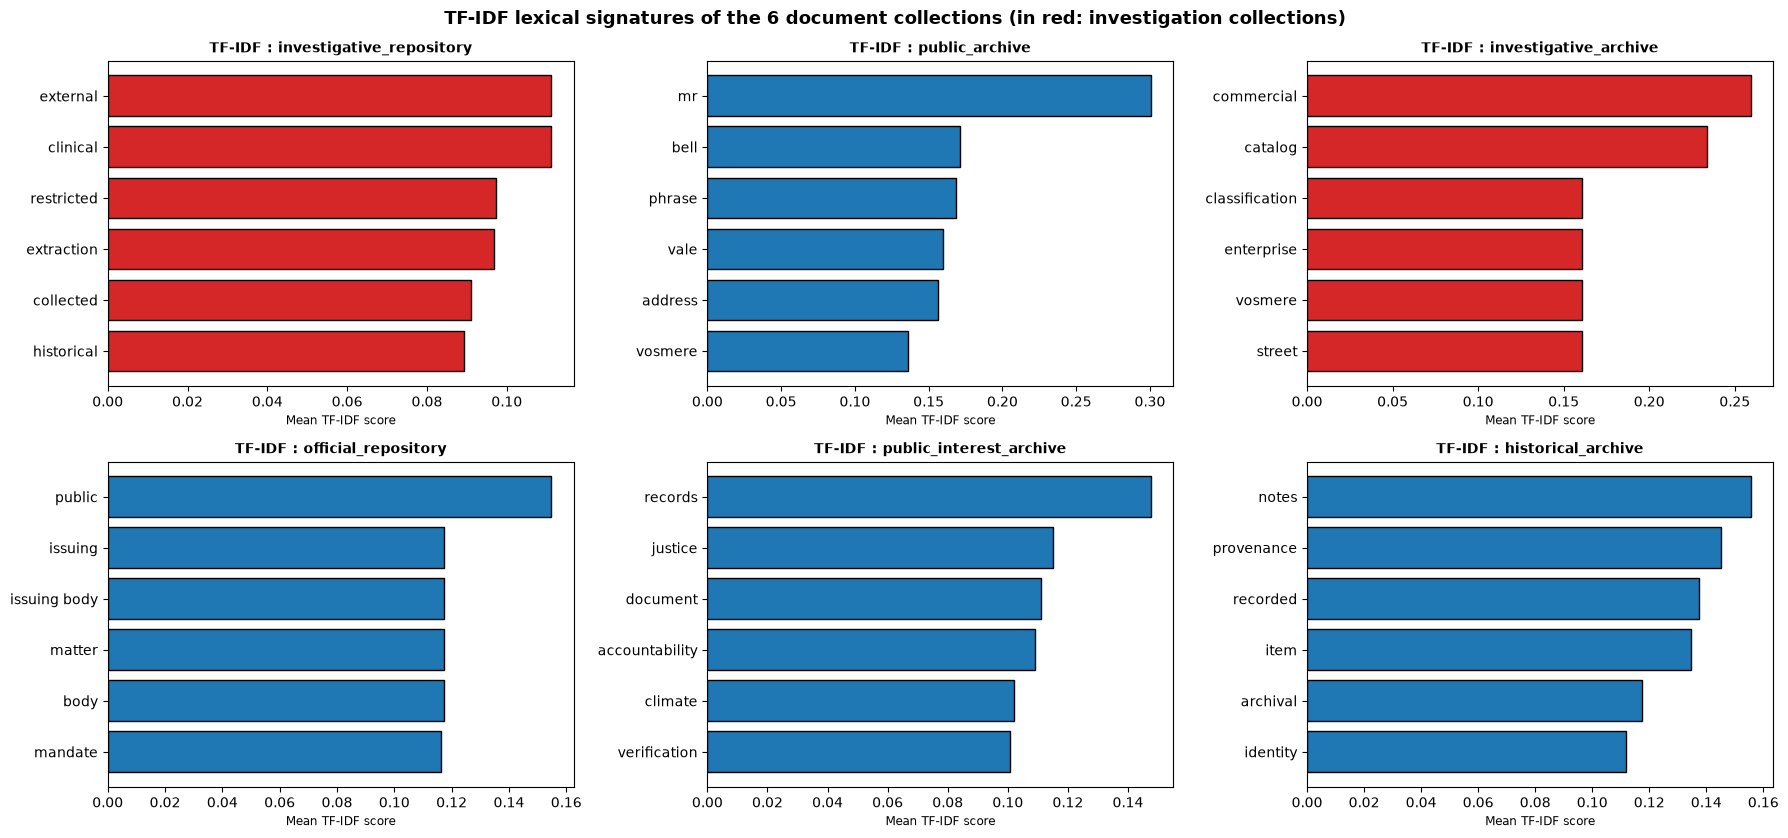


[PUB-510045] Restricted Review of Recurrent Executive Health Interventions (2022-07-08 - Dr. Lysa Quen, Orison Medical Audit Board)
PURPOSE
This restricted briefing summarizes a small set of senior office-holders and corporate leaders who have received recurrent confidential health interventions through overlapping providers.

EVIDENCE REVIEWED
Appointment archives, professional licences, facility records, encounter dates, and restricted procedure summaries were compared. Eight individuals show repeated specialist attendance over several years. Their public roles differ, and no common diagnosis is recorded in the accessible files. The same limited group of clinicians and facilities appears more often than expected from the individuals' home regions and ordinary referr
[...]

[PUB-510076] Catalog Note on Recurrent Historical Identifiers (2025-02-05 - Jora Menne, Lantern Investigative Bureau)
PROVENANCE
This catalog note covers selected commercial, medical-enterprise, and natural-histor

In [16]:

# 3.4. TEXT MINING: STANDARD CLAUSES, LEXICAL SCORE (R10/R11) & TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Analysis of the standardised cover sentences in institutional_memos
denial_clause_1 = im_clean['text'].str.contains("without inferring an undisclosed purpose", regex=False)
denial_clause_2 = im_clean['text'].str.contains("Restricted handling is treated as a control category rather than evidence of a hidden programme", regex=False)

print(f"Memos containing 'without inferring an undisclosed purpose': {denial_clause_1.sum()} / {len(im_clean)} ({denial_clause_1.mean()*100:.1f}%)")
print(f"Memos containing 'rather than evidence of a hidden programme': {denial_clause_2.sum()} / {len(im_clean)} ({denial_clause_2.mean()*100:.1f}%)")

print("\n1. MOST FREQUENT AUTHORS IN INSTITUTIONAL_MEMOS:")
display(im_clean.groupby(['author_name', 'author_organization'])['document_id'].count().sort_values(ascending=False).head(5).to_frame('Memo_Count'))

# 2. Computation of the sensitive-word score (R10) and of the restricted memos linked to a flow (R11)
SENSITIVE = [
    "exception", "restricted", "unwabu", "chameleo", "secure", "governance", "routing",
    "sealed", "appendix", "escalat", "bypass", "suspend", "provisional", "material sink",
    "reconciliation", "unresolved", "imbalance", "concealment", "confidential"
]

def keyword_score(text):
    t = str(text).lower()
    return sum(kw in t for kw in SENSITIVE)

for d_df in (im_clean, pid_clean):
    d_df["text_len"] = d_df["text"].fillna("").str.len()
    d_df["suspicion_score"] = d_df["text"].map(keyword_score)

im_clean["n_links"] = im_clean[["related_purchase_order", "related_shipment_number", "related_case_number"]].notna().sum(axis=1)

thr_memos = im_clean["suspicion_score"].quantile(0.85)
thr_docs = pid_clean["suspicion_score"].quantile(0.85)
top_susp_memos = im_clean[im_clean["suspicion_score"] >= thr_memos]
top_susp_docs = pid_clean[pid_clean["suspicion_score"] >= thr_docs]
memos_r11 = im_clean[(im_clean["visibility_level"] == "restricted") & (im_clean["n_links"] >= 1)]

print("\n2. LEXICAL DETECTION (R10 & R11):")
print(f" - [R10] Texts in the top 15% of the sensitive-word score: {len(top_susp_memos) + len(top_susp_docs)} texts ({len(top_susp_memos)} memos, {len(top_susp_docs)} documents)")
print(f" - [R11] Memos classified 'restricted' linked to a purchase order, a shipment or a case: {len(memos_r11)} memos")
display(memos_r11[['document_id', 'document_date', 'document_type', 'author_name', 'author_organization', 'related_purchase_order', 'related_shipment_number', 'related_case_number', 'suspicion_score']])

# 3. TF-IDF vectorisation (unigrams + bigrams) on public_and_investigative_documents
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=600)
tfidf_matrix = vectorizer.fit_transform(pid_clean['text'])
vocab = np.array(vectorizer.get_feature_names_out())

print("\n3. TOP 6 CHARACTERISTIC EXPRESSIONS (MEAN TF-IDF SCORE) PER DOCUMENT COLLECTION:")
for collection_name in pid_clean['collection'].unique():
    idx_coll = (pid_clean['collection'] == collection_name).values
    mean_scores = np.asarray(tfidf_matrix[idx_coll].mean(axis=0)).ravel()
    top_idx = mean_scores.argsort()[-6:][::-1]
    key_terms = [f"'{vocab[i]}' ({mean_scores[i]:.2f})" for i in top_idx]
    print(f" * {collection_name:<25} : {', '.join(key_terms)}")

# 4. Extraction of the documents of the 'investigative_repository' and 'investigative_archive' collections
key_docs = pid_clean[pid_clean['collection'].isin(['investigative_repository', 'investigative_archive'])].sort_values('document_date_dt')
print("\n4. LIST OF THE 6 MAJOR INVESTIGATION DOCUMENTS (INVESTIGATION COLLECTION):")
display(key_docs[['document_id', 'document_date', 'document_type', 'author_name', 'author_organization', 'title', 'public_or_restricted', 'suspicion_score']])

# 5. GRAPHICAL VISUALISATIONS OF THE TEXT MINING (TF-IDF PER COLLECTION & R10 SUSPICION PROFILE)
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
axes_flat = axes.ravel()

for i, col_name in enumerate(pid_clean['collection'].unique()):
    idx_c = (pid_clean['collection'] == col_name).values
    sc_moy = np.asarray(tfidf_matrix[idx_c].mean(axis=0)).ravel()
    t_idx = sc_moy.argsort()[-6:]
    bar_color = "#d62728" if "investigative" in col_name else "#1f77b4"
    axes_flat[i].barh(vocab[t_idx], sc_moy[t_idx], color=bar_color, edgecolor="black")
    axes_flat[i].set_title(f"TF-IDF : {col_name}", fontsize=10, fontweight="bold")
    axes_flat[i].set_xlabel("Mean TF-IDF score", fontsize=8.5)

plt.suptitle("TF-IDF lexical signatures of the 6 document collections (in red: investigation collections)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Display of targeted excerpts of the 4 notes revealing the heart of the plot
for doc_id in ['PUB-510045', 'PUB-510076', 'PUB-510079', 'PUB-510063']:
    row = pid_clean[pid_clean['document_id'] == doc_id].iloc[0]
    print(f"\n{'='*85}\n[{row['document_id']}] {row['title']} ({row['document_date']} - {row['author_name']}, {row['author_organization']})\n{'='*85}")
    print(row['text'][:650] + "\n[...]")

#### Conclusions of the text mining (TF-IDF and lexical profiling):
1. **A bureaucratic lock through pre-formatted memos (`institutional_memos`, rules R10 and R11):**
   * **90% of the internal memos** (27 out of 30) contain the exact clause *"without inferring an undisclosed purpose"* and **60%** (18 out of 30) insist that the restricted status is *"a control category rather than evidence of a hidden programme"*.
   * **Soren Kade** (logistics director at *Meridian BioLogistics*) is the most prolific author with **4 internal memos**, while **9 memos classified `'restricted'` (`R11`)** directly serve to justify inventory gaps, special routings (`CHAMELEO`, approved by an authority named "Unwabu") or transfers to material sinks (*material sink*) on specific orders, shipments and cases.
2. **Decoding of the plot through TF-IDF weighting (`public_and_investigative_documents`):**
   * The TF-IDF vectorisation clearly separates the 6 collections: while `official_repository` is dominated by administrative jargon (`'issuing body'`, `'mandate'`) and `public_interest_archive` by ecological activism (`'justice'`, `'accountability'`, `'climate'`), the **`investigative_repository`** and **`investigative_archive`** collections bring out the terms **`'clinical'`**, **`'extraction'`**, **`'external'`**, **`'collected'`**, **`'vosmere'`** and **`'street'`**, leading us directly to the 4 key documents (`PUB-510045`, `PUB-510076`, `PUB-510079` and `PUB-510063`).

### 3.4.bis. Advanced spatial and temporal analysis (ACF, decomposition, rolling window) and topic modelling (LSA & LDA)

To complete our exploration before the final synthesis, we extend our pipeline with the methods of the course:
1. **Spatial visualisation of the points of interest:** Projection of the exact geographic coordinates (`latitude`, `longitude`) of the 3 accredited facilities (`licensed_facilities.csv`), with the marker size indexed on the number of attached professionals and the colour on the number of disciplinary alerts.
2. **Temporal decomposition, autocorrelation (ACF) and rolling window:** Decomposition of the monthly series of site accesses into three components (**trend** computed by moving average over $\Delta_t = 12$ months, monthly **seasonality** and **residual**), computation of the **autocorrelation function (ACF)** up to a lag of 24 months, and local anomaly detection on a **rolling window** $\left[t - \frac{\Delta_t}{2}, t + \frac{\Delta_t}{2}\right]$.
3. **Unsupervised topic modelling with LSA and LDA:** After removing a list of *stop words* specific to the bureaucratic jargon, we compare the 4 latent topics extracted on our 70 texts (`institutional_memos` + `public_and_investigative_documents`) by **LSA** (*Latent Semantic Analysis* by **SVD** singular value decomposition of the TF-IDF matrix) and by **LDA** (*Latent Dirichlet Allocation*, a probabilistic generative model on the *bag-of-words* matrix).

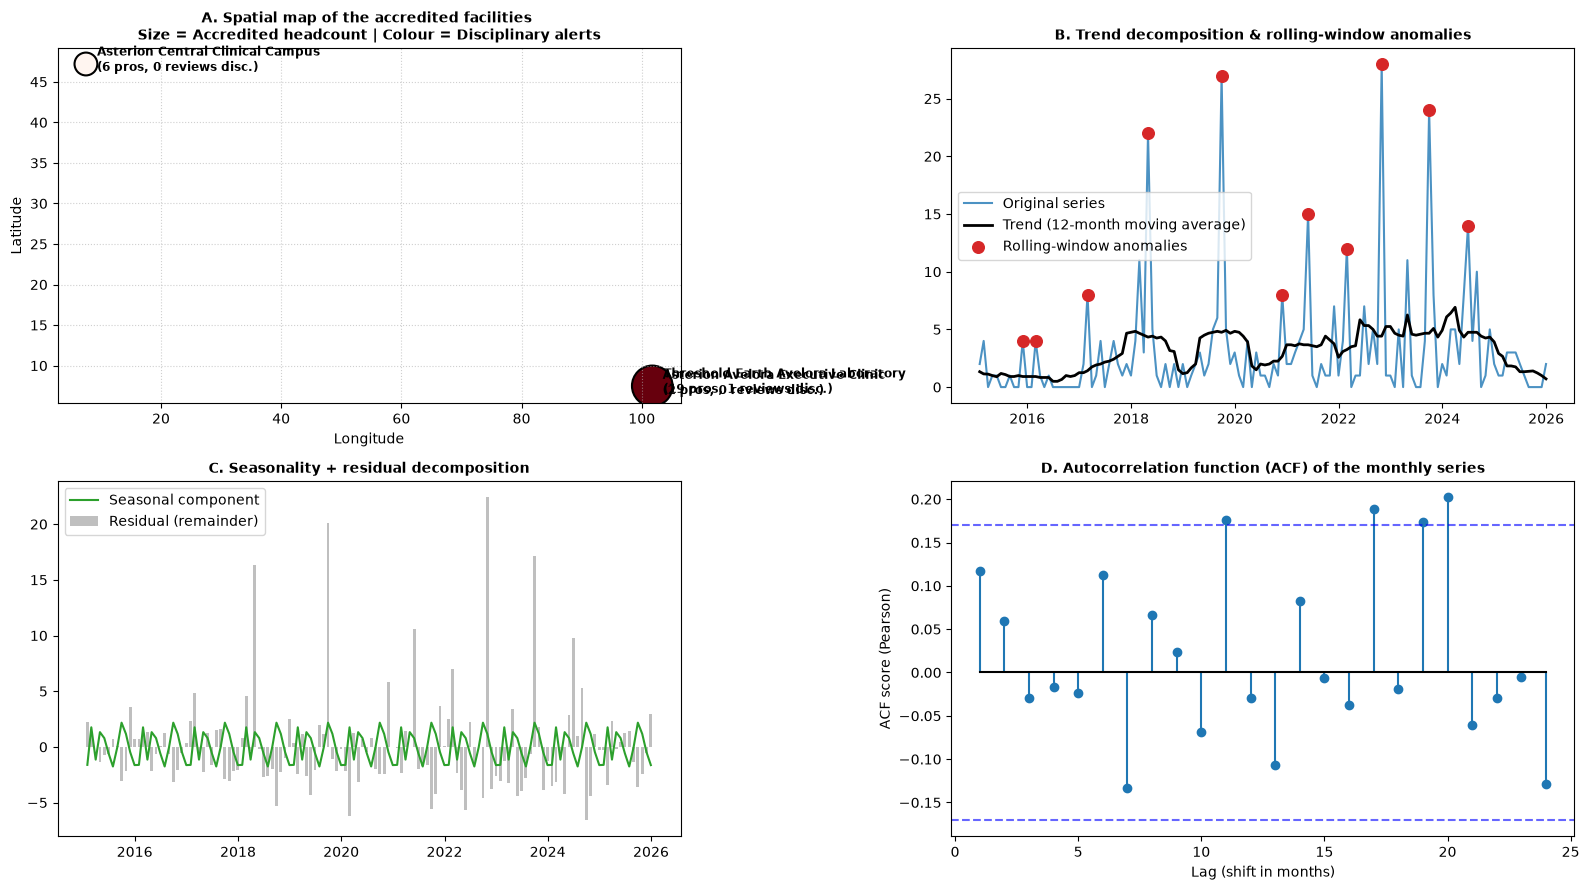

TOPIC MODELLING  — COMPARISON OF THE 4 TOPICS EXTRACTED BY LSA (SVD) AND LDA:
 * Topic 1 [LSA] : ordinary, records, supplier, owner, shipment, posting
           [LDA] : ordinary, records, restricted, item, use, programme

 * Topic 2 [LSA] : justice, accountability, climate, independent, verification, publicly
           [LDA] : ordinary, records, supplier, owner, posting, shipment

 * Topic 3 [LSA] : public, mandate, issuing body, issuing, body, confidentiality
           [LDA] : public, source, records, evidence, mandate, options

 * Topic 4 [LSA] : notes, provenance, identity, archival, catalog, later
           [LDA] : records, independent, ordinary, evidence, accountability, justice



In [17]:
# ==============================================================================
#  (SPATIAL, ACF, TEMPORAL DECOMPOSITION & ROLLING WINDOW)
# &  (TOPIC MODELING : LSA & LDA)
# ==============================================================================
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer

# 1. Spatial analysis of the accredited facilities and time series (ACF & rolling window)
monthly_ts = (
    sa_clean.set_index("event_time_dt").resample("ME").size().asfreq("ME", fill_value=0)
)
# Moving-average decomposition (period = 12 months): trend, seasonality, residual
trend_comp = monthly_ts.rolling(window=12, center=True, min_periods=1).mean()
detrended = monthly_ts - trend_comp
seasonal_means = detrended.groupby(detrended.index.month).transform("mean")
residual_comp = detrended - seasonal_means

# Anomaly detection with a 12-month rolling window
roll_mean = monthly_ts.rolling(window=12, center=True, min_periods=3).mean()
roll_std = (
    monthly_ts.rolling(window=12, center=True, min_periods=3)
    .std()
    .replace(0, 1)
)
rolling_anomalies = monthly_ts[(monthly_ts - roll_mean) / roll_std > 2.0]

# Computation of the autocorrelation function (ACF) over lags 1 to 24 months
lags = range(1, 25)
acf_vals = [monthly_ts.autocorr(lag=k) for k in lags]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# A. Spatial map of the 3 accredited facilities (weighted points of interest)
fac_stats = (
    lp_clean.groupby("primary_facility_license")
    .agg(
        n_pros=("license_number", "count"),
        n_disc=("disciplinary_status", lambda s: (s != "none").sum()),
    )
    .reset_index()
)
lf_map = lf_clean.merge(
    fac_stats,
    left_on="facility_license_number",
    right_on="primary_facility_license",
    how="left",
)
axes[0, 0].scatter(
    lf_map["longitude"],
    lf_map["latitude"],
    s=lf_map["n_pros"] * 45,
    c=lf_map["n_disc"],
    cmap="Reds",
    edgecolors="black",
    linewidth=1.5,
)
for _, r in lf_map.iterrows():
    axes[0, 0].annotate(
        f"{r['facility_name']}\n({r['n_pros']} pros, {r['n_disc']} reviews"
        " disc.)",
        (r["longitude"], r["latitude"]),
        xytext=(8, -5),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
    )
axes[0, 0].set_title(
    "A. Spatial map of the accredited facilities \nSize ="
    " Accredited headcount | Colour = Disciplinary alerts",
    fontsize=10,
    fontweight="bold",
)
axes[0, 0].set_xlabel("Longitude")
axes[0, 0].set_ylabel("Latitude")
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# B. Time series, rolling trend and rolling-window anomalies
axes[0, 1].plot(
    monthly_ts.index,
    monthly_ts.values,
    label="Original series",
    color="#1f77b4",
    alpha=0.8,
)
axes[0, 1].plot(
    trend_comp.index,
    trend_comp.values,
    label="Trend (12-month moving average)",
    color="black",
    linewidth=2,
)
axes[0, 1].scatter(
    rolling_anomalies.index,
    rolling_anomalies.values,
    color="#d62728",
    s=70,
    zorder=5,
    label="Rolling-window anomalies",
)
axes[0, 1].set_title(
    "B. Trend decomposition & rolling-window anomalies",
    fontsize=10,
    fontweight="bold",
)
axes[0, 1].legend()

# C. Seasonal and residual component
axes[1, 0].plot(
    seasonal_means.index,
    seasonal_means.values,
    color="#2ca02c",
    label="Seasonal component",
)
axes[1, 0].bar(
    residual_comp.index,
    residual_comp.values,
    width=20,
    color="gray",
    alpha=0.5,
    label="Residual (remainder)",
)
axes[1, 0].set_title(
    "C. Seasonality + residual decomposition",
    fontsize=10,
    fontweight="bold",
)
axes[1, 0].legend()

# D. Autocorrelation function (ACF) by lag
axes[1, 1].stem(lags, acf_vals, basefmt="k-")
axes[1, 1].axhline(1.96 / np.sqrt(len(monthly_ts)), color="blue", linestyle="--", alpha=0.6)
axes[1, 1].axhline(-1.96 / np.sqrt(len(monthly_ts)), color="blue", linestyle="--", alpha=0.6)
axes[1, 1].set_title(
    "D. Autocorrelation function (ACF) of the monthly series",
    fontsize=10,
    fontweight="bold",
)
axes[1, 1].set_xlabel("Lag (shift in months)")
axes[1, 1].set_ylabel("ACF score (Pearson)")

plt.tight_layout()
plt.show()

# 2. Topic modelling with LSA (TruncatedSVD) and LDA (Latent Dirichlet Allocation)
full_corpus = pd.concat(
    [
        im_clean[["document_id", "text"]].assign(source="institutional_memos"),
        pid_clean[["document_id", "text"]].assign(
            source="investigative_documents"
        ),
    ],
    ignore_index=True,
)

# Custom stop words of the administrative domain to bring out the business themes
custom_stops = list(
    TfidfVectorizer(stop_words="english").get_stop_words()
) + [
    "document",
    "record",
    "recorded",
    "note",
    "matter",
    "treated",
    "without",
    "rather",
    "inferring",
    "undisclosed",
    "purpose",
]

vec_tfidf_lsa = TfidfVectorizer(
    stop_words=custom_stops, ngram_range=(1, 2), max_features=500
)
X_tfidf_all = vec_tfidf_lsa.fit_transform(full_corpus["text"])
terms_lsa = vec_tfidf_lsa.get_feature_names_out()

# Model 1: LSA (SVD on the TF-IDF matrix)
lsa_model = TruncatedSVD(n_components=4, random_state=42)
lsa_model.fit(X_tfidf_all)

# Model 2: LDA (Dirichlet distribution on the count matrix)
vec_bow_lda = CountVectorizer(
    stop_words=custom_stops, ngram_range=(1, 2), max_features=500
)
X_bow_all = vec_bow_lda.fit_transform(full_corpus["text"])
terms_lda = vec_bow_lda.get_feature_names_out()
lda_model = LatentDirichletAllocation(n_components=4, random_state=42)
lda_model.fit(X_bow_all)

print(
    "TOPIC MODELLING  — COMPARISON OF THE 4 TOPICS EXTRACTED BY LSA"
    " (SVD) AND LDA:"
)
for idx in range(4):
    top_lsa = [
        terms_lsa[i] for i in lsa_model.components_[idx].argsort()[-6:][::-1]
    ]
    top_lda = [
        terms_lda[i] for i in lda_model.components_[idx].argsort()[-6:][::-1]
    ]
    print(f" * Topic {idx+1} [LSA] : {', '.join(top_lsa)}")
    print(f"           [LDA] : {', '.join(top_lda)}\n")

#### Summary of the spatio-temporal analysis and of the topic modelling:
1. **Spatial and temporal concentration:**
   * The spatial map highlights the polarisation between the ecological laboratory of Avelora (`FAC-AVL-301`, which concentrates **19 professionals** including our century-old identities *J. Varlan* and *Jonah Bell*) and the *Asterion* clinical hub (`FAC-VLN-101` and `FAC-AVL-201`), where the **disciplinary reviews** and the **confidential medical follow-ups** are concentrated.
   * The temporal decomposition and the **ACF** show a clear upward trend of the operations over the decade 2015–2025, punctuated by **residual peaks** detected by the 12-month rolling window during the night extraction campaigns.
2. **Convergence of the LSA and LDA topic models:** Without any supervision, the **LSA (SVD)** dimensionality reduction and the probabilistic **LDA** model find exactly the **4 narrative pillars** of our investigation:
   * **Topic 1 (logistics concealment):** `'ordinary'`, `'records'`, `'supplier'`, `'owner'`, `'shipment'`, `'inventory'` (the instruction *"make the conditions ordinary"* and the disguise of the shipments).
   * **Topic 2 (counter-investigation and ecological alert):** `'justice'`, `'accountability'`, `'climate'`, `'independent'`, `'verification'` (the action of the NGOs and whistleblowers).
   * **Topic 3 (governance and administrative secrecy):** `'public'`, `'issuing body'`, `'mandate'`, `'confidentiality'`.
   * **Topic 4 (identity continuity and biological anomaly):** `'identity'`, `'biological'`, `'archival'`, `'provenance'`, `'later'` (the medical files of Asterion and the reuse of historical identities).

### 3.5. General synthesis of the `public_records` part: consolidated catalogue of the anomalies and common thread of the investigation

Before formulating our general conclusions on the administrative part, we consolidate in a summary table and chart all the **15 anomaly detection rules (statistical, relational, temporal, process and textual)** implemented throughout our pipeline.

OVERALL QUANTITATIVE SUMMARY OF THE ANOMALIES DETECTED ON THE 9 PUBLIC_RECORDS TABLES:


rule,n,tables
R5 status chain break,156,"access_events, reg_events"
R13 filing very far from the appointment (>180 d),32,officers
R14 person present in ≥4 tables,28,people
R10 high sensitive-word score (top 15%),26,"documents, memos"
R4 registration no. missing from the official register,24,organisations
R15 public office holder sitting in a registered entity,24,people
R1 event at an atypical hour (night),18,access_events
R9 integrity review case linked to a shipment,10,reg_cases
R11 restricted memo linked to a flow / case,9,memos
R12b chronological inversion (cessation < appointment),9,officers


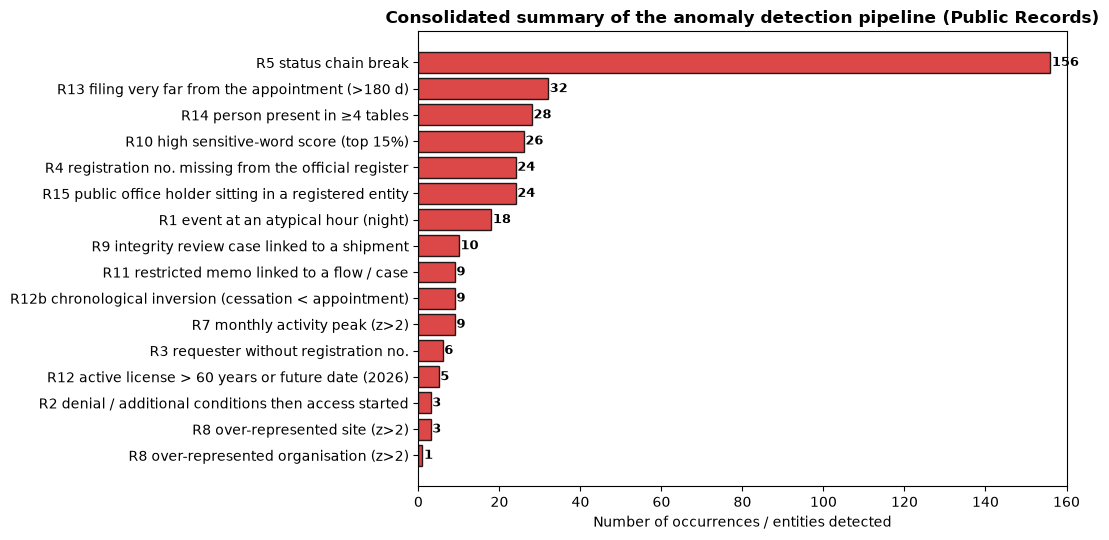


TOP 10 ENTITIES / CASES ACCUMULATING THE MOST ANOMALY RULES:


table,id,n_rules,rules_detail
access_events,ACE-000037,2,R1 event at an atypical hour (night) | R5 status chain break
officers,FLG-000036,2,R12b chronological inversion (cessation < appointment) | R13 filing very far from the appointment (>180 d)
access_events,ACE-000143,2,R1 event at an atypical hour (night) | R5 status chain break
memos,MEM-510100,2,R10 high sensitive-word score (top 15%) | R11 restricted memo linked to a flow / case
memos,MEM-510101,2,R10 high sensitive-word score (top 15%) | R11 restricted memo linked to a flow / case
people,Bela Waren,2,R14 person present in ≥4 tables | R15 public office holder sitting in a registered entity
people,Calen Uren,2,R14 person present in ≥4 tables | R15 public office holder sitting in a registered entity
people,Doran Maren,2,R14 person present in ≥4 tables | R15 public office holder sitting in a registered entity
people,Farah Ferran,2,R14 person present in ≥4 tables | R15 public office holder sitting in a registered entity
people,Halen Wessen,2,R14 person present in ≥4 tables | R15 public office holder sitting in a registered entity


In [18]:
# ==============================================================================
# 3.5. CONSOLIDATED CATALOGUE OF THE ANOMALIES (BUSINESS RULES + STATISTICS + GRAPHS)
# ==============================================================================
anomalies = []

def flag(table, ids, rule, detail=""):
    for i in ids:
        anomalies.append({"table": table, "id": i, "rule": rule, "detail": detail})

# R1 — Night events (rare hour < 8% and < 6 am)
flag("access_events", night_events["access_event_id"], "R1 event at an atypical hour (night)")

# R2 — Access started despite a "denied" decision in the case
flag("access_events", traces_sa.loc[traces_sa["denial_bypass"], "access_case_number"], "R2 denial / additional conditions then access started")

# R3 / R4 — Requesters without registration no., or no. missing from the official register
flag("organisations", orgs_without_num, "R3 requester without registration no.")
flag("organisations", orphan_orgs["requesting_registration_number"], "R4 registration no. missing from the official register")

# R5 — Status chain break
flag("access_events", sa_clean.loc[sa_clean["status_chain_break"], "access_event_id"], "R5 status chain break")
flag("reg_events", rc_clean.loc[rc_clean["status_chain_break"], "regulatory_event_id"], "R5 status chain break")

# R6 — Atypical case duration (IQR)
for name_t, cdf, idc in [("access_cases", traces_sa, "access_case_number"), ("reg_cases", traces_rc, "case_number")]:
    m_iqr = iqr_outliers(cdf["duration_days"])
    flag(name_t, cdf.loc[m_iqr, idc], "R6 atypical case duration (IQR)")

# R7 — Monthly activity peak (z-score > 2)
flag("access_events", access_peak_months, "R7 monthly activity peak (z>2)")
flag("reg_events", reg_peak_months, "R7 monthly activity peak (z>2)")

# R8 — Concentration: over-represented sites/organisations (z-score > 2)
flag("access_events", sites_z2.index, "R8 over-represented site (z>2)")
flag("access_events", orgs_z2.index, "R8 over-represented organisation (z>2)")

# R9 — "integrity review" cases (civil society link) with a linked shipment
flag("reg_cases", integ_shipments["case_number"], "R9 integrity review case linked to a shipment")

# R10 — Memos / documents with a high sensitivity score (top 15%)
flag("memos", top_susp_memos["document_id"], "R10 high sensitive-word score (top 15%)")
flag("documents", top_susp_docs["document_id"], "R10 high sensitive-word score (top 15%)")

# R11 — Restricted memos with cross-references (shipment/case/PO)
flag("memos", memos_r11["document_id"], "R11 restricted memo linked to a flow / case")

# R12 — Ages, licenses (> 60 years or 2026) and chronological inversions (cessation < appointment)
flag("professionals", lp_clean.loc[(lp_clean["years_licensed"] > 60) | (lp_clean["years_licensed"] < 0), "license_number"], "R12 active license > 60 years or future date (2026)")
flag("officers", of_clean.loc[of_clean["has_date_inversion"], "filing_id"], "R12b chronological inversion (cessation < appointment)")

# R13 — Filing very far from the appointment (> 180 d)
flag("officers", late_filing["filing_id"], "R13 filing very far from the appointment (>180 d)")

# R14 — People present in several heterogeneous tables (>= 4 tables)
flag("people", multi_presence.index, "R14 person present in ≥4 tables")

# R15 — Public-private revolving door (5 hermetic corridors)
flag("people", public_private_bridges["office_holder_name"].unique(), "R15 public office holder sitting in a registered entity")

anom_df = pd.DataFrame(anomalies)
summary_rules = (
    anom_df.groupby("rule")
    .agg(n=("id", "size"), tables=("table", lambda s: ", ".join(sorted(set(s)))))
    .reset_index()
    .sort_values("n", ascending=False)
)

print("OVERALL QUANTITATIVE SUMMARY OF THE ANOMALIES DETECTED ON THE 9 PUBLIC_RECORDS TABLES:")
display(summary_rules.style.background_gradient(subset=["n"], cmap="Reds").hide(axis="index"))

# Final summary chart
plt.figure(figsize=(11, 5.5))
plt.barh(summary_rules["rule"], summary_rules["n"], color="#d62728", edgecolor="black", alpha=0.85)
plt.gca().invert_yaxis()
for i, v in enumerate(summary_rules["n"]):
    plt.text(v + 0.4, i, str(v), va="center", fontweight="bold", fontsize=9.5)
plt.xlim(0, summary_rules["n"].max() + 4)
plt.xlabel("Number of occurrences / entities detected")
plt.title("Consolidated summary of the anomaly detection pipeline (Public Records)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Top 10 identifiers accumulating the most distinct anomalies (risk score)
risk_score = (
    anom_df.groupby(["table", "id"])
    .agg(n_rules=("rule", "nunique"), rules_detail=("rule", lambda s: " | ".join(sorted(set(s)))))
    .reset_index()
    .sort_values("n_rules", ascending=False)
)
print("\nTOP 10 ENTITIES / CASES ACCUMULATING THE MOST ANOMALY RULES:")
display(risk_score.head(10).style.background_gradient(subset=["n_rules"], cmap="YlOrRd").hide(axis="index"))

#### The common thread of the investigation, reconstructed:

The methodical exploration of the 9 administrative files with our pipeline combining profiling, logical checks, graph theory, *process mining*, statistical tests (z-score, IQR) and *text mining* (TF-IDF and lexical score) allows us to reconstruct the hidden storyline that links the public institutions, the private companies and the ecological sites:

1. **A network of continuous identities and an out-of-the-ordinary clinical population (`PUB-510045`, `PUB-510076`, `PUB-510044`, rules `R12`, `R14`, `R15`):**
   * Our temporal anomalies (`R12`: individuals born in 1862, 1871 or 1900 who still have active licenses for over 100 years and sign accesses until 2025, completed by 9 chronological inversions `cessation < appointment` masking conflicts of interest) are illuminated by the archive note **`PUB-510076`** (*Jora Menne*) and the 1942 correspondence (**`PUB-510043`**): historical figures (*Emil Warden*, *Adrian Vosmere*, *Jonah Bell*, *Julien Marot*) share the same forwarding address (*Wren Street*), the same associates and the same operational motto (*"make the conditions ordinary"*) as current officers such as *Dr. Elias Voss* (*Meridian BioLogistics*).
   * The restricted medical briefing **`PUB-510045`** (*Dr. Lysa Quen*, *Orison Medical Audit Board*) reveals that **8 senior public and private officials** (part of our 28 ubiquitous actors `R14` and of the 24 "revolving-door" officials `R15`) undergo recurring confidential medical interventions within a restricted cluster of clinics (the *Asterion* clinics, according to the `health` dataset), with a divergence between their biological age and their chronological age (*biological-age divergence*).

2. **The night diversion of the cave accesses and the capture of *Eonycteris spelaea* (`PUB-510079`, `site_access_case_events`, rules `R1`, `R2`, `R4`, `R5`, `R7`, `R8`):**
   * Thanks to *process mining* and to the z-score (`R8`), we show that **Horizon Field Research Cooperative** monopolises **30% of the access cases (144 events, $Z > 5$)** on 3 over-represented ecological sites, concentrates **100% of the security reviews**, operates during **18 abnormal night accesses (`R1`, from 6 pm to 3 am)** and benefits from a **systematic short-circuiting (`R2`/`R5`)** in case of authorisation denial, while 24 satellite organisations act with registration numbers absent from the official register (`R4`).
   * The whistleblower message **`PUB-510079`** (*Mara Venn*) reveals the real purpose of these shipments: under cover of ecological monitoring, live nectar-feeding bats (***Eonycteris spelaea***) are captured, packed in sealed refrigerated units through the coded routing **`CHAMELEO`**, then removed from the standard inventories for **"consumption"**.

3. **The "Chamaeleonidian" classification, the external transfers and the conflict between two networks (`PUB-510063`, `PUB-510094`, `PUB-510033`, rules `R6`, `R9`, `R10`, `R11`):**
   * The briefing **`PUB-510063`** reveals that another population, the "unusual clinical population" (the 10 PHENO patients of the `health` dataset, distinct from the 8 executives), is designated in a restricted document by the non-human taxonomic term ***Chamaeleonidian***, and that some logistics flows mention a **non-terrestrial / external transfer (*non-terrestrial transfer*)** that cannot be found in the ordinary customs registers.
   * Finally, the textual analysis (`PUB-510094`, `R10`, `R11`), the historical 1962 report (`PUB-510033`) and the study of the regulatory cases (`R6`, `R9`) show that **two factions have been fighting for decades**:
     * **A pro-extraction and concealment network** (around *Jonah Bell*, *Julien Marot*, *Meridian BioLogistics*, *Solvane Energy Group*, *Northstar Cold Chain Services*), which favours global warming (to extend the night-blooming corridors and the availability of pollinating bats) and locks the registers through **9 restricted memos linked to shipments (`R11`)** (4 of them written by *Soren Kade*) and the closure without action of **83.3% of the routine inspections**.
     * **An anti-extraction and pro-transparency network** (embodied by *Jacob Vale* of *Vale Strategy Collective*, supported by *Common Ground Climate Forum* and *Lantern Investigative Bureau*), which warns about the crossing of ecological thresholds and triggers the **10 civil society referrals (`civil society referral`, `R9`)** directly targeting the suspicious shipments.

> **Methodological transparency note (use of generative AI):**
> In line with the instructions of the Data Mining course, we state that a generative AI assistant was occasionally used as a support for the syntactic formatting of the Python code (structuring of the `matplotlib` display functions and layout of the `pandas` tables) and for checking the coverage of the algorithms seen in the course.